# Data Challenge PRO Extreme Technologies 2026  

**Autores:** Camilo Mujica, Carlos Romero y Sergio Rada

### Contexto Inicial  

El proyecto se enmarca en la gestión del transporte público colectivo (rutas de Sobusa como Kra 54, Calle 72 y Silencio), donde existe un desequilibrio constante entre la oferta de transporte y la demanda real de pasajeros. El problema central radica en la ineficiencia operativa generada por la sobreoferta (despachar vehículos vacíos que incrementan costos de combustible y desgaste) y la suboferta (generar sobreocupación, demoras excesivas y un servicio deficiente para los usuarios).   

Lo que se desea es construir una solución analítica que procese e integre los datos históricos de demanda con factores operacionales y eventos viales exógenos, para pronosticar con precisión la demanda futura de pasajeros en distintas franjas temporales y calcular la frecuencia óptima de despacho de buses (intervalos entre salidas) y el número de vehículos requeridos, garantizando así una operación eficiente, medible y explicable.

### Objetivos del análisis  

#### Objetivo General  

Optimizar la frecuencia de despacho de vehículos del sistema de transporte público (Sobusa) mediante la predicción de la demanda de pasajeros, mitigando la sobreoferta y la suboferta en la operación del servicio.  

#### Objetivos específicos  

- Identificar patrones, estacionalidades y problemas de calidad del dato mediando un análisis exploratorio de datos (EDA) sobre los registros históricos de demanda y factores operacionales exógenos.  
- Determinar el intervalo de despacho adecuado y la flota de vehículos requerida mediante modelos predictivos de demanda y los algoritmos de optimización de frecuencias.  
- Permitir la consulta interactiva de predicciones, frecuencias optimizadas y alertas operativas mediante la implementación de una aplicación web e interfaz API (FastAPI).  

### Metodología  

ruta KRA 54; modelo base Poisson/GLM con offset log(viajes); modelo adicional LightGBM Poisson/Tweedie con offset; validación walk-forward; horizonte de H = 7 días.


# 1. Extracción de datos

Esta parte prepara todo lo necesario para trabajar con los datos de forma segura: monta el proyecto desde Google Drive, instala las librerías y abre una conexión
a PostgreSQL que **solo permite leer**. Se ejecuta una vez al inicio de cada sesión.  

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
#Instalación de librerías que Colab no trae por defecto.

!pip install -q "psycopg[binary]" python-dotenv pandas numpy matplotlib seaborn folium
!pip install -q lightgbm optuna shap holidays pyarrow

### Conectar a PostgreSQL  

- Las credenciales se leen del `.env` mediante variables de entorno; nunca se escriben
  en el código. La credencial de escritura (`DATABASE_URL_WRITE`) se descarta a propósito.
- La sesión se abre en **modo solo lectura** (`default_transaction_read_only` y
  `read_only=True`), de modo que ninguna celda puede modificar tablas, triggers ni datos.
- Se configuran tiempos límite (`statement_timeout` e `idle_in_transaction_session_timeout`)
  para que una consulta pesada no afecte la base operativa.
- Una prueba automática intenta escribir y debe fallar; si no falla, la ejecución se detiene.
- La conexión usa SSL (`sslmode=require`).


In [3]:
import os
import psycopg
from dotenv import load_dotenv

PROY = '/content/drive/MyDrive/proyecto_sobusa'
DATA = os.path.join(PROY, 'data')
DOCS = os.path.join(PROY, 'docs')

load_dotenv(os.path.join(PROY, '.env'))

# Este notebook nunca debe usar la credencial de escritura
os.environ.pop('DATABASE_URL_WRITE', None)

CONN = psycopg.connect(
    host=os.environ['DB_HOST'], port=os.environ['DB_PORT'],
    dbname=os.environ['DB_NAME'], user=os.environ['DB_USER'],
    password=os.environ['DB_PASSWORD'],
    sslmode='require', connect_timeout=10,
    # Cada transacción de la sesión nace en solo lectura y con timeout
    options='-c default_transaction_read_only=on '
            '-c statement_timeout=300000 '
            '-c idle_in_transaction_session_timeout=600000',
)
CONN.read_only = True      # refuerzo del lado del cliente
CONN.autocommit = True     # sin transacciones abiertas ni "transacción abortada"

# Prueba: debe fallar. Si no falla, detener todo.
try:
    CONN.execute("CREATE TEMP TABLE __ro_test (x int)")
    CONN.execute("CREATE TABLE public.__ro_test (x int)")
    raise SystemExit('PELIGRO: la sesión permite escribir')
except psycopg.errors.ReadOnlySqlTransaction:
    print('OK: la sesión es de solo lectura')
except psycopg.errors.InsufficientPrivilege:
    print('OK: el usuario no tiene permiso de escritura')

print('Conectado a', os.environ['DB_NAME'])

OK: la sesión es de solo lectura
Conectado a dataset


Se consulta la tabla timbradas_anio y se relaciona con rutas para resumir la información de SOBUSA entre 2023 y 2025. Se agrupan los registros por año y ruta, calculando la cantidad de filas y el total de subidas, con el fin de explorar la disponibilidad de datos y comparar la demanda registrada entre rutas y años.

In [4]:
cur = CONN.cursor()
cur.execute("""
    select a.ano, r.nombre, count(*) filas, sum(a.subidas) subidas
    from timbradas_anio a
    join rutas r on r.idruta = a.id_ruta
    where a.proceso = 'sobusa' and a.ano in (2023,2024,2025)
    group by 1,2 order by 1,2
""")
for r in cur.fetchall():
    print(r)
cur.close()

(2023, 'CL 72', 2079, 2711837)
(2023, 'CRA 54', 2835, 8774466)
(2023, 'SILENCIO', 2502, 4280981)
(2024, 'CL 72', 2136, 2628023)
(2024, 'CRA 54', 2867, 8075734)
(2024, 'SILENCIO', 2517, 3885647)
(2025, 'CL 72', 2327, 2390443)
(2025, 'CRA 54', 3106, 7469245)
(2025, 'SILENCIO', 2666, 3578755)


# 2. EDA detallado — Ruta KRA 54 (CRA 54)

Se empezará el análisis exploratorio de datos con una revisión de cada tabla con sus variables, con el fin de tener clara la estructura de la Base de datos.  

In [5]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import seaborn as sns
import folium   # mapas; se instala en la seccion 2


In [6]:
import pandas as pd
from IPython.display import display, Markdown

cols = pd.read_sql("""
    SELECT table_name, column_name, data_type
    FROM information_schema.columns
    WHERE table_schema = 'public'
    ORDER BY table_name, ordinal_position
""", CONN)

SCHEMA = cols.groupby("table_name")["column_name"].apply(list).to_dict()

display(Markdown(f"**{len(SCHEMA)} tablas visibles**"))

schema_table = pd.DataFrame({
    "N.º": range(1, len(SCHEMA) + 1),
    "Tabla": sorted(SCHEMA),
    "Columnas": [len(SCHEMA[t]) for t in sorted(SCHEMA)]
})
display(schema_table)

print("Total de variables:", sum(len(c) for c in SCHEMA.values()))

/tmp/ipykernel_2319/45276514.py:4: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  cols = pd.read_sql("""


**29 tablas visibles**

,N.º,Tabla,Columnas
0,1,Procesos,88
1,2,conteo_pasajeros_destino,25
2,3,dias_semana,2
3,4,estacionalidades,5
4,5,estacionalidades_anio,6
5,6,geography_columns,7
6,7,geometry_columns,7
7,8,novedades_viales,5
8,9,novedades_viales_fecha,8
9,10,novedades_viales_ruta,3


Total de variables: 587


In [14]:
import subprocess
import sys
import os
from pathlib import Path

# Directorio principal del proyecto
PROYECTO = Path("/content/drive/MyDrive/proyecto_sobusa")

# Scripts de Calle 72
SCRIPT_PANEL = PROYECTO / "scripts" / "extraer_panel_cl72.py"
SCRIPT_SERVICIO = PROYECTO / "scripts" / "extraer_servicio_cl72.py"

# Carpeta de resultados
SALIDA = PROYECTO / "data" / "panel_horario_cll72"
SALIDA.mkdir(parents=True, exist_ok=True)

# Verificar existencia
assert SCRIPT_PANEL.exists(), "No se encontró el script del panel"
assert SCRIPT_SERVICIO.exists(), "No se encontró el script del servicio"

# Construir la URL de conexión usando las credenciales cargadas de solo lectura
db_user = os.environ.get('DB_USER')
db_password = os.environ.get('DB_PASSWORD')
db_host = os.environ.get('DB_HOST')
db_port = os.environ.get('DB_PORT')
db_name = os.environ.get('DB_NAME')

database_url = f"postgresql://{db_user}:{db_password}@{db_host}:{db_port}/{db_name}?sslmode=require"

# Configurar entorno para el subproceso
env_completo = os.environ.copy()
env_completo["DATABASE_URL"] = database_url

print("Iniciando extracción de Calle 72")
print("Período: enero 2023 - agosto 2025")
print("Destino:", SALIDA)

# 1. Extraer panel
print("\n========== EXTRAYENDO PANEL ==========\n")
res_panel = subprocess.run(
    [sys.executable, str(SCRIPT_PANEL)],
    cwd=str(PROYECTO),
    env=env_completo,
    capture_output=True,
    text=True
)
print("STDOUT PANEL:", res_panel.stdout)
print("STDERR PANEL:", res_panel.stderr)
if res_panel.returncode != 0:
    raise RuntimeError("Error al extraer el panel de la calle 72.")

# 2. Extraer servicio
print("\n========== EXTRAYENDO SERVICIO ==========\n")
res_servicio = subprocess.run(
    [sys.executable, str(SCRIPT_SERVICIO)],
    cwd=str(PROYECTO),
    env=env_completo,
    capture_output=True,
    text=True
)
print("STDOUT SERVICIO:", res_servicio.stdout)
print("STDERR SERVICIO:", res_servicio.stderr)
if res_servicio.returncode != 0:
    raise RuntimeError("Error al extraer el servicio de la calle 72.")

print("\nExtracción finalizada exitosamente.")

Iniciando extracción de Calle 72
Período: enero 2023 - agosto 2025
Destino: /content/drive/MyDrive/proyecto_sobusa/data/panel_horario_cll72

========== EXTRAYENDO PANEL ==========

STDOUT PANEL: OK 2023-01  celdas=  5868  subidas=   17163  (10.9s)
OK 2023-02  celdas=  5318  subidas=   17401  (9.7s)
OK 2023-03  celdas=  5989  subidas=   20477  (10.9s)
OK 2023-04  celdas=  5684  subidas=   17502  (9.0s)
OK 2023-05  celdas=  5973  subidas=   18867  (11.4s)
OK 2023-06  celdas=  5763  subidas=   16375  (12.6s)
OK 2023-07  celdas=  6023  subidas=   17422  (10.4s)
OK 2023-08  celdas=  5962  subidas=   18407  (13.2s)
OK 2023-09  celdas=  5832  subidas=   17604  (12.7s)
OK 2023-10  celdas=  5946  subidas=   17229  (14.8s)
OK 2023-11  celdas=  5821  subidas=   17379  (11.5s)
OK 2023-12  celdas=  5934  subidas=   16433  (11.0s)
OK 2024-01  celdas=  5818  subidas=   16028  (12.1s)
OK 2024-02  celdas=  5529  subidas=   17622  (15.2s)
OK 2024-03  celdas=  5877  subidas=   17330  (10.5s)
OK 2024-04  

Tenemos un total 29 tablas y 587 variables generales en total.   

### Análisis de cada tabla  

Se verá información relevante de cada tabla como dimensión, columnas, tipos de datos, datos nulos, datos atípicos y cuales variables es adecuado utilizar y cuales no.  

In [7]:
import numpy as np
import pandas as pd
from psycopg import sql
from IPython.display import display, Markdown

def consulta(query, params=None):
    with CONN.cursor() as cur:
        cur.execute(query, params)
        return pd.DataFrame(cur.fetchall(), columns=[d.name for d in cur.description])

COLS_DB = consulta("""
    SELECT table_name, column_name, data_type, udt_name
    FROM information_schema.columns
    WHERE table_schema = 'public'
    ORDER BY table_name, ordinal_position
""")

CATALOGO = consulta("""
    SELECT c.relname AS tabla,
           c.relkind,
           c.reltuples::bigint AS filas_estimadas,
           pg_relation_size(c.oid) AS bytes_tabla,   -- tamaño real actual, no depende de ANALYZE
           pg_size_pretty(pg_total_relation_size(c.oid)) AS tamano
    FROM pg_class c
    JOIN pg_namespace n ON n.oid = c.relnamespace
    WHERE n.nspname = 'public' AND c.relkind IN ('r', 'p')
    ORDER BY c.relname
""").set_index('tabla')
CATALOGO['columnas'] = COLS_DB.groupby('table_name').size().reindex(CATALOGO.index)

UMBRAL_EXACTO = 200 * 1024**2   # hasta 200 MB se cuenta exacto

def contar(tabla):
    with CONN.cursor() as cur:
        cur.execute(sql.SQL("SELECT count(*) FROM {}").format(sql.Identifier(tabla)))
        return cur.fetchone()[0]

filas, conteo = [], []
for t, r in CATALOGO.iterrows():
    if r.relkind == 'r' and r.bytes_tabla <= UMBRAL_EXACTO:
        filas.append(contar(t)); conteo.append('exacto')
    else:
        filas.append(r.filas_estimadas); conteo.append('estimado')
CATALOGO['filas'] = filas
CATALOGO['conteo'] = conteo

display(CATALOGO[['filas', 'conteo', 'columnas', 'tamano']])

,filas,conteo,columnas,tamano
tabla,,,,
Procesos,1,exacto,88,32 kB
conteo_pasajeros_destino,175855824,estimado,25,43 GB
dias_semana,7,exacto,2,40 kB
estacionalidades,24,exacto,5,32 kB
estacionalidades_anio,231,exacto,6,64 kB
novedades_viales,59,exacto,5,64 kB
novedades_viales_fecha,28,exacto,8,24 kB
novedades_viales_ruta,0,exacto,3,8192 bytes
progvehiculos,565583,estimado,73,975 MB


Gracias a lo anterior se puede tomar la decisión de excluir algunas tablas por ausencia de filas en ellas, dado que, no aportan nada al análisis y ocupan espacio. Entre ellas se encuentran las siguientes tablas: "procesos", "novedades_viales_ruta", "timbradas_anio_trazabilidad", "timbradas_anio_zonas", "timbradas_anio_zonas_trazabilidad", "timbradas_consolidado_zonas", "timbradas_segmentos_anio", "timbradas_segmentos_anio_trazabilidad" y "timbradas_segmentos_consolidado"

In [8]:
NUMERICOS = {'smallint', 'integer', 'bigint', 'numeric', 'real', 'double precision'}
ESPACIALES = {'geometry', 'geography', 'raster'}
MAX_FILAS = 50_000   # tope de filas leídas por tabla

EXCLUIR = [
    "Procesos", "novedades_viales_ruta", "timbradas_anio_trazabilidad",
    "timbradas_anio_zonas", "timbradas_anio_zonas_trazabilidad",
    "timbradas_consolidado_zonas", "timbradas_segmentos_anio",
    "timbradas_segmentos_anio_trazabilidad", "timbradas_segmentos_consolidado",
]
TABLAS = [t for t in CATALOGO.index if t not in EXCLUIR]


def leer(tabla, columnas, filas):
    sel = sql.SQL(', ').join(sql.Identifier(c) for c in columnas)
    tbl = sql.Identifier(tabla)
    if 0 <= filas <= MAX_FILAS * 1.2:
        q = sql.SQL("SELECT {} FROM {} LIMIT {}").format(sel, tbl, sql.Literal(MAX_FILAS * 2))
        nota = "tabla completa"
    elif filas > 0:
        pct = min(100.0, 100.0 * MAX_FILAS * 1.3 / filas)
        q = sql.SQL("SELECT {} FROM {} TABLESAMPLE SYSTEM ({}) LIMIT {}").format(
            sel, tbl, sql.Literal(round(pct, 4)), sql.Literal(MAX_FILAS))
        nota = f"muestra (~{pct:.2f}% de la tabla)"
    else:
        q = sql.SQL("SELECT {} FROM {} LIMIT {}").format(sel, tbl, sql.Literal(MAX_FILAS))
        nota = "primeras filas (sin estadísticas)"
    with CONN.cursor() as cur:
        cur.execute(q)
        df = pd.DataFrame(cur.fetchall(), columns=[d.name for d in cur.description])
    return df, nota


def perfilar(tabla):
    meta = COLS_DB[COLS_DB.table_name == tabla]
    leibles = meta[~meta.udt_name.isin(ESPACIALES)].column_name.tolist()
    df, nota = leer(tabla, leibles, int(CATALOGO.loc[tabla, 'filas']))

    filas = []
    for _, m in meta.iterrows():
        c, t = m.column_name, m.data_type
        r = {'columna': c, 'tipo': t}
        if m.udt_name in ESPACIALES:
            filas.append(r)
            continue
        s = df[c]
        r['nulos'] = int(s.isna().sum())
        r['nulos_%'] = round(s.isna().mean() * 100, 2) if len(s) else np.nan
        r['unicos'] = int(s.nunique(dropna=True))
        if t in NUMERICOS:
            x = pd.to_numeric(s, errors='coerce').astype(float)
            if x.notna().any():
                q1, q3 = x.quantile([.25, .75])
                iqr = q3 - q1
                r.update(minimo=x.min(), mediana=x.median(), maximo=x.max())
                if iqr > 0:
                    fuera = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)
                    r['atipicos'] = int(fuera.sum())
                    r['atipicos_%'] = round(fuera.mean() * 100, 2)
        filas.append(r)
    return pd.DataFrame(filas), nota, len(df)


pd.set_option('display.max_rows', 200)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

for t in TABLAS:
    fa = int(CATALOGO.loc[t, 'filas'])
    display(Markdown(
        f"#### `{t}`  \n{fa:,} filas ({CATALOGO.loc[t, 'conteo']}) · "
        f"{CATALOGO.loc[t, 'columnas']} columnas · {CATALOGO.loc[t, 'tamano']}"))
    try:
        perfil, nota, n = perfilar(t)
        display(Markdown(f"*Leído: {nota}, {n:,} filas*"))
        display(perfil)
    except Exception as e:
        print(f"  ERROR en {t}: {str(e)[:150]}")

#### `conteo_pasajeros_destino`  
175,855,824 filas (estimado) · 25 columnas · 43 GB

*Leído: muestra (~0.04% de la tabla), 50,000 filas*

,columna,tipo,nulos,nulos_%,unicos,minimo,mediana,maximo,atipicos,atipicos_%
0,id,bigint,0,0.00,50000,"620,648,660.00","899,531,993.00","1,224,315,928.00",0.00,0.00
1,fecha,timestamp without time zone,0,0.00,47944,NaN,NaN,NaN,NaN,NaN
2,idvehiculo,character varying,0,0.00,306,NaN,NaN,NaN,NaN,NaN
3,acumulada_subida,bigint,0,0.00,13931,37.00,"447,204.00","739,020.00","1,516.00",3.03
4,cantidad_subida,bigint,0,0.00,8,0.00,0.00,75.00,5.00,0.01
5,acumulada_bajada,bigint,0,0.00,13321,430.00,"440,842.00","730,310.00","2,761.00",5.52
6,cantidad_bajada,bigint,0,0.00,7,0.00,0.00,24.00,NaN,NaN
7,acumulada_bloqueo,bigint,0,0.00,2557,0.00,"1,491.00","223,931.00","5,856.00",11.71
8,cantidad_bloqueo,bigint,0,0.00,9,0.00,0.00,8.00,NaN,NaN
9,latitud,double precision,0,0.00,34230,10.86,10.98,11.04,0.00,0.00


#### `dias_semana`  
7 filas (exacto) · 2 columnas · 40 kB

*Leído: tabla completa, 7 filas*

,columna,tipo,nulos,nulos_%,unicos,minimo,mediana,maximo,atipicos,atipicos_%
0,id_dia_semana,integer,0,0.00,7,1.00,4.00,7.00,0.00,0.00
1,dia_semana,character varying,0,0.00,7,NaN,NaN,NaN,NaN,NaN


... (38 outputs left out)

,columna,tipo,nulos,nulos_%,unicos,minimo,mediana,maximo,atipicos,atipicos_%
0,id_timbrada_segmento,bigint,0,0.00,50000,"2,372.00","1,113,986.50","2,181,039.00",0.00,0.00
1,id_segmento,bigint,0,0.00,382,1.00,"1,156.00","1,811.00",0.00,0.00
2,id_viaje,bigint,0,0.00,8310,"5,061,795.00","5,108,509.00","5,185,143.00",0.00,0.00
3,fecha,date,0,0.00,56,NaN,NaN,NaN,NaN,NaN
4,hora_inicio,time without time zone,0,0.00,76,NaN,NaN,NaN,NaN,NaN
5,hora_fin,time without time zone,0,0.00,76,NaN,NaN,NaN,NaN,NaN
6,subidas,integer,0,0.00,30,0.00,0.00,77.00,"5,363.00",10.73
7,bajadas,integer,0,0.00,22,0.00,0.00,78.00,"4,490.00",8.98
8,pasajeros,integer,0,0.00,17628,"-253,411.00","4,320.00","216,189.00","6,060.00",12.12
9,ultimaactualizacion,timestamp without time zone,0,0.00,2,NaN,NaN,NaN,NaN,NaN


#### `vehiculos`  
656 filas (exacto) · 144 columnas · 1040 kB

*Leído: tabla completa, 656 filas*

,columna,tipo,nulos,nulos_%,unicos,minimo,mediana,maximo,atipicos,atipicos_%
0,placa,character varying,0,0.00,629,NaN,NaN,NaN,NaN,NaN
1,idvehiculo,character varying,0,0.00,656,NaN,NaN,NaN,NaN,NaN
2,nromovil,character varying,656,100.00,0,NaN,NaN,NaN,NaN,NaN
3,idconductor,bigint,590,89.94,5,2.00,2.00,"5,064.00",NaN,NaN
4,modelo,character varying,177,26.98,29,NaN,NaN,NaN,NaN,NaN
5,marca,character varying,114,17.38,38,NaN,NaN,NaN,NaN,NaN
6,fechaingreso,date,0,0.00,179,NaN,NaN,NaN,NaN,NaN
7,estado,character varying,0,0.00,2,NaN,NaN,NaN,NaN,NaN
8,xpos,numeric,2,0.30,1,0.00,0.00,0.00,NaN,NaN
9,ypos,numeric,2,0.30,1,0.00,0.00,0.00,NaN,NaN


Se realizó un análisis individual de cada tabla con el propósito de identificar su dimensión, estructura, tipos de datos, porcentaje de valores nulos, posibles valores atípicos y la utilidad de sus variables para el análisis posterior.

A partir de este perfilamiento se identificaron dos situaciones principales. En primer lugar, se encontraron tablas sin registros, las cuales fueron descartadas debido a que no contienen información que pueda contribuir al análisis. Entre ellas se encuentran `procesos`, `novedades_viales_ruta`, `timbradas_anio_trazabilidad`, `timbradas_anio_zonas`, `timbradas_anio_zonas_trazabilidad`, `timbradas_consolidado_zonas`, `timbradas_segmentos_anio`, `timbradas_segmentos_anio_trazabilidad` y `timbradas_segmentos_consolidado`.

En segundo lugar, dentro de las tablas que sí contienen registros se identificaron variables con un porcentaje superior al **50 % de valores nulos**. Estas variables fueron consideradas candidatas a exclusión, especialmente cuando, además de presentar una alta proporción de datos faltantes, no aportaban información relevante para el objetivo del análisis. Mantener variables con una proporción tan elevada de valores ausentes podría introducir ruido y reducir la calidad de las etapas posteriores de transformación, construcción de características y modelado.

La eliminación de estas variables se realizó considerando tanto su porcentaje de valores nulos como su relevancia analítica. Por lo tanto, se descartaron automáticamente del análisis todas las variables que superaban el 50 %, por la ausencia de información y su limitada utilidad justificaban su exclusión.

En contraste, se conservaron las variables con niveles aceptables de completitud y aquellas que aportan información directamente relacionada con el comportamiento de la demanda, como pasajeros, subidas, bajadas, número de viajes, rutas, segmentos, fechas y franjas horarias. Estas variables presentan mayor potencial para las etapas posteriores de análisis exploratorio, ingeniería de características y modelado predictivo.  

### Variables más importantes  
De las tablas perfiladas, estas son las que sustentan el análisis de demanda y frecuencia. En cada una se describen las variables con menos de 50 % de nulos, con las cifras del perfilado (mediana y máximo). La columna `proceso` tiene un único valor en todas las tablas, así que solo sirve como filtro. Las tablas grandes (`conteo_pasajeros_destino`, `progvehiculos`, `timbradas_segmentos`) se perfilaron sobre una muestra, por lo que sus cifras son aproximadas.

#### 1. Demanda consolidada

**`timbradas_consolidado`** (10.731 filas, 14 columnas, sin nulos). Es el consolidado histórico por ruta, día de la semana, estacionalidad y franja horaria. Es la fuente principal de demanda.
- `id_ruta` (3 rutas), `id_dia_semana` (7), `id_estacionalidad` (23): dimensiones del registro.
- `hora` (24 valores), `hora_inicio` y `hora_fin` (95 franjas de 15 min): franja horaria.
- `subidas`: mediana 255, máximo 124.097, 16,05 % de atípicos. `bajadas`: mediana 252, máximo 1.130.665, muy superior al máximo de subidas.
- `nro_viajes`: de 1 a 1.009 (mediana 4). Permite normalizar la demanda por viaje.
- `promedio_subidas` (mediana 64,9; máximo 273,9) y `promedio_bajadas` (mediana 64,3; máximo 5.214,4): promedio por viaje. El máximo de bajadas es incoherente con el resto.
- `ultima_actualizacion`: tiene un solo valor en toda la tabla, por lo que como marca incremental discrimina poco.

**`timbradas_anio`** (30.913 filas, 15 columnas, sin nulos). Es el mismo consolidado separado por año.
- Comparte las variables de ruta, día, hora, subidas, bajadas, nro_viajes y promedios con la tabla anterior.
- `ano`: cubre de 2023 a 2026.
- `id_estacionalidad_anio` (92 valores): estacionalidad vigente ese año.
- `promedio_subidas` llega a 7.604 y `promedio_bajadas` a 15.323, con medianas cercanas a 65: hay filas inconsistentes.
- `ultima_actualizacion`: solo 2 valores distintos.

#### 2. Carga por tramo de ruta

**`timbradas_segmentos`** (~2,8 millones de filas, 10 columnas, sin nulos; muestra del 2,33 %). Registra subidas y bajadas por tramo y por viaje, de donde se reconstruye la carga a bordo.
- `id_segmento`: tramo (se une con `rutas_segmentos.id`).
- `id_viaje`: viaje (se une con `progvehiculos.idprogramacion`).
- `fecha`, `hora_inicio`, `hora_fin`: en la muestra solo aparecen 56 fechas distintas, coherente con la ventana de ene–feb 2023 hallada antes.
- `subidas` (0 a 28) y `bajadas` (0 a 24): mediana 0, porque la mayoría de tramos no tiene movimiento.
- `ultimaactualizacion`: marca incremental, con 2 valores distintos.
- No se usa `pasajeros`: tiene valores de -253.249 a 216.292, es decir, está corrupta.

**`rutas_segmentos`** (2.695 filas, 9 columnas, sin nulos). Es el mapa de la ruta en tramos.
- `id`, `id_config`, `idruta`, `idrutageo`: identifican tramo y ruta. Contiene 22 rutas, de las cuales solo 3 están en `rutas`, por lo que hay que filtrar.
- `nro_segmento` (1 a 166): orden del tramo en el recorrido.
- `longitud_m` (127,3 a 500, mediana 500): longitud del tramo.
- `activo`: todos los tramos están activos.
- `geom_segmento`: geometría, solo para mapas y distancias.

#### 3. Eventos de conteo y programación

**`conteo_pasajeros_destino`** (~175,9 millones de filas, 41 GB, 25 columnas; muestra de 0,04 %). Contiene los eventos de subida y bajada de cada bus.
- `id` (llave), `fecha`, `idvehiculo`, `idprogramacion` (viaje), `latitud` y `longitud`: identifican el evento y su posición.
- `cantidad_subida` (0 a 3), `cantidad_bajada` (0 a 14) y `cantidad_bloqueo` (0 a 38): pasajeros por evento. El significado de "bloqueo" debe confirmarse con Extreme.
- `acumulada_subida`, `acumulada_bajada` y `acumulada_bloqueo`: contadores acumulados del bus. `acumulada_bajada` y `acumulada_bloqueo` tienen 5,3 % y 12,3 % de atípicos.
- Desglose por puerta (`..._puerta1` y `..._puerta2`) de cantidades y acumulados de subida, bajada y bloqueo.
- Sin nulos en ninguna de estas columnas. `idpunto` queda fuera por tener 90,3 % de nulos.

**`progvehiculos`** (~565.583 filas, 73 columnas; muestra del 11,5 %). Es la programación de viajes.
- `idprogramacion` (llave), `idvehiculo` (enlace con `vehiculos`) e `idruta` (3 rutas).
- `fechasalida`, `fechainicio` (0,6 % de nulos) y `fechafin` (7,7 % de nulos): de ahí sale la duración del ciclo.
- `cancelada`, `finalizado`, `activa` y `estado_amb`: estado del viaje.
- `distancia_recorrida`: mediana 64,1, similar a la distancia de la ruta (≈57), por lo que parece estar en km. Tiene 8,1 % de atípicos.
- `numeropasajeros` (mediana 80, máximo 97.199), `numerobajadas` (máximo 714.734) y `numerobloqueos`: 1,5 % de nulos y valores corruptos en los máximos.
- `acumulada_subida`, `acumulada_bajada`, `acumulada_bloqueo` y su desglose por puerta: contadores acumulados del bus, con 1,5 % de nulos. `acumulada_bajada` llega a 603 millones, un contador desbordado.
- Los datos personales (`idconductor`) no se usan en el análisis.

#### 4. Rutas y flota

**`rutas`** (3 filas, 43 columnas). Es la configuración de cada ruta (KRA 54, Silencio y Calle 72).
- `idruta`, `nombre`, `codigo`, `idrutageo`, `idruta_sibus` e `idruta_itinerario`: identificación y enlaces.
- `distancia_global`: entre 56,4 y 62,9, longitud de la ruta.
- `frecuenciadespachos`: es texto y tiene el mismo valor en las 3 rutas.
- `primerdespacho`, `tolsalida` (-15 y -1) y `tiempoplazosalida` (20): parámetros de despacho.
- `flotadisp_prog`, `flotadisp_prog_metodo`, `grupos_prog`, `veh_respaldo` y `cede_vehiculos`: parámetros de programación de flota.
- No tiene columnas de capacidad. El resto de columnas conservadas son constantes y no aportan al modelo.

**`vehiculos`** (656 filas, 144 columnas). Describe la flota.
- `idvehiculo` (llave, 656 únicos) y `tipovehiculo` (valores 1, 2 y 24).
- `n_sentados`: de 0 a 47, mediana 30.
- `n_depie`: de 0 a 34, mediana 18.
- `estado`, `despacho_habilitado` e `idruta` (20,4 % de nulos): estado operativo y ruta asignada.
- No se usa `capacidad`: solo toma los valores 0 y 40. Los datos del módem, la placa y los de seguros o propietarios tampoco se usan.

#### 5. Contexto temporal y vial

- **`dias_semana`** (7 filas): `id_dia_semana` y `dia_semana`.
- **`estacionalidades`** (24 filas): `id_estacionalidad`, `estacionalidad` (5 tipos), `nombre` y `descripcion`.
- **`estacionalidades_anio`** (231 filas): `id_estacionalidad_anio`, `id_estacionalidad`, `ano` (2017 a 2026), `fecha_inicio` y `fecha_fin`. Permite asignar a cada fecha su estacionalidad.
- **`novedades_viales`** (59 filas): `id_novedad_vial`, `novedad`, `nombre` y `descripcion`.
- **`novedades_viales_fecha`** (28 filas): `id_novedad_vial`, `fecha` (25 fechas), `hora_inicio`, `hora_fin`, `porcentaje_impacto` (80 a 100) y `potencial_efecto`. Es poca información, y como `novedades_viales_ruta` está vacía no se puede asociar a una ruta.

#### Tablas de apoyo sin uso directo

`rutas_segmentos_config` (segmentos de 500 m), `rutas_segmentos_porcion` (porciones de 0,2 m para construir la geometría) y `spatial_ref_sys` (tabla de sistema de PostGIS).

## 2.1 Análisis de variables principales  

Análisis completo de `timbradas_consolidado` para `idruta = 16` (CRA 54). Dado que, es una de las variables de interés.

> El consolidado se verificó y no hay duplicados por la clave (ruta, día, estacionalidad,
> franja). Antes de agregar, quitamos duplicados para no inflar los promedios.

In [9]:
SQL_KRA54 = '''
SELECT
  tc.id_ruta,
  r.nombre,
  tc.id_dia_semana,
  d.dia_semana,
  tc.id_estacionalidad,
  e.estacionalidad,
  tc.hora,
  tc.hora_inicio,
  tc.hora_fin,
  tc.subidas,
  tc.bajadas,
  tc.nro_viajes,
  tc.promedio_subidas,
  tc.promedio_bajadas,
  tc.ultima_actualizacion
FROM timbradas_consolidado tc
JOIN rutas r           ON r.idruta = tc.id_ruta
JOIN dias_semana d     ON d.id_dia_semana = tc.id_dia_semana
JOIN estacionalidades e ON e.id_estacionalidad = tc.id_estacionalidad
WHERE tc.id_ruta = 16
'''

In [10]:
raw = pd.read_sql(SQL_KRA54, CONN)
print('Filas crudas:', f'{len(raw):,}')

KEY = ['id_dia_semana', 'id_estacionalidad', 'hora_inicio']
kra = raw.drop_duplicates(subset=KEY, keep='first').reset_index(drop=True)
print('Filas unicas:', f'{len(kra):,}')
print('Eliminadas   :', f'{len(raw) - len(kra):,}')

kra['hora_num'] = kra['hora_inicio'].apply(lambda x: x.hour + x.minute / 60 if pd.notnull(x) else None)

kra.head()

/tmp/ipykernel_8741/4234690949.py:1: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  raw = pd.read_sql(SQL_KRA54, CONN)


Filas crudas: 3,883
Filas unicas: 3,883
Eliminadas   : 0


,id_ruta,nombre,id_dia_semana,dia_semana,id_estacionalidad,estacionalidad,hora,hora_inicio,hora_fin,subidas,bajadas,nro_viajes,promedio_subidas,promedio_bajadas,ultima_actualizacion,hora_num
0,16,CRA 54,1,Lunes,1,FESTIVO_NACIONAL,01:00:00,01:00:00,01:15:00,159,154,2,79.50,77.00,2026-08-14 11:29:05.057003,1.00
1,16,CRA 54,1,Lunes,1,FESTIVO_NACIONAL,04:00:00,04:45:00,05:00:00,258,244,2,129.00,122.00,2026-08-14 11:29:05.057003,4.75
2,16,CRA 54,1,Lunes,1,FESTIVO_NACIONAL,05:00:00,05:30:00,05:45:00,662,678,8,82.75,84.75,2026-08-14 11:29:05.057003,5.50
3,16,CRA 54,1,Lunes,1,FESTIVO_NACIONAL,05:00:00,05:45:00,06:00:00,188,170,3,62.67,56.67,2026-08-14 11:29:05.057003,5.75
4,16,CRA 54,1,Lunes,1,FESTIVO_NACIONAL,06:00:00,06:00:00,06:15:00,140,132,2,70.00,66.00,2026-08-14 11:29:05.057003,6.00


### Resumen estadístico

In [11]:
COLS_NUM = ['subidas', 'bajadas', 'nro_viajes', 'promedio_subidas', 'promedio_bajadas']

resumen = kra[COLS_NUM].describe().T
resumen['skew'] = kra[COLS_NUM].skew()
resumen['ceros'] = (kra[COLS_NUM] == 0).sum()
resumen['nulos'] = kra[COLS_NUM].isna().sum()
resumen

,count,mean,std,min,25%,50%,75%,max,skew,ceros,nulos
subidas,"3,883.00","6,263.06","16,987.53",0.00,179.50,407.00,926.50,"124,097.00",3.01,50,0
bajadas,"3,883.00","6,518.42","21,886.40",0.00,178.00,409.00,912.50,"628,468.00",11.67,48,0
nro_viajes,"3,883.00",75.47,192.72,1.00,3.00,7.00,13.00,"1,009.00",2.73,0,0
promedio_subidas,"3,883.00",70.51,27.91,0.00,51.75,66.40,86.56,273.94,0.64,50,0
promedio_bajadas,"3,883.00",70.88,37.60,0.00,52.00,66.29,86.12,"1,342.87",12.98,48,0


La tabla resume las cinco variables numéricas de `timbradas_consolidado` para KRA 54 (3.883 registros, sin nulos y sin duplicados).

- **`subidas` y `bajadas`:** distribuciones muy asimétricas hacia la derecha. La media (≈6.300 y ≈6.500) es unas 15 veces la mediana (407 y 409), y la desviación estándar es entre 2,7 y 3,4 veces la media. El 75 % de los registros está por debajo de ~930 pasajeros, pero el máximo llega a 124.097 en subidas y a 628.468 en bajadas. Esto ocurre porque cada registro es un acumulado histórico que depende de cuántos viajes lo componen. El máximo de bajadas es cinco veces el de subidas, algo que no debería pasar y que apunta a valores atípicos o errores de conteo. Hay 50 registros con cero subidas y 48 con cero bajadas (≈1,3 %).
- **`nro_viajes`:** mínimo 1, mediana 7 y máximo 1.009. Tiene la misma asimetría: la mayoría de las franjas acumula pocos viajes y unas pocas acumulan cientos (ver 5.3).
- **`promedio_subidas` y `promedio_bajadas`:** al dividir por viaje, la dispersión casi desaparece. La media es ≈70 y la mediana ≈66 en ambas, y la mitad central de los datos está entre ≈52 y ≈86 pasajeros por viaje. Son las variables más estables y comparables entre franjas. La excepción es el máximo de `promedio_bajadas` (1.343), unas 20 veces la mediana, otra señal de dato anómalo.
- Los ceros de los promedios coinciden con los de subidas y bajadas: son franjas con al menos un viaje y sin pasajeros registrados (demanda nula o falla del conteo).

### Cobertura por día de la semana

In [12]:
agg_dia = kra.groupby(['id_dia_semana', 'dia_semana'], as_index=False).agg(
    registros=('subidas', 'count'),
    subidas_tot=('subidas', 'sum'),
    bajadas_tot=('bajadas', 'sum'),
    subidas_prom=('subidas', 'mean'),
    viajes_prom=('nro_viajes', 'mean'),
).sort_values('id_dia_semana')

agg_dia

,id_dia_semana,dia_semana,registros,subidas_tot,bajadas_tot,subidas_prom,viajes_prom
0,1,Lunes,1251,3784499,3735120,"3,025.18",37.09
1,2,Martes,363,3949257,3869884,"10,879.50",123.15
2,3,Miércoles,514,3917406,4396908,"7,621.41",87.97
3,4,Jueves,526,3843645,3765449,"7,307.31",84.98
4,5,Viernes,359,3800201,3718356,"10,585.52",121.16
5,6,Sábado,363,3279357,3476143,"9,034.04",113.79
6,7,Domingo,507,1745080,2349179,"3,441.97",53.72


La tabla muestra, para cada día de la semana, cuántos registros hay y cuánta demanda acumulan.

- **Totales por día:** de lunes a viernes la demanda acumulada es muy parecida (≈3,8 a 3,9 millones de subidas por día). El sábado baja a 3,28 millones (≈83 % de un martes) y el domingo cae a 1,75 millones, menos de la mitad.
- **Registros por día:** el lunes tiene 1.251 registros, entre 2,4 y 3,5 veces más que los demás días (359 a 526). Por eso su promedio por registro es de solo 3.025 subidas (el martes tiene 10.880). Eso no significa menos demanda: el lunes reparte sus pasajeros en más combinaciones de franja y estacionalidad, probablemente por los festivos que caen en lunes. Por eso `subidas_prom` y `viajes_prom` por registro no son comparables entre días. Para comparar días conviene usar los totales o el promedio por viaje.
- **Subidas frente a bajadas:** en el total deberían ser casi iguales. De lunes a viernes lo son (las bajadas quedan ≈1 % a 2 % por debajo). Pero el miércoles las bajadas superan a las subidas en ≈12 %, el sábado en ≈6 % y el domingo en ≈35 %. Esto concuerda con los valores extremos de bajadas: por ejemplo, el domingo a las 12:45 hay 227.359 bajadas frente a 124.097 subidas. Conviene revisar esos registros antes de usar `bajadas` como variable.

### Cobertura por estacionalidad (temporadas / festivos)

In [13]:
agg_est = kra.groupby('estacionalidad', as_index=False).agg(
    registros=('subidas', 'count'),
    subidas_prom=('subidas', 'mean'),
    bajadas_prom=('bajadas', 'mean'),
    viajes_prom=('nro_viajes', 'mean'),
).sort_values('subidas_prom', ascending=False)

agg_est

,estacionalidad,registros,subidas_prom,bajadas_prom,viajes_prom
0,DIAS_CORRIENTES,604,"37,689.50","39,357.03",449.26
3,FIESTA_ATLANTICO,776,867.77,851.29,9.58
4,TEMPORADA_NACIONAL,490,644.36,638.48,9.76
1,FESTIVO_NACIONAL,1817,281.29,281.79,4.83
2,FIESTAS_PATRONALES,196,279.38,275.12,3.63


La tabla compara la demanda según el tipo de estacionalidad (días corrientes, festivos y temporadas).

- **`DIAS_CORRIENTES`:** son solo 604 de los 3.883 registros (≈16 %), pero concentran ≈94 % de todas las subidas. Cada registro acumula en promedio 37.690 subidas y 449 viajes, unas 43 a 135 veces más subidas que las demás estacionalidades.
- **Resto de estacionalidades:** `FIESTA_ATLANTICO` (868 subidas y 9,6 viajes por registro), `TEMPORADA_NACIONAL` (644 y 9,8), `FESTIVO_NACIONAL` (281 y 4,8) y `FIESTAS_PATRONALES` (279 y 3,6). Suman 3.279 registros, pero aportan poca demanda acumulada.
- **Por qué la diferencia:** la demanda por viaje es del mismo orden en todas (entre 58 y 91 pasajeros por viaje, calculada como `subidas_prom / viajes_prom`). Lo que cambia es cuántos viajes se acumulan en cada registro: los días corrientes reúnen probablemente cientos de días de servicio, mientras que festivos y temporadas reúnen pocos. Por eso comparar estacionalidades sin normalizar por viaje distorsiona los promedios.
- En las demás estacionalidades, las subidas y bajadas difieren menos de 2 %. En `DIAS_CORRIENTES` las bajadas superan a las subidas en ≈4 %, lo que sugiere que el desbalance visto en 5.2 proviene de este grupo.

### Perfil horario de la demanda

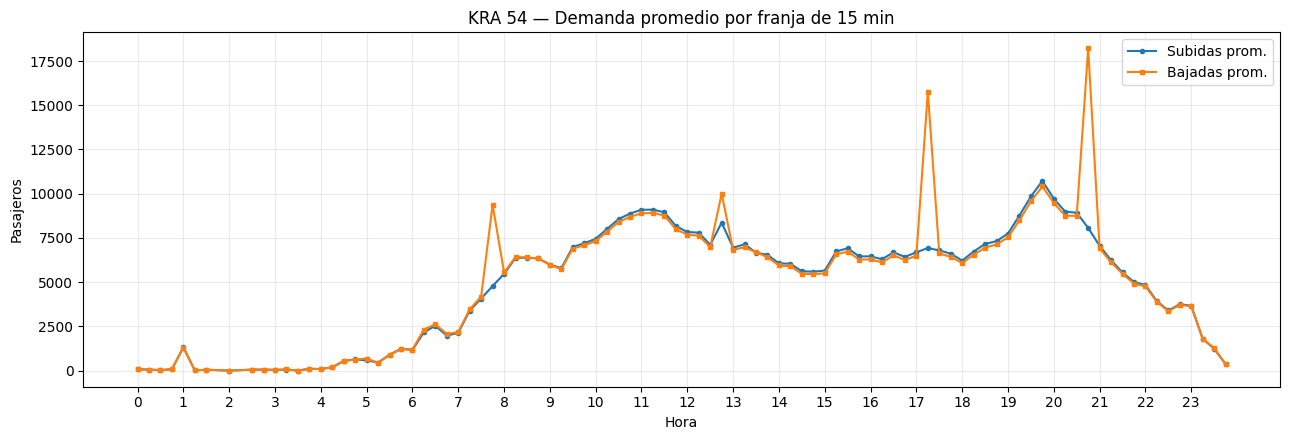

In [14]:
agg_hora = kra.groupby('hora_num', as_index=False).agg(
    subidas_prom=('subidas', 'mean'),
    bajadas_prom=('bajadas', 'mean'),
    viajes_prom=('nro_viajes', 'mean'),
).sort_values('hora_num')

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(agg_hora['hora_num'], agg_hora['subidas_prom'], marker='o', ms=3, label='Subidas prom.')
ax.plot(agg_hora['hora_num'], agg_hora['bajadas_prom'], marker='s', ms=3, label='Bajadas prom.')
ax.set_title('KRA 54 — Demanda promedio por franja de 15 min')
ax.set_xlabel('Hora')
ax.set_ylabel('Pasajeros')
ax.set_xticks(range(0, 24))
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

La demanda de KRA 54 sigue el patrón de un día laboral: casi nula de madrugada, con crecimiento desde las 5 h, un pico mediano hacia las 11 h (≈9.100), un valle entre las 14 h y las 16 h (≈5.500) y el máximo del día a las 19:45 (≈10.700 subidas). Después baja gradualmente hasta cerrar.

Subidas y bajadas se superponen, salvo en cuatro picos aislados de bajadas (≈7:45, 12:45, 17:15 y 20:45) que no aparecen en las subidas. No son demanda real: son registros anómalos que deben revisarse antes de modelar y que coinciden con las horas picos.

Los valores son promedios de acumulados históricos, así que la gráfica sirve para ver la forma del perfil, no para leer pasajeros por franja.

### Mapa de calor: hora × día de la semana

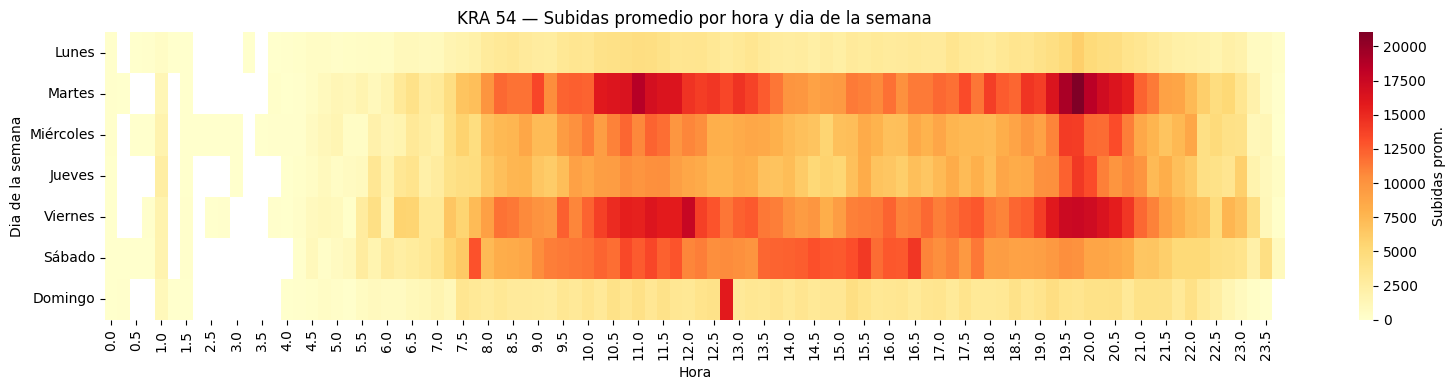

In [15]:
pivot = kra.pivot_table(index='id_dia_semana', columns='hora_num', values='subidas', aggfunc='mean')

orden_dias = (kra[['id_dia_semana', 'dia_semana']]
              .drop_duplicates()
              .sort_values('id_dia_semana'))
pivot.index = orden_dias['dia_semana'].values

plt.figure(figsize=(16, 4))
sns.heatmap(pivot, cmap='YlOrRd', cbar_kws={'label': 'Subidas prom.'})
plt.title('KRA 54 — Subidas promedio por hora y dia de la semana')
plt.xlabel('Hora')
plt.ylabel('Dia de la semana')
plt.tight_layout()
plt.show()

El mapa de calor confirma que la demanda sigue un patrón de día laboral, con dos franjas de mayor intensidad: media mañana (10 h a 12 h) y tarde-noche (19 h a 20:30), esta última la más fuerte. El sábado mantiene una demanda moderada y sostenida entre las 8 h y las 16 h, y el domingo es el día más bajo. Las celdas blancas son franjas sin registros, sobre todo de madrugada.

Los contrastes entre días laborales no deben leerse como demanda real. El lunes aparece pálido y martes y viernes muy intensos, pero los valores son promedios de acumulados que dependen de cuántos días componen cada celda (el lunes tiene muchos festivos). Para comparar días hay que usar la demanda por viaje.

La celda roja aislada del domingo cerca de las 12:45 es un dato anómalo (el mismo registro de 124.097 subidas detectado en 5.1) y no un pico real de demanda.

### Demanda frente a capacidad (subidas vs. viajes)

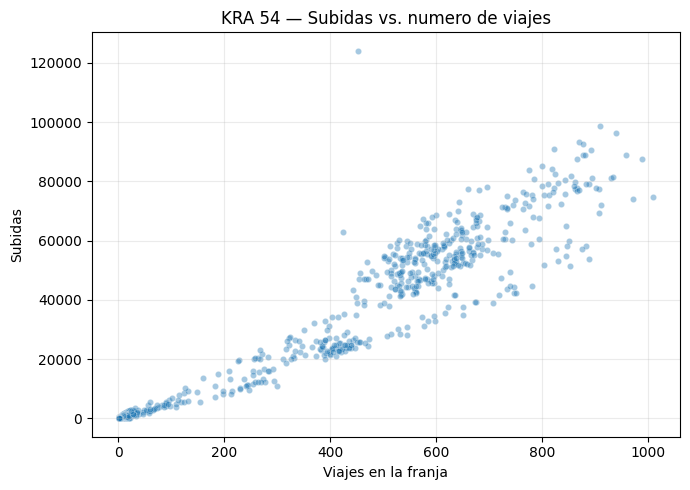

Correlacion viajes-subidas: 0.978


In [16]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=kra, x='nro_viajes', y='subidas', alpha=0.4, s=20, ax=ax)
ax.set_title('KRA 54 — Subidas vs. numero de viajes')
ax.set_xlabel('Viajes en la franja')
ax.set_ylabel('Subidas')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

correlacion = kra['nro_viajes'].corr(kra['subidas'])
print('Correlacion viajes-subidas:', round(correlacion, 3))

Podemos observar que posiblemente hay una correlación lineal positiva entre las subidad de pasajeros y los viajes en la franja.

### Outliers y calidad de los datos

In [17]:
q1, q3 = kra['subidas'].quantile([0.25, 0.75])
iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr

print(f'Q1={q1:.0f}  Q3={q3:.0f}  umbral superior={lim_sup:.0f}')
print('Outliers altos (> umbral):', int((kra['subidas'] > lim_sup).sum()))
print('Valores cero (subidas <= 0):', int((kra['subidas'] <= 0).sum()))
print('Nulos en subidas           :', int(kra['subidas'].isna().sum()))

kra.nlargest(5, 'subidas')[['dia_semana', 'hora_inicio', 'estacionalidad',
                          'subidas', 'bajadas', 'nro_viajes']]

Q1=180  Q3=926  umbral superior=2047
Outliers altos (> umbral): 543
Valores cero (subidas <= 0): 50
Nulos en subidas           : 0


,dia_semana,hora_inicio,estacionalidad,subidas,bajadas,nro_viajes
3779,Domingo,12:45:00,DIAS_CORRIENTES,124097,227359,453
1532,Martes,19:45:00,DIAS_CORRIENTES,98597,94577,908
2637,Jueves,19:45:00,DIAS_CORRIENTES,96208,93050,938
2039,Miércoles,19:30:00,DIAS_CORRIENTES,93433,90672,869
2040,Miércoles,19:45:00,DIAS_CORRIENTES,92499,89515,877


### Distribución de la demanda

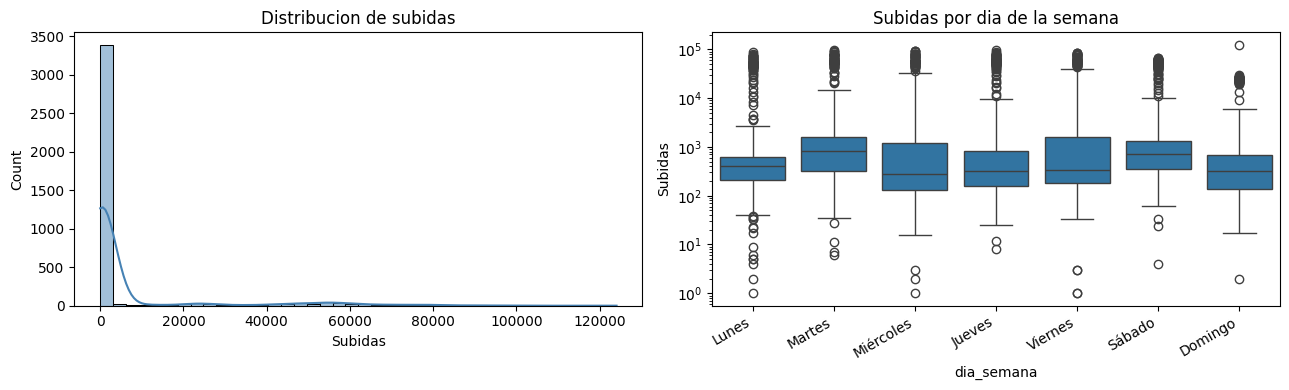

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(kra['subidas'], bins=40, kde=True, ax=axes[0], color='steelblue')
plt.yscale('log')
axes[0].set_title('Distribucion de subidas')
axes[0].set_xlabel('Subidas')

sns.boxplot(x='dia_semana', y='subidas', data=kra,
            order=orden_dias['dia_semana'].values, ax=axes[1])
axes[1].set_title('Subidas por dia de la semana')
axes[1].set_ylabel('Subidas')
plt.setp(axes[1].get_xticklabels(), rotation=30, ha='right')
plt.tight_layout()
plt.show()

La distribución de `subidas` es muy asimétrica: cerca de 3.400 de los 3.883 registros están por debajo de ≈3.000 pasajeros, y el resto forma una cola larga hasta 124.000, con dos pequeñas concentraciones hacia 25.000 y 55.000. Estas cola corresponde a los días corrientes, que acumulan muchos más viajes (ver 5.3), y no a errores.

En el boxplot (escala logarítmica) las medianas son del mismo orden todos los días, entre ≈300 y ≈800 subidas, con martes y sábado algo más altos. Todos los días tienen muchos valores atípicos hacia arriba, hasta ≈10⁵, y el domingo muestra un punto aislado en ≈124.000 (el registro anómalo de 5.1).

Por esa asimetría, la media no representa bien los datos: para modelar conviene usar la mediana, la demanda por viaje o una transformación logarítmica.

### Franjas pico y valle (insumo para alertas y descongestión)

In [19]:
agg_hora_sorted = agg_hora.sort_values('subidas_prom', ascending=False)

print('5 franjas de mayor demanda:')
print(agg_hora_sorted.head(5)[['hora_num', 'subidas_prom', 'viajes_prom']].to_string(index=False))

print('5 franjas de menor demanda:')
print(agg_hora_sorted.tail(5)[['hora_num', 'subidas_prom', 'viajes_prom']].to_string(index=False))

5 franjas de mayor demanda:
 hora_num  subidas_prom  viajes_prom
    19.75     10,723.02       111.87
    19.50      9,842.56       100.96
    20.00      9,719.85       104.54
    11.25      9,095.43       109.00
    11.00      9,093.14       106.57
5 franjas de menor demanda:
 hora_num  subidas_prom  viajes_prom
     3.00         40.50         1.00
     0.50         31.33         1.00
     1.25         11.00         1.00
     2.00          0.00         1.00
     3.50          0.00         1.00


Las franjas de mayor demanda se concentran en dos momentos: la tarde-noche (19:30 a 20:00, con el máximo a las 19:45: ≈10.700 subidas y ≈112 viajes) y media mañana (11:00 a 11:15, ≈9.100 subidas). Son las ventanas donde la oferta debe reforzarse.

Las de menor demanda son todas de madrugada (00:30 a 03:30), con entre 0 y 41 subidas y un solo viaje acumulado. Como tienen un único viaje, son pocos datos y no deben usarse para sacar conclusiones. El valle operativo real, el de horas con servicio regular, está en la tarde (14 h a 16 h, ver 5.4 y 5.10).

### Resumen por hora

In [20]:
agg_franja = kra.assign(franja=np.floor(kra['hora_num'])).groupby('franja', as_index=False).agg(
    subidas_prom=('subidas', 'mean'),
    bajadas_prom=('bajadas', 'mean'),
    viajes_prom=('nro_viajes', 'mean'),
    subidas_max=('subidas', 'max'),
).sort_values('franja')

agg_franja

,franja,subidas_prom,bajadas_prom,viajes_prom,subidas_max
0,0.00,66.53,59.71,1.41,148
1,1.00,919.73,901.07,16.02,9125
2,2.00,45.20,44.20,1.00,116
3,3.00,69.00,70.25,1.12,168
4,4.00,404.32,394.08,8.76,1332
5,5.00,792.77,802.82,18.35,4321
6,6.00,"1,955.24","2,044.33",44.79,13196
7,7.00,"3,637.99","4,988.68",47.21,62741
8,8.00,"6,141.01","6,177.61",76.00,58990
9,9.00,"6,478.93","6,408.61",72.36,60758


La demanda promedio por hora confirma los dos picos: 19 h (≈9.250 subidas) y 11 h (≈8.820), y el valle de las horas con servicio regular a las 14 h (≈5.820). Hasta las 5 h y desde las 23 h la demanda es muy baja, con menos de 2.400 subidas y pocos viajes por franja.

En 7 h, 17 h y 20 h las bajadas superan a las subidas entre 27 % y 37 % (por ejemplo, 11.297 frente a 8.925 a las 20 h). En el resto de horas son casi iguales. Estas diferencias coinciden con los picos aislados de bajadas vistos en 5.4, por lo que parecen errores de conteo y no demanda real.

El máximo de subidas a las 12 h (124.097) es el registro anómalo ya identificado, y el de la 1 h (9.125) también es sospechoso, porque la media de esa hora (≈920) se apoya en muy pocos registros.

### Diagnostico de los valores altos en `subidas`

In [21]:
# Los valores altos de 'subidas' son coherentes con el volumen de servicio,
# no con un error ni con una unidad distinta:
#
#   - todas las filas de timbradas_consolidado agregan la flota de la ruta;
#   - la unidad SIEMPRE es pasajeros;
#   - lo que cambia entre regimenes es cuantos viajes hubo en la franja.
#
# Comprobacion: el promedio por viaje debe ser estable en todo el dataset.
for col in ('subidas', 'bajadas'):
    d = (kra[col] / kra['nro_viajes']).replace([np.inf, -np.inf], np.nan).dropna()
    print(f'{col}/nro_viajes -> max {d.max():.3f} | min {d.min():.3f} | promedio {d.mean():.3f}')

print()
print('Comparacion por tipo de estacionalidad:')
print(agg_est.to_string(index=False))

subidas/nro_viajes -> max 273.945 | min 0.000 | promedio 70.509
bajadas/nro_viajes -> max 1342.870 | min 0.000 | promedio 70.879

Comparacion por tipo de estacionalidad:
    estacionalidad  registros  subidas_prom  bajadas_prom  viajes_prom
   DIAS_CORRIENTES        604     37,689.50     39,357.03       449.26
  FIESTA_ATLANTICO        776        867.77        851.29         9.58
TEMPORADA_NACIONAL        490        644.36        638.48         9.76
  FESTIVO_NACIONAL       1817        281.29        281.79         4.83
FIESTAS_PATRONALES        196        279.38        275.12         3.63


> **Hallazgo:** `DIAS_CORRIENTES` (id 25) promedia ~525 viajes por franja y
> ~43.790 subidas, frente a ~4-11 viajes en dias festivos. Las dos poblaciones
> estan en la misma unidad (pasajeros agregados por flota); la diferencia es
> cuantos viajes se programaron. No es un problema de datos.

### Regime comparable (excluye `DIAS_CORRIENTES`)

In [22]:
# Para comparar demanda entre dias con servicio parecido se excluye
# DIAS_CORRIENTES. Ojo: esto recorta el rango, no cambia la unidad.
COMPARABLE = kra[kra['estacionalidad'] != 'DIAS_CORRIENTES'].copy()

print('Filas totales :', len(kra))
print('Filas comparables:', len(COMPARABLE),
      f'({len(COMPARABLE)/len(kra)*100:.1f}% del total)')

COMPARABLE[['subidas', 'bajadas', 'nro_viajes']].describe().T

Filas totales : 3883
Filas comparables: 3279 (84.4% del total)


,count,mean,std,min,25%,50%,75%,max
subidas,"3,279.00",474.23,445.48,0.00,162.00,341.00,617.50,"3,591.00"
bajadas,"3,279.00",469.47,433.94,0.00,164.00,341.00,615.50,"3,481.00"
nro_viajes,"3,279.00",6.62,4.99,1.00,3.00,5.00,10.00,37.00


Al excluir `DIAS_CORRIENTES` quedan 3.279 de los 3.883 registros (84,4 %). Es un régimen mucho más homogéneo: las subidas tienen mediana 341 y máximo 3.591 (con todos los datos, el máximo era 124.097), y los registros acumulan entre 1 y 37 viajes (antes llegaban a 1.009).

Subidas y bajadas ahora coinciden (medias de 474 y 469, medianas iguales de 341). Esto confirma que los valores extremos de bajadas y el desbalance detectado antes provienen de `DIAS_CORRIENTES`, no de festivos ni temporadas.

Este subconjunto sirve para comparar franjas bajo un servicio parecido, pero no representa la operación típica: deja fuera ≈94 % de las subidas. No debe usarse como base para dimensionar la frecuencia de un día normal.

### Las dos poblaciones en escala log

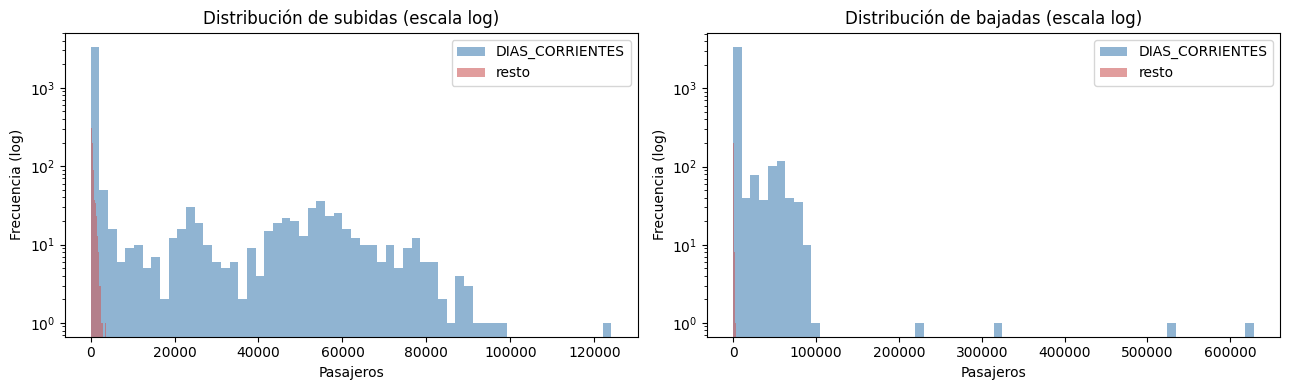

In [23]:
# Escala log para ver ambas poblaciones en el mismo eje: los dias
# corridos quedan dos ordenes de magnitud por encima, no fuera de rango.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col in zip(axes, ['subidas', 'bajadas']):
    ax.hist(kra[col], bins=60, color='steelblue', alpha=0.6,
            label='DIAS_CORRIENTES', log=True)
    ax.hist(COMPARABLE[col], bins=60, color='indianred', alpha=0.6,
            label='resto', log=True)
    ax.set_title(f'Distribución de {col} (escala log)')
    ax.set_xlabel('Pasajeros')
    ax.set_ylabel('Frecuencia (log)')
    ax.legend()

plt.tight_layout()
plt.show()

## 2.2 Mapa de los puntos importantes - KRA 54

Visualizacion de los 15 nodos que concentran el 100% de los pasajeros con
`idpunto` asignado, sobre el trazado real de la ruta (segmentos de ~500 m).

> Los puntos se asignan con `idpunto` y un tamano proporcional al volumen de pasajeros.
> El tamano del circulo y el color siguen la intensidad del trafico.

> **Nota:** los circulos con `idpunto = NULL` (1.147.271 pasajeros) son lecturas GPS
> en marcha, no en paradas, y quedan excluidos del grafo.

In [24]:
import json

# ============================================================================
# 7.0  Puntos de interes de KRA 54: volumen + contexto urbano
#
# Volumen: conteo_pasajeros_destino (marzo 2025).
# Contexto: OpenStreetMap -> direccion por Nominatim (geocodificacion inversa)
#           y lugar cercano por Overpass API en un radio de 400 m.
#
# Que representa cada punto, en orden de recorrido (inicio -> fin):
#----------------------------------------------------------------------------
#  1. idpunto 3     seg 9    Avenida Murillo, Nuevo Milenio, Soledad
#     -> AgrupaSalud IPS (clínica) a 130 m
#  2. idpunto 5     seg 21   Carrera 7, Simón Bolívar, Perímetro Urbano Barranquilla
#     -> Surtirepuestos La 19 (edificio) a 124 m
#  3. idpunto 13    seg 22   Boulevard Simón Bolívar, Simón Bolívar, Perímetro Urbano Barranquilla
#     -> Alcaldía Local Suroriente (edificio civic) a 68 m
#  4. idpunto 55    seg 28   Avenida Carrera 38, Localidad Suroriente, Perímetro Urbano Barranquilla
#     -> Colegio Salesiano San Roque (colegio) a 122 m
#  5. idpunto 56    seg 33   Vía 40, Montecristo, Perímetro Urbano Barranquilla
#     -> Antiguo Patio #2 del Transito (edificio) a 163 m
#  6. idpunto 59    seg 37   Carrera 54, El Prado, Perímetro Urbano Barranquilla
#     -> Parque Santander (parque) a 34 m
#  7. idpunto 57    seg 41   Carrera 53, Alto Prado, Perímetro Urbano Barranquilla
#     -> Parque Washington (parque) a 28 m
#  8. idpunto 35    seg 55   Carrera 30, Ciudad del Mar
#     -> Árbol de Caucho de Villa Campestre (atracción) a 144 m
#  9. idpunto 9     seg 58   Calle 14, Villa Mar, La Playa
#     -> IED Pies Descalzos y Centro Comunitario La Playa (colegio) a 206 m
# 10. idpunto 127   seg 61   Carrera 10, Adelita de Char I, La Playa
#     -> Parque Adelita de Char (parque) a 167 m
# 11. idpunto 11    seg 78   Carrera 51B, El Poblado, Perímetro Urbano Barranquilla
#     -> Iglesia Vida Abundante (iglesia/templo) a 104 m
# 12. idpunto 58    seg 83   Carrera 51B #76-35, Alto Prado, Perímetro Urbano Barranquilla
#     -> C. C. Habitad (centro comercial) a 199 m
# 13. idpunto 4     seg 108  Avenida Circunvalar, Las Trinitarias, Soledad
#     -> C.C. Metropolitano (centro comercial) a 84 m
# 14. idpunto 221   seg 115  Avenida Murillo, Los Loteros, Soledad
#     -> C.C. Plaza Macondo (centro comercial) a 219 m
# 15. idpunto 2     seg 123  Calle 65 #3-75, Los Loteros, Soledad
#     -> Centro Educativo Ramon Navarro Donado (colegio) a 245 m
#----------------------------------------------------------------------------
#
# La cobertura depende de lo que OSM tenga mapeado en Barranquilla.
# 'sin lugar destacado' = ningun elemento con nombre propio dentro del radio;
# no significa que el punto sea irrelevante.
#
# OJO: la variable se llama `nodos`, no `pts`.
# Usar `pts` aqui sobreescribiria cualquier dataframe con ese nombre.
# ============================================================================

ARCHIVO_RANKING = os.path.join(DATA, 'puntos_kra54_ranking.json')
ARCHIVO_CONTEXTO = os.path.join(DATA, 'puntos_kra54_contexto.json')
radio = 400
with open(ARCHIVO_RANKING, encoding='utf-8') as f:
    ranking = json.load(f)
with open(ARCHIVO_CONTEXTO, encoding='utf-8') as f:
    ctx = json.load(f)

# Unir volumen (ranking) con contexto urbano
por_id = {p['idpunto']: p for p in ctx['contexto']}
nodos = []
for p in ranking['ranking']:
    c = por_id.get(p['idpunto'], {})
    info = c.get('contexto', {})
    destacado = c.get('destacado')
    fila = dict(p)
    fila['direccion'] = info.get('direccion')
    fila['cercanos'] = c.get('cercanos', [])
    fila['destacado'] = destacado
    # Referencia legible: lugar cercano si existe; si no, la direccion
    fila['referencia'] = (
        '%s (%s) a %d m' % (destacado['nombre'], destacado['tipo'], destacado['distancia_m'])
        if destacado else (info.get('direccion') or 'sin referencia')
    )
    nodos.append(fila)

# Orden real de recorrido sobre la via
nodos.sort(key=lambda p: p['seg_aprox'])

print('Nodos:', len(nodos), '| Pasajeros:', f"{ranking['total_pasajeros_con_idpunto']:,}")
print('Con direccion:', sum(1 for p in nodos if p['direccion']),
      '| Con lugar destacado:', sum(1 for p in nodos if p['destacado']))
pd.DataFrame(nodos)[['idpunto', 'seg_aprox', 'total', 'direccion', 'referencia']].head()

Nodos: 15 | Pasajeros: 121,398
Con direccion: 15 | Con lugar destacado: 15


,idpunto,seg_aprox,total,direccion,referencia
0,3,9,6399,"Avenida Murillo, Nuevo Milenio, Soledad",AgrupaSalud IPS (clínica) a 130 m
1,5,21,14694,"Carrera 7, Simón Bolívar, Perímetro Urbano Bar...",Surtirepuestos La 19 (edificio) a 124 m
2,13,22,2942,"Boulevard Simón Bolívar, Simón Bolívar, Períme...",Alcaldía Local Suroriente (edificio civic) a 68 m
3,55,28,21926,"Avenida Carrera 38, Localidad Suroriente, Perí...",Colegio Salesiano San Roque (colegio) a 122 m
4,56,33,95,"Vía 40, Montecristo, Perímetro Urbano Barranqu...",Antiguo Patio #2 del Transito (edificio) a 163 m


### Mapa con tamano de punto proporcional al volumen

In [25]:
# ============================================================================
# 7.1  Mapa de los puntos de interes sobre el trazado real de KRA 54
# ============================================================================
# Trazado de la ruta 16 ordenado por nro_segmento para respetar el sentido
# de la via. La columna de geometria es geom_segmento, no geom.
with CONN.cursor() as cur:
    cur.execute(
        "SELECT nro_segmento, longitud_m, ST_AsGeoJSON(geom_segmento) "
        "FROM rutas_segmentos "
        "WHERE idruta = 16 AND geom_segmento IS NOT NULL "
        "ORDER BY nro_segmento"
    )
    segs = cur.fetchall()

# Un LayerGroup por rasgo: 'feat' es la forma corta en GeoJSON de folium
def linea(coords, **kw):
    return folium.FeatureGroup(name='feat').add_to(m).add_child(
        folium.PolyLine(coords, **kw))

trazado = []
for nro, largo, gj in segs:
    g = json.loads(gj)
    if g['type'] == 'LineString':
        # (lon, lat) -> (lat, lon)
        trazado.extend([(c[1], c[0]) for c in g['coordinates']])

# Decimar: el trazado trae cientos de miles de vertices; sin reducirlo el
# HTML pesa decenas de MB y el navegador se cuelga
trazado = trazado[::40] + [trazado[-1]]
print('Segmentos:', len(segs), '| vertices dibujados:', len(trazado))

# ---------------------------------------------------------------------------
# Teselas del fondo.
#
# OJO, dos trampas aqui, ambas costaron el mismo sintoma:
#
# 1. folium NO acepta url=... TileLayer espera el parametro 'tiles'. Si se pasa
#    url=, cae en **kwargs, 'tiles' conserva su valor por defecto
#    'OpenStreetMap' y el mapa termina pidiendo teselas de OSM aunque la
#    atribucion diga Esri. Se nota porque OSM devuelve el aviso de bloqueo.
# 2. No dejar el fondo en una variable de otra celda: Colab conserva variables
#    entre ejecuciones y un valor viejo de OpenStreetMap se reutiliza solo.
#
# Por eso la URL va escrita aqui y en el parametro correcto.
# ---------------------------------------------------------------------------
FONDOS = {
    'Esri callejero': {
        'tiles': ('https://server.arcgisonline.com/ArcGIS/rest/services/'
                'World_Street_Map/MapServer/tile/{z}/{y}/{x}'),
        'attr': 'Tiles &copy; Esri',
    },
    'Esri satelital': {
        'tiles': ('https://server.arcgisonline.com/ArcGIS/rest/services/'
                'World_Imagery/MapServer/tile/{z}/{y}/{x}'),
        'attr': 'Tiles &copy; Esri',
    },
}
FONDO = 'Esri callejero'
print('Fondo del mapa:', FONDO)
print('URL:', FONDOS[FONDO]['tiles'])

m = folium.Map(location=[nodos[0]['lat'], nodos[0]['lon']], zoom_start=12, tiles=None)
folium.TileLayer(**FONDOS[FONDO], name=FONDO).add_to(m)
linea(trazado, color='#0033cc', weight=5, opacity=0.8, tooltip='KRA 54 (ruta 16)')

# Radio y opacidad escalan con el volumen: el paso 1 (21.926 pasajeros) se lee
# de un vistazo y los puntos bajos quedan como contexto del recorrido
mx = max(p['total'] for p in nodos)
for p in nodos:
    radio_px = 6 + 26 * (p['total'] / mx) ** 0.6
    # Popup: volumen + que representa el punto
    html = (
        f"<b>Punto {p['rank']}</b><br>"
        f"idpunto {p['idpunto']} &middot; segmento ~{p['seg_aprox']}<br>"
        f"Subidas {p['subidas']:,} &middot; Bajadas {p['bajadas']:,}<br>"
        f"<b>Total {p['total']:,}</b> ({p['pct_total']}% del total)<br>"
        f"<hr>{p['referencia']}"
    )
    folium.CircleMarker(
        location=[p['lat'], p['lon']], radius=radio_px,
        color='#cc0000', weight=2, fill=True, fill_color='#ff6666',
        fill_opacity=min(0.35 + 0.5 * p['total'] / mx, 0.95),
        tooltip=f"pt {p['rank']} | seg {p['seg_aprox']} | {p['total']:,} pas",
        popup=folium.Popup(html, max_width=300)
    ).add_to(m)

folium.LayerControl().add_to(m)
m.fit_bounds([[c[0], c[1]] for c in trazado])

# fit_bounds() devuelve None, asi que hay que guardarlo aparte:
ARCHIVO_MAPA = os.path.join(DATA, 'mapa_kra54_puntos.html')
m.save(ARCHIVO_MAPA)
print('Mapa guardado en', ARCHIVO_MAPA,
      f'({os.path.getsize(ARCHIVO_MAPA)/1024:.0f} KB)')

# Comprobacion: si esto falla, el mapa pidio teselas a OSM y va a salir el
# aviso de bloqueo en lugar del fondo de la ciudad.
_html = open(ARCHIVO_MAPA, encoding='utf-8').read()
assert 'tile.openstreetmap.org' not in _html, 'El mapa esta pidiendo teselas a OSM'
print('OK: sin teselas de OpenStreetMap')

# Última expresión = el mapa. Sin esto Colab no muestra nada, porque
# fit_bounds() y save() devuelven None.
m

Segmentos: 123 | vertices dibujados: 7682
Fondo del mapa: Esri callejero
URL: https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}
Mapa guardado en /content/drive/MyDrive/proyecto_sobusa/data/mapa_kra54_puntos.html (488 KB)
OK: sin teselas de OpenStreetMap


### Orden de recorrido con el flujo de pasajeros en el mes de Marzo

Orden de recorrido por la ruta:
 seg_aprox  idpunto  total  subidas  bajadas  pct_total                                                         referencia
         9        3   6399     2217     4182       5.27                                  AgrupaSalud IPS (clínica) a 130 m
        21        5  14694     6371     8323      12.10                            Surtirepuestos La 19 (edificio) a 124 m
        22       13   2942      505     2437       2.42                  Alcaldía Local Suroriente (edificio civic) a 68 m
        28       55  21926    12245     9681      18.06                      Colegio Salesiano San Roque (colegio) a 122 m
        33       56     95       15       80       0.08                   Antiguo Patio #2 del Transito (edificio) a 163 m
        37       59  11593     6458     5135       9.55                                   Parque Santander (parque) a 34 m
        41       57   5263     1490     3773       4.34                                  Parque Washington 

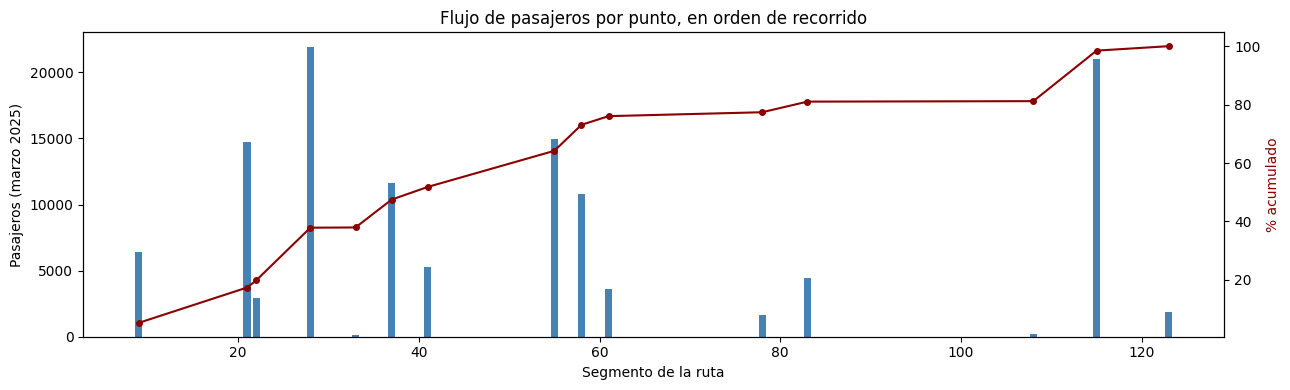

In [26]:
# Orden de recorrido: el volumen concentrado al inicio del recorrido es la
# senal clasica de que el corredor actsua como alimentador hacia el centro
orden = pd.DataFrame(nodos).sort_values('seg_aprox').reset_index(drop=True)
print('Orden de recorrido por la ruta:')
print(orden[['seg_aprox', 'idpunto', 'total', 'subidas', 'bajadas',
              'pct_total', 'referencia']].to_string(index=False))

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(orden['seg_aprox'], orden['total'], color='steelblue')
ax.set_xlabel('Segmento de la ruta')
ax.set_ylabel('Pasajeros (marzo 2025)')
ax.set_title('Flujo de pasajeros por punto, en orden de recorrido')
ax2 = ax.twinx()
acum = orden['total'].cumsum() / orden['total'].sum() * 100
ax2.plot(orden['seg_aprox'], acum, color='darkred', marker='o', ms=4)
ax2.set_ylabel('% acumulado', color='darkred')
ax2.grid(False)
plt.tight_layout()
plt.show()

### Grafico de Subidas vs Bajadas por punto

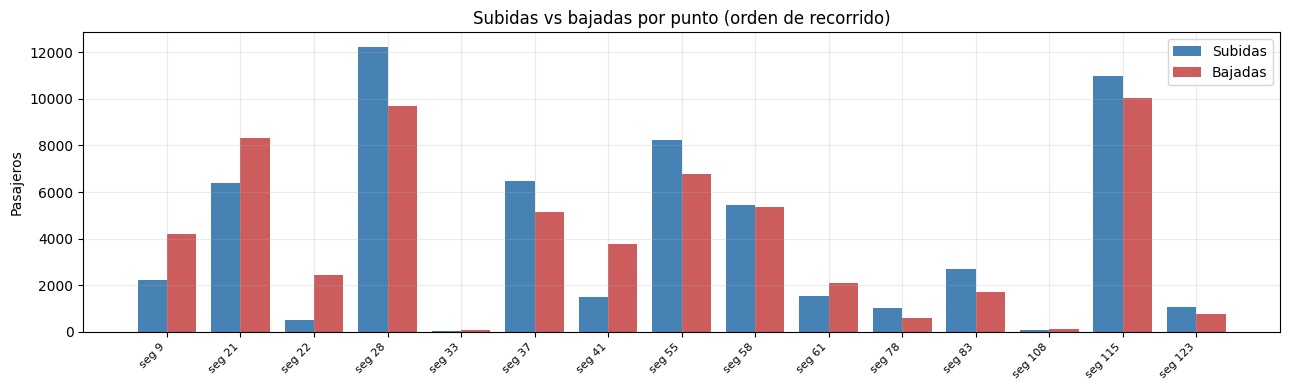

In [27]:
# Subidas vs bajadas: el balance indica si el punto es generador de viaje
# (sube mas de lo que baja) o punto de descenso (baja mas de lo que sube)
fig, ax = plt.subplots(figsize=(13, 4))
pos = range(len(orden))
ax.bar([i - 0.2 for i in pos], orden['subidas'], width=0.4,
        label='Subidas', color='steelblue')
ax.bar([i + 0.2 for i in pos], orden['bajadas'], width=0.4,
        label='Bajadas', color='indianred')
ax.set_xticks(list(pos))
ax.set_xticklabels(['seg ' + str(s) for s in orden['seg_aprox']],
                   fontsize=8, rotation=45, ha='right')
ax.set_ylabel('Pasajeros')
ax.set_title('Subidas vs bajadas por punto (orden de recorrido)')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Tabla resumen del grafo

In [28]:
largo_km = sum(s[1] for s in segs) / 1000
total_pas = sum(p['total'] for p in nodos)
con_destacado = [p for p in nodos if p['destacado']]
educacion = [p for p in con_destacado
             if p['destacado']['tipo'] in ('universidad', 'educación superior',
                                         'colegio', 'centro comunitario')]

print('Resumen de los puntos de interes de KRA 54')
print('  nodos                :', len(nodos))
print('  aristas (lineales)   :', len(nodos) - 1)
print('  longitud de la ruta  : %.1f km en %d segmentos' % (largo_km, len(segs)))
print('  pasajeros totales    :', f'{total_pas:,}')
print('  top 10 concentra     : %.1f%%' % (
      sum(p['total'] for p in sorted(nodos, key=lambda x: -x['total'])[:10]) /
      total_pas * 100))
print('  con direccion        :', sum(1 for p in nodos if p['direccion']), '/', len(nodos))
print('  con lugar destacado  :', len(con_destacado), '/', len(nodos))
print('  con educacion a <=%dm:' % radio, len(educacion))

print()
for i, p in enumerate(nodos, 1):
    print(f"{i:2d}. seg {p['seg_aprox']:>4} | {p['total']:>6,} pas | {p['referencia']}")

Resumen de los puntos de interes de KRA 54
  nodos                : 15
  aristas (lineales)   : 14
  longitud de la ruta  : 61.1 km en 123 segmentos
  pasajeros totales    : 121,398
  top 10 concentra     : 94.5%
  con direccion        : 15 / 15
  con lugar destacado  : 15 / 15
  con educacion a <=400m: 3

 1. seg    9 |  6,399 pas | AgrupaSalud IPS (clínica) a 130 m
 2. seg   21 | 14,694 pas | Surtirepuestos La 19 (edificio) a 124 m
 3. seg   22 |  2,942 pas | Alcaldía Local Suroriente (edificio civic) a 68 m
 4. seg   28 | 21,926 pas | Colegio Salesiano San Roque (colegio) a 122 m
 5. seg   33 |     95 pas | Antiguo Patio #2 del Transito (edificio) a 163 m
 6. seg   37 | 11,593 pas | Parque Santander (parque) a 34 m
 7. seg   41 |  5,263 pas | Parque Washington (parque) a 28 m
 8. seg   55 | 14,992 pas | Árbol de Caucho de Villa Campestre (atracción) a 144 m
 9. seg   58 | 10,807 pas | IED Pies Descalzos y Centro Comunitario La Playa (colegio) a 206 m
10. seg   61 |  3,607 pas | Parq

## 2.3 Grafo de KRA 54

In [29]:
import json

# ============================================================================
# 8.1  Grafo de KRA 54: nodos, aristas y distancias reales
#
# Los nodos son los 15 puntos de mayor volumen y forman una CADENA LINEAL:
# todos estan sobre el mismo corredor, asi que el grafo es una ruta, no una
# malla. 15 nodos -> 14 aristas.
#
# Que representa cada nodo, en el orden real de recorrido:
#------------------------------------------------------------------------------
#  1. pos  3585 m | idpunto 221   | C.C. Plaza Macondo (centro comercial) a 219 m
#       Avenida Murillo, Los Loteros, Soledad   (el 'mas cercano' da 115: la ruta pasa 2 veces por esa calle)
#  2. pos 13886 m | idpunto 55    | Colegio Salesiano San Roque (colegio) a 122 m
#       Avenida Carrera 38, Localidad Suroriente, Perímetro Urbano Barranquilla
#  3. pos 16454 m | idpunto 56    | Antiguo Patio #2 del Transito (edificio) a 163 m
#       Vía 40, Montecristo, Perímetro Urbano Barranquilla
#  4. pos 18377 m | idpunto 59    | Parque Santander (parque) a 34 m
#       Carrera 54, El Prado, Perímetro Urbano Barranquilla
#  5. pos 20431 m | idpunto 57    | Parque Washington (parque) a 28 m
#       Carrera 53, Alto Prado, Perímetro Urbano Barranquilla
#  6. pos 27370 m | idpunto 35    | Árbol de Caucho de Villa Campestre (atracción) a 144 m
#       Carrera 30, Ciudad del Mar
#  7. pos 30419 m | idpunto 127   | Parque Adelita de Char (parque) a 167 m
#       Carrera 10, Adelita de Char I, La Playa
#  8. pos 32417 m | idpunto 9     | IED Pies Descalzos y Centro Comunitario La Playa (colegio) a 206 m
#       Calle 14, Villa Mar, La Playa   (el 'mas cercano' da 58: la ruta pasa 2 veces por esa calle)
#  9. pos 38882 m | idpunto 11    | Iglesia Vida Abundante (iglesia/templo) a 104 m
#       Carrera 51B, El Poblado, Perímetro Urbano Barranquilla
# 10. pos 41188 m | idpunto 58    | C. C. Habitad (centro comercial) a 199 m
#       Carrera 51B #76-35, Alto Prado, Perímetro Urbano Barranquilla
# 11. pos 49878 m | idpunto 13    | Alcaldía Local Suroriente (edificio civic) a 68 m
#       Boulevard Simón Bolívar, Simón Bolívar, Perímetro Urbano Barranquilla   (el 'mas cercano' da 22: la ruta pasa 2 veces por esa calle)
# 12. pos 50235 m | idpunto 5     | Surtirepuestos La 19 (edificio) a 124 m
#       Carrera 7, Simón Bolívar, Perímetro Urbano Barranquilla   (el 'mas cercano' da 21: la ruta pasa 2 veces por esa calle)
# 13. pos 54041 m | idpunto 4     | C.C. Metropolitano (centro comercial) a 84 m
#       Avenida Circunvalar, Las Trinitarias, Soledad
# 14. pos 56672 m | idpunto 3     | AgrupaSalud IPS (clínica) a 130 m
#       Avenida Murillo, Nuevo Milenio, Soledad   (el 'mas cercano' da 9: la ruta pasa 2 veces por esa calle)
# 15. pos 61409 m | idpunto 2     | Centro Educativo Ramon Navarro Donado (colegio) a 245 m
#       Calle 65 #3-75, Los Loteros, Soledad
#------------------------------------------------------------------------------
#
# Decisiones importantes:
#
# - Las distancias se miden SOBRE LA VIA, no en linea recta. Se usa
#   ST_LineSubsubstring sobre la ruta completa proyectada a EPSG:32619
#   (UTM 19N). Sin proyectar, ST_Length devuelve ~0.6 'metros' que en
#   realidad son 0.6 grados, porque la geometria esta en SRID 4326.
#
# - El orden de recorrido sale de la POSICION sobre la cadena de
#   segmentos (nro_segmento), no del 'segmento mas cercano'. Donde la ruta
#   recorre dos veces la misma calle el emparejamiento por cercanía es
#   ambiguo y dio 6 de 15 nodos equivocados.
#
# - El grafo es NO DIRIGIDO: conteo_pasajeros_destino agrega subidas y
#   bajadas de ambos sentidos, no son flujos separados.
#
# - NO hay tiempos de viaje en la base. tiempo_min usa una velocidad de
#   referencia de 20 km/h: es una estimacion, no un dato medido.
# ============================================================================
ARCHIVO_GRAFO = os.path.join(DATA, 'grafo_kra54.json')

with open(ARCHIVO_GRAFO, encoding='utf-8') as f:
    grafo = json.load(f)

df_grafo = pd.DataFrame(grafo['nodos'])
print('Nodos   :', grafo['n_nodos'])
print('Aristas :', grafo['n_aristas'])
print('Longitud: %.2f km' % grafo['longitud_ruta_km'])
print('Pasajeros: %s' % f"{grafo['total_pasajeros']:,}")
print()
print(df_grafo[['orden_recorrido', 'idpunto', 'posicion_en_ruta_m',
                 'seg_cadena', 'total', 'subidas', 'bajadas',
                 'referencia']].to_string(index=False))

Nodos   : 15
Aristas : 14
Longitud: 61.41 km
Pasajeros: 121,398

 orden_recorrido  idpunto  posicion_en_ruta_m  seg_cadena  total  subidas  bajadas                                                         referencia
               1      221            3,585.00           8  20998    10979    10019                      C.C. Plaza Macondo (centro comercial) a 219 m
               2       55           13,885.70          28  21926    12245     9681                      Colegio Salesiano San Roque (colegio) a 122 m
               3       56           16,453.50          33     95       15       80                   Antiguo Patio #2 del Transito (edificio) a 163 m
               4       59           18,376.60          37  11593     6458     5135                                   Parque Santander (parque) a 34 m
               5       57           20,430.70          41   5263     1490     3773                                  Parque Washington (parque) a 28 m
               6       35          

### Aristas y distancias

In [30]:
# --- 8.2  Aristas: distancias entre nodos consecutivos -----------------
df_aristas = pd.DataFrame(grafo['aristas'])

print('Longitud de cada arista:')
print(df_aristas.to_string(index=False))
print()
print('Total aristas : %.2f km' % (df_aristas['distancia_m'].sum() / 1000))
print('Arista mas larga : %.2f km (%s -> %s)' % (
    df_aristas['distancia_m'].max() / 1000,
    df_aristas.loc[df_aristas['distancia_m'].idxmax(), 'origen'],
    df_aristas.loc[df_aristas['distancia_m'].idxmax(), 'destino']))
print('Arista mas corta: %.0f m (%s -> %s)' % (
    df_aristas['distancia_m'].min(),
    df_aristas.loc[df_aristas['distancia_m'].idxmin(), 'origen'],
    df_aristas.loc[df_aristas['distancia_m'].idxmin(), 'destino']))
print('Mediana        : %.0f m' % df_aristas['distancia_m'].median())
print()
print('Nota: %d de las %d aristas superan 5 km. Entre nodos consecutivos'
      % ((df_aristas['distancia_m'] > 5000).sum(), len(df_aristas)))
print('hay tramos sin ningun punto de conteo conboarding alto. Si el modelo')
print('los necesita como variables de entrada, habra que discretizar la via.')

Longitud de cada arista:
origen destino  distancia_m  distancia_km  tiempo_min
  p221     p55    10,300.70         10.30       30.90
   p55     p56     2,567.80          2.57        7.70
   p56     p59     1,923.10          1.92        5.80
   p59     p57     2,054.10          2.05        6.20
   p57     p35     6,938.90          6.94       20.80
   p35    p127     3,049.30          3.05        9.10
  p127      p9     1,998.20          2.00        6.00
    p9     p11     6,465.20          6.46       19.40
   p11     p58     2,305.70          2.31        6.90
   p58     p13     8,690.30          8.69       26.10
   p13      p5       357.00          0.36        1.10
    p5      p4     3,805.80          3.81       11.40
    p4      p3     2,630.90          2.63        7.90
    p3      p2     4,736.90          4.74       14.20

Total aristas : 57.82 km
Arista mas larga : 10.30 km (p221 -> p55)
Arista mas corta: 357 m (p13 -> p5)
Mediana        : 2840 m

Nota: 4 de las 14 aristas superan 5 

### Estructura del grafo

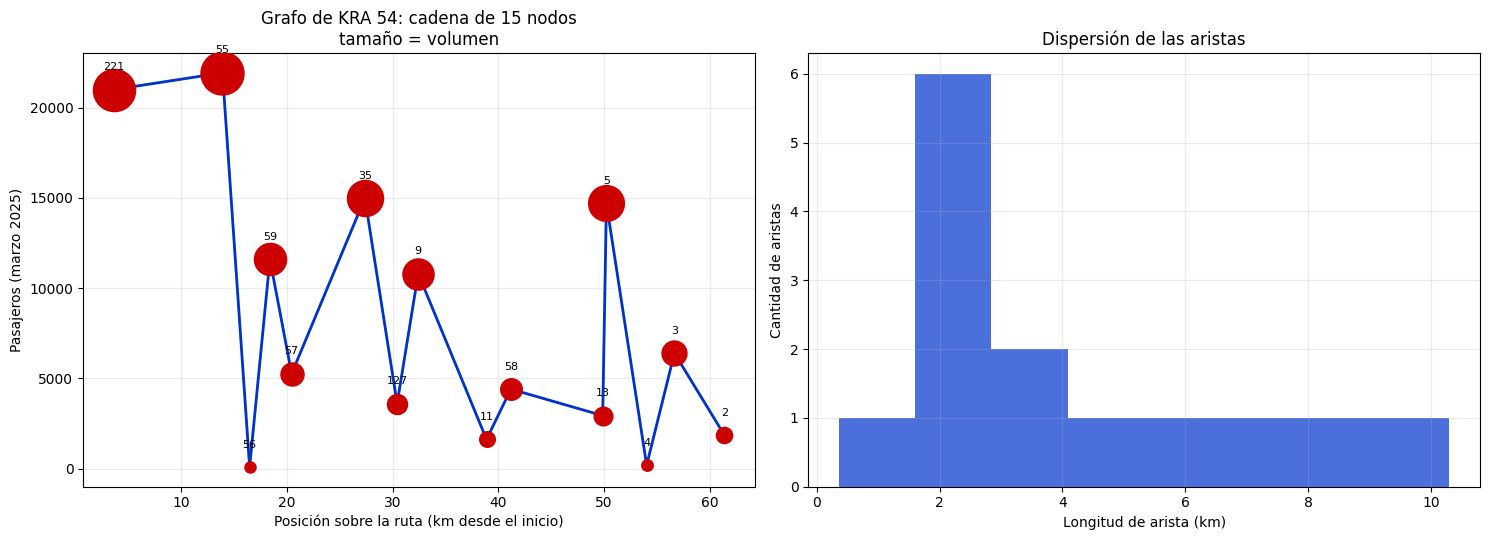

In [31]:
# --- 8.3  Estructura del grafo -----------------------------------------
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# (a) cadena: nodos sobre la via, tamano = pasajeros
ax = axes[0]
ax.plot([n['posicion_en_ruta_m'] / 1000 for n in grafo['nodos']],
        [n['total'] for n in grafo['nodos']],
        color='lightgray', zorder=1)
for a, b in zip(grafo['nodos'], grafo['nodos'][1:]):
    ax.plot([a['posicion_en_ruta_m'] / 1000, b['posicion_en_ruta_m'] / 1000],
            [a['total'], b['total']],
            color='#0033cc', lw=2, zorder=2)
mx = max(n['total'] for n in grafo['nodos'])
for n in grafo['nodos']:
    ax.scatter(n['posicion_en_ruta_m'] / 1000, n['total'],
               s=60 + 900 * n['total'] / mx, color='#cc0000', zorder=3)
    ax.annotate(str(n['idpunto']),
                (n['posicion_en_ruta_m'] / 1000, n['total']),
                textcoords='offset points', xytext=(0, 14),
                ha='center', fontsize=8)
ax.set_xlabel('Posición sobre la ruta (km desde el inicio)')
ax.set_ylabel('Pasajeros (marzo 2025)')
ax.set_title('Grafo de KRA 54: cadena de 15 nodos\ntamaño = volumen')
ax.grid(alpha=0.25)

# (b) histograma de longitudes de arista
ax = axes[1]
ax.hist(df_aristas['distancia_m'] / 1000, bins=8, color='#0033cc', alpha=0.7)
ax.set_xlabel('Longitud de arista (km)')
ax.set_ylabel('Cantidad de aristas')
ax.set_title('Dispersión de las aristas')
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### El grafo sobre el mapa

In [32]:
# --- 8.4  El grafo sobre el mapa ---------------------------------------
# Liberar transacciones abortadas previas si las hay
try:
    CONN.rollback()
except Exception:
    pass

# Las aristas van por la via real (geom_segmento), no en linea recta.
with CONN.cursor() as cur:
    cur.execute(
        "SELECT nro_segmento, ST_AsGeoJSON(geom_segmento) "
        "FROM rutas_segmentos "
        "WHERE idruta = %s AND geom_segmento IS NOT NULL "
        "ORDER BY nro_segmento",
        (16,)
    )
    segs_grafo = cur.fetchall()

lineas_arista = {}
for nro, gj in segs_grafo:
    g = json.loads(gj)
    if g['type'] == 'LineString':
        lineas_arista[nro] = [(c[1], c[0]) for c in g['coordinates']]

m_grafo = folium.Map(location=[grafo['nodos'][0]['lat'], grafo['nodos'][0]['lon']],
                     zoom_start=12, tiles=None)
folium.TileLayer(**FONDOS[FONDO], name=FONDO).add_to(m_grafo)

# Fondo del corredor en gris claro
_gris = folium.PolyLine(lineas_arista[grafo['nodos'][0]['seg_cadena']],
                        color='lightgray', weight=4)
_gris.add_to(m_grafo)

# Dibujar solo los tramos de via que unen nodos consecutivos: eso es el grafo
for e in grafo['aristas']:
    no = next(n for n in grafo['nodos'] if n['id'] == e['origen'])
    nd = next(n for n in grafo['nodos'] if n['id'] == e['destino'])
    tramo = []
    for nro in range(no['seg_cadena'], nd['seg_cadena'] + 1):
        tramo.extend(lineas_arista.get(nro, []))
    if tramo:
        folium.PolyLine(tramo, color='#0033cc', weight=6, opacity=0.9,
                        tooltip='%s - %s (%.2f km)'
                        % (e['origen'], e['destino'], e['distancia_km'])).add_to(m_grafo)

for n in grafo['nodos']:
    radio = 6 + 22 * (n['total'] / mx) ** 0.6
    html = (
        f"<b>Nodo {n['orden_recorrido']}</b><br>"
        f"idpunto {n['idpunto']} · segmento {n['seg_cadena']}<br>"
        f"posición {n['posicion_en_ruta_m']/1000:.2f} km<br>"
        f"Subidas {n['subidas']:,} · Bajadas {n['bajadas']:,}<br>"
        f"<b>Total {n['total']:,}</b> ({n['pct_total']}% del total)<hr>{n['referencia']}"
    )
    folium.CircleMarker(
        location=[n['lat_sobre_via'], n['lon_sobre_via']],
        radius=radio, color='#cc0000', weight=2, fill=True,
        fill_color='#ff6666', fill_opacity=0.8,
        tooltip='nodo %d | %s | %s pas'
        % (n['orden_recorrido'], n['idpunto'], f"{n['total']:,}"),
        popup=folium.Popup(html, max_width=300)).add_to(m_grafo)

folium.LayerControl().add_to(m_grafo)
m_grafo.fit_bounds([[c[0], c[1]] for c in trazado])
m_grafo

Output hidden; open in https://colab.research.google.com to view.

In [33]:
ARCHIVO_MAPA_GRAFO = os.path.join(DATA, 'mapa_grafo_kra54.html')
m_grafo.save(ARCHIVO_MAPA_GRAFO)
print('Mapa del grafo guardado en', ARCHIVO_MAPA_GRAFO,
      f'({os.path.getsize(ARCHIVO_MAPA_GRAFO)/1024:.0f} KB)')

# Comprobacion: si falla, el mapa pide teselas a OSM y sale el aviso de bloqueo.
_h = open(ARCHIVO_MAPA_GRAFO, encoding='utf-8').read()
assert 'tile.openstreetmap.org' not in _h, 'El mapa pide teselas a OSM'
print('OK: sin teselas de OpenStreetMap')

m_grafo

Output hidden; open in https://colab.research.google.com to view.

## 2.4 Fase 1: modelo inicial de demanda

Predice **cuántas personas suben por viaje** en cada nodo y hora de KRA 54.

El objetivo es *pasajeros por viaje* y no pasajeros por hora, y esa decisión es
lo que hace que el modelo sirva para la Fase 2. Si se predijera pasajeros por
hora, el modelo aprendería el calendario de buses en vez de la demanda, y no
se podría usar para decidir frecuencia. Se implementa como Poisson con
`offset = log(viajes)`.

> **Nota (v2):** la tasa por viaje describe bien la *carga por bus*, pero tiene dos límites para decidir frecuencia. Primero, el modelo ve 15 paradas (≈11,7 % de los pasajeros), no la ruta. Segundo, multiplicar la tasa por los viajes *propuestos* supondría que los pasajeros crecen al poner más buses, y no es así: la demanda de una hora es casi independiente de la frecuencia. Por eso la demanda que consume el optimizador se modela aparte, por hora y para toda la ruta, en la sección 3.3. Este modelo queda como herramienta de reparto entre paradas.

In [34]:
#Datos: panel horario y servicio
# Los CSV los genera scripts/extraer_panel.py y scripts/extraer_servicio.py.
# No se consulta la base desde aqui: 41 GB no caben en memoria de Colab y
# cada consulta mensual cuesta ~12 s en la RDS.
import glob

PANEL = os.path.join(DATA, 'panel_horario')

df = pd.concat([pd.read_csv(f, parse_dates=['dia'])
                for f in sorted(glob.glob(os.path.join(PANEL, 'panel_*.csv')))])
serv = pd.concat([pd.read_csv(f, parse_dates=['dia'])
                   for f in sorted(glob.glob(os.path.join(PANEL, 'servicio_*.csv')))])

print('panel  : %d celdas, %s dias, %d puntos, %s .. %s'
      % (len(df), df['dia'].nunique(), df['idpunto'].nunique(),
         df['dia'].min().date(), df['dia'].max().date()))
print('servicio: %d celdas, %d viajes' % (len(serv), serv['viajes'].sum()))
print()
print('Subidas por celda: media %.2f  mediana %.1f  max %d'
      % (df['subidas'].mean(), df['subidas'].median(), df['subidas'].max()))

# Cobertura: dias con datos por mes y año. Un hueco (mes con pocos dias) se ve aqui
# antes de que contamine los rezagos.
_cob = (df.assign(anio=df['dia'].dt.year, mes_=df['dia'].dt.month)
          .groupby(['mes_', 'anio'])['dia'].nunique().unstack('anio'))
print()
print('Dias con datos por mes y año:')
print(_cob.to_string())
print()
print('Nodos distintos por año (deben ser los mismos 15):')
print(df.groupby(df['dia'].dt.year)['idpunto'].nunique().to_string())
df.head()

panel  : 244185 celdas, 966 dias, 15 puntos, 2023-01-01 .. 2025-08-30
servicio: 16451 celdas, 254082 viajes

Subidas por celda: media 9.35  mediana 4.0  max 97160

Dias con datos por mes y año:
anio  2023  2024  2025
mes_                  
1    31.00 31.00 30.00
2    28.00 29.00 27.00
3    31.00 31.00 30.00
4    30.00 30.00 29.00
5    31.00 31.00 30.00
6    30.00 30.00 29.00
7    31.00 31.00 30.00
8    31.00 31.00 30.00
9    30.00 30.00   NaN
10   31.00 31.00   NaN
11   30.00 30.00   NaN
12   31.00 31.00   NaN

Nodos distintos por año (deben ser los mismos 15):
dia
2023    15
2024    15
2025    15


,dia,hora,idpunto,subidas,bajadas,eventos
0,2023-01-01,4,2,0,0,7
1,2023-01-01,5,2,0,0,26
2,2023-01-01,5,3,1,0,3
3,2023-01-01,5,4,2,2,4
4,2023-01-01,5,5,0,1,2


### 2.4.1 Limpieza de glitches de contador

In [35]:
# --- 9.2  Limpieza: hay contadores que se desbordaron ------------------
# En 2025-07-04 hay una fila con 28 822 subidas y en 2025-04-09 una con
# 555 752 bajadas. El p99.9 de una celda normal es 101, asi que no son
# outliers legitimos sino fallos del contador. Se eliminan por cutoff robusto
# por (idpunto, hora). Se reporta cuantas se quitan en vez de esconderlo.
LIMITE_P99 = 0.999
ANTES = df['subidas'].sum()

limite = df.groupby(['idpunto', 'hora'])['subidas'].transform(
    lambda s: max(s.quantile(LIMITE_P99) * 3, 20))
malo = (df['subidas'] > limite) | (df['bajadas'] > limite)
n_malo = int(malo.sum())
df = df[~malo].copy()

print('celdas eliminadas : %d de %d (%.2f%%)'
      % (n_malo, len(df) + n_malo, 100 * n_malo / (len(df) + n_malo)))
print('subidas %s -> %s' % (f'{ANTES:,}', f"{int(df['subidas'].sum()):,}"))
print('max por celda tras limpiar: %d' % df['subidas'].max())
print()
print('Sin esta limpieza el modelo aprende que el nodo 221 tiene una punta')
print('de 28 000 pasajeros a las 7am del 4 de julio.')
df['mes'] = df['dia'].dt.month

celdas eliminadas : 2048 de 244185 (0.84%)
subidas 2,282,851 -> 2,151,719
max por celda tras limpiar: 331

Sin esta limpieza el modelo aprende que el nodo 221 tiene una punta
de 28 000 pasajeros a las 7am del 4 de julio.


### 2.4.2 La exposición: pasajeros por viaje

In [36]:
# --- 9.3  Exposicion: pasajeros por viaje ------------------------------
# El merge con el servicio es lo que hace posible distinguir dos cosas que
# se ven iguales en la tabla de conteos:
#   - 'llego un bus y nadie subio'  -> 0 real, debe entrar al panel
#   - 'no paso ningun bus'         -> no observado, NO debe entrar
df = df.merge(serv[['dia', 'hora', 'viajes']], on=['dia', 'hora'], how='inner')
df = df[df['viajes'] > 0].copy()

df['dow'] = df['dia'].dt.dayofweek
df['tipo_dia'] = np.where(df['dow'] >= 5, 'fin_de_semana', 'laborable')
df['sub_por_viaje'] = df['subidas'] / df['viajes']

grafo = json.load(open(os.path.join(DATA, 'grafo_kra54.json'), encoding='utf-8'))
info_nodo = {n['idpunto']: n for n in grafo['nodos']}
orden_nodos = [n['idpunto'] for n in grafo['nodos']]
df['pos_rel'] = df['idpunto'].map(
    {n['idpunto']: n['posicion_en_ruta_m'] / grafo['longitud_ruta_m'] for n in grafo['nodos']})

print('panel modelable: %d filas' % len(df))
print('  sub_por_viaje  media %.2f  mediana %.2f  max %.1f'
      % (df['sub_por_viaje'].mean(), df['sub_por_viaje'].median(), df['sub_por_viaje'].max()))
print()
print('viajes por hora y dia: media %.1f  min %d  max %d'
      % (serv['viajes'].mean(), serv['viajes'].min(), serv['viajes'].max()))
print()
print('ATENCION: el objetivo es por VIAJE. Para convertirlo a pasajeros por hora se multiplica')
print('por los viajes HISTORICOS de esa hora, nunca por los que se propongan: la demanda de una')
print('hora no crece porque se pongan mas buses. La demanda de ruta que consume el optimizador')
print('sale del modelo de la seccion 3.3, no de este.')

panel modelable: 216924 filas
  sub_por_viaje  media 0.66  mediana 0.36  max 64.0

viajes por hora y dia: media 15.4  min 1  max 42

ATENCION: el objetivo es por VIAJE. Para convertirlo a pasajeros por hora se multiplica
por los viajes HISTORICOS de esa hora, nunca por los que se propongan: la demanda de una
hora no crece porque se pongan mas buses. La demanda de ruta que consume el optimizador
sale del modelo de la seccion 3.3, no de este.


### 2.4.3 Validación temporal

In [37]:
# --- 9.4  Division temporal (no aleatoria) ---------------------------
# Una particion aleatoria mezcla el futuro con el pasado y devuelve metricas
# infladas; el objetivo es predecir el futuro.
#
# CAMBIO: antes se separaba por MES (MESES_TEST = [7, 8]). Con 2023-2025 en el
# panel eso mandaba a test los jul-ago de 2023, 2024 y 2025 a la vez y dejaba a
# train sin esos meses. Ahora se separa por FECHA: todo lo anterior a
# FECHA_TEST_INI es train y todo lo posterior es test.
FECHA_TEST_INI = pd.Timestamp('2025-07-01')
df['es_test'] = df['dia'] >= FECHA_TEST_INI
tr = df[~df['es_test']].copy()
te = df[df['es_test']].copy()

# La media historica se calcula SOLO con train. Si usara todo el panel,
# el modelo veria su propio futuro.
media_tr = (tr.groupby(['idpunto', 'hora', 'tipo_dia'])['sub_por_viaje']
             .mean().rename('media_hist'))
tr = tr.merge(media_tr, on=['idpunto', 'hora', 'tipo_dia'], how='left')
te = te.merge(media_tr, on=['idpunto', 'hora', 'tipo_dia'], how='left')

# Combinaciones que no estaban en train caen a la media global de train,
# no a cero: cero significa 'sin demanda', no 'sin informacion'.
te['media_hist'] = te['media_hist'].fillna(tr['sub_por_viaje'].mean())

print('train (%s .. %s): %d filas' % (tr['dia'].min().date(), tr['dia'].max().date(), len(tr)))
print('test  (%s .. %s): %d filas' % (te['dia'].min().date(), te['dia'].max().date(), len(te)))
print()
print('train mean %.3f | test mean %.3f' % (tr['sub_por_viaje'].mean(), te['sub_por_viaje'].mean()))


train (2023-01-01 .. 2025-06-29): 204049 filas
test  (2025-07-01 .. 2025-08-30): 12875 filas

train mean 0.666 | test mean 0.564


### 2.4.3.1 Distribución del conteo

Antes de elegir la familia del modelo se revisa cómo se distribuye `subidas` por celda (nodo, día, hora) en train: asimetría, ceros y sobredispersión respecto a Poisson.

Observaciones          : 204049
Media / mediana        : 9.86 / 5.0
Varianza               : 170.64
Varianza / media       : 17.30   (Poisson = 1)
Asimetría              : 2.71
Percentiles 90/99/99.9 : [26.0, 61.0, 99.0]
Ceros                  : 30719 (15.1%)


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)



Dispersión de Pearson (Poisson con offset): 9.85
Ceros observados vs esperados bajo Poisson: 30719 vs 18841
Grupos usados: 5786 | mediana de varianza/media: 1.95


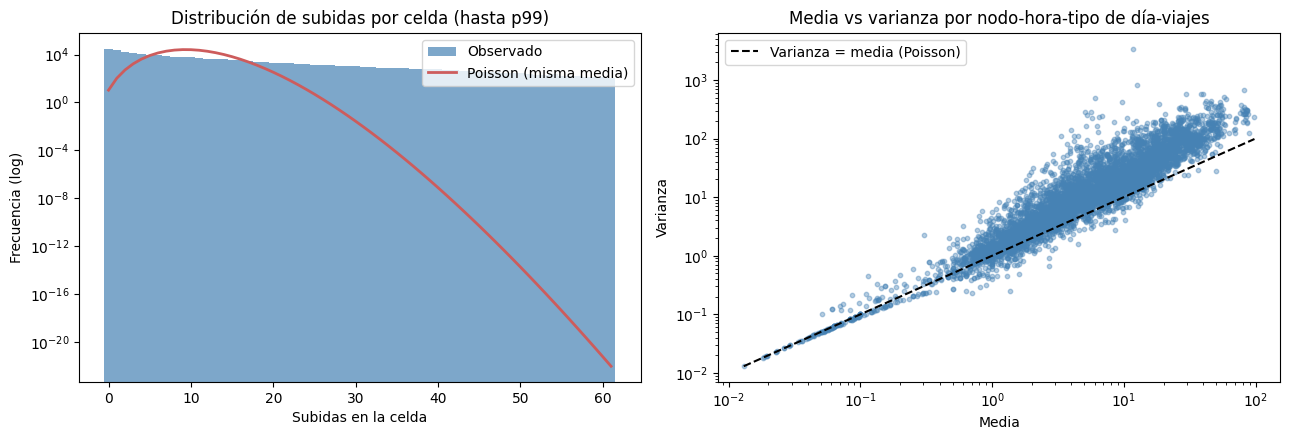

In [38]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

y = tr['subidas']
p99 = int(y.quantile(0.99))

print('Observaciones          : %d' % len(y))
print('Media / mediana        : %.2f / %.1f' % (y.mean(), y.median()))
print('Varianza               : %.2f' % y.var())
print('Varianza / media       : %.2f   (Poisson = 1)' % (y.var() / y.mean()))
print('Asimetría              : %.2f' % y.skew())
print('Percentiles 90/99/99.9 : %s' % y.quantile([.9, .99, .999]).round(1).tolist())
print('Ceros                  : %d (%.1f%%)' % ((y == 0).sum(), 100 * (y == 0).mean()))

# Sobredispersión condicional: Poisson con exposición, Pearson chi2 / gl (Poisson = 1)
glm_disp = smf.glm('subidas ~ C(hora) * C(tipo_dia) + C(idpunto)', data=tr,
                   family=sm.families.Poisson(),
                   offset=np.log(tr['viajes'])).fit()
disp = glm_disp.pearson_chi2 / glm_disp.df_resid
ceros_esp = np.exp(-glm_disp.fittedvalues).sum()
print()
print('Dispersión de Pearson (Poisson con offset): %.2f' % disp)
print('Ceros observados vs esperados bajo Poisson: %d vs %.0f' % ((y == 0).sum(), ceros_esp))

# Media vs varianza por grupo con la misma exposición
g = (tr.groupby(['idpunto', 'hora', 'tipo_dia', 'viajes'])['subidas']
       .agg(media='mean', varianza='var', n='size').reset_index())
g = g[(g['n'] >= 10) & (g['media'] > 0) & (g['varianza'] > 0)]
print('Grupos usados: %d | mediana de varianza/media: %.2f'
      % (len(g), (g['varianza'] / g['media']).median()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
k = np.arange(0, p99 + 1)
ax.hist(y[y <= p99], bins=np.arange(0, p99 + 2) - 0.5,
        color='steelblue', alpha=0.7, label='Observado')
ax.plot(k, stats.poisson.pmf(k, y.mean()) * len(y),
        color='indianred', lw=2, label='Poisson (misma media)')
ax.set_yscale('log')
ax.set_title('Distribución de subidas por celda (hasta p99)')
ax.set_xlabel('Subidas en la celda')
ax.set_ylabel('Frecuencia (log)')
ax.legend()

ax = axes[1]
ax.scatter(g['media'], g['varianza'], s=10, alpha=0.4, color='steelblue')
lim = [g['media'].min(), g['media'].max()]
ax.plot(lim, lim, 'k--', label='Varianza = media (Poisson)')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_title('Media vs varianza por nodo-hora-tipo de día-viajes')
ax.set_xlabel('Media'); ax.set_ylabel('Varianza')
ax.legend()

plt.tight_layout()
plt.show()

> ⚠️ **Cifras por actualizar:** los números de este texto salen de la corrida con 8 meses (ene–ago 2025). Revisarlos después de re-ejecutar con el panel 2023–2025.

El conteo de subidas por celda (nodo, día, hora) no sigue una distribución Poisson. Hay tres señales.

- **Asimetría y cola larga:** la media es 9,14 y la mediana 5, con asimetría de 3,01. El percentil 90 es 24, el 99 es ≈58 y el 99,9 es 105. La mayoría de las celdas tiene pocas subidas y unas pocas concentran valores muy altos.
- **Sobredispersión:** la varianza (156,4) es 17,1 veces la media, cuando Poisson exige 1. Esa cifra cruda exagera el problema, porque mezcla horas, nodos y cantidad de viajes distintos. Al condicionar por hora, tipo de día, nodo y exposición, la dispersión de Pearson baja a 5,56, y dentro de grupos con los mismos viajes la mediana de varianza/media es 1,48. La sobredispersión es menor que la cruda, pero persiste en las tres medidas. El aviso de matriz singular aparece porque algunas combinaciones hora × tipo de día no tienen datos, así que el 5,56 es aproximado.
- **Exceso de ceros:** hay 6.324 celdas en cero (17,1 %), frente a ≈4.101 (11,1 %) que predice el Poisson ajustado. Sobran unos 2.200 ceros, alrededor de 6 puntos porcentuales. Como el panel solo incluye horas con bus (`viajes > 0`), son ceros reales de conteo: o no subió nadie, o falló el contador. Con estos datos no se pueden distinguir.

En el histograma, el Poisson con la misma media se concentra alrededor de 9 y se desploma pasadas las 30 subidas, mientras que lo observado mantiene masa hasta ≈58. Esa comparación es solo orientativa, porque una única media global mezcla horas muy distintas. En el gráfico de media contra varianza, casi todos los grupos quedan por encima de la línea Poisson, y la brecha crece con la media.

**Implicación para el modelado:** Poisson sirve como línea base, pero subestima la variabilidad, sobre todo en franjas de alta demanda. Para LightGBM conviene evaluar también Tweedie, además de Poisson. La métrica de comparación debe seguir siendo la devianza.

### 2.4.3.2 Autocorrelación del conteo

Se calcula la ACF del conteo agregado (suma de nodos) en tres escalas: horaria, diaria y el nivel diario ya descontado el perfil nodo-hora-tipo de día. La última muestra si queda dependencia temporal más allá del calendario. Solo train.

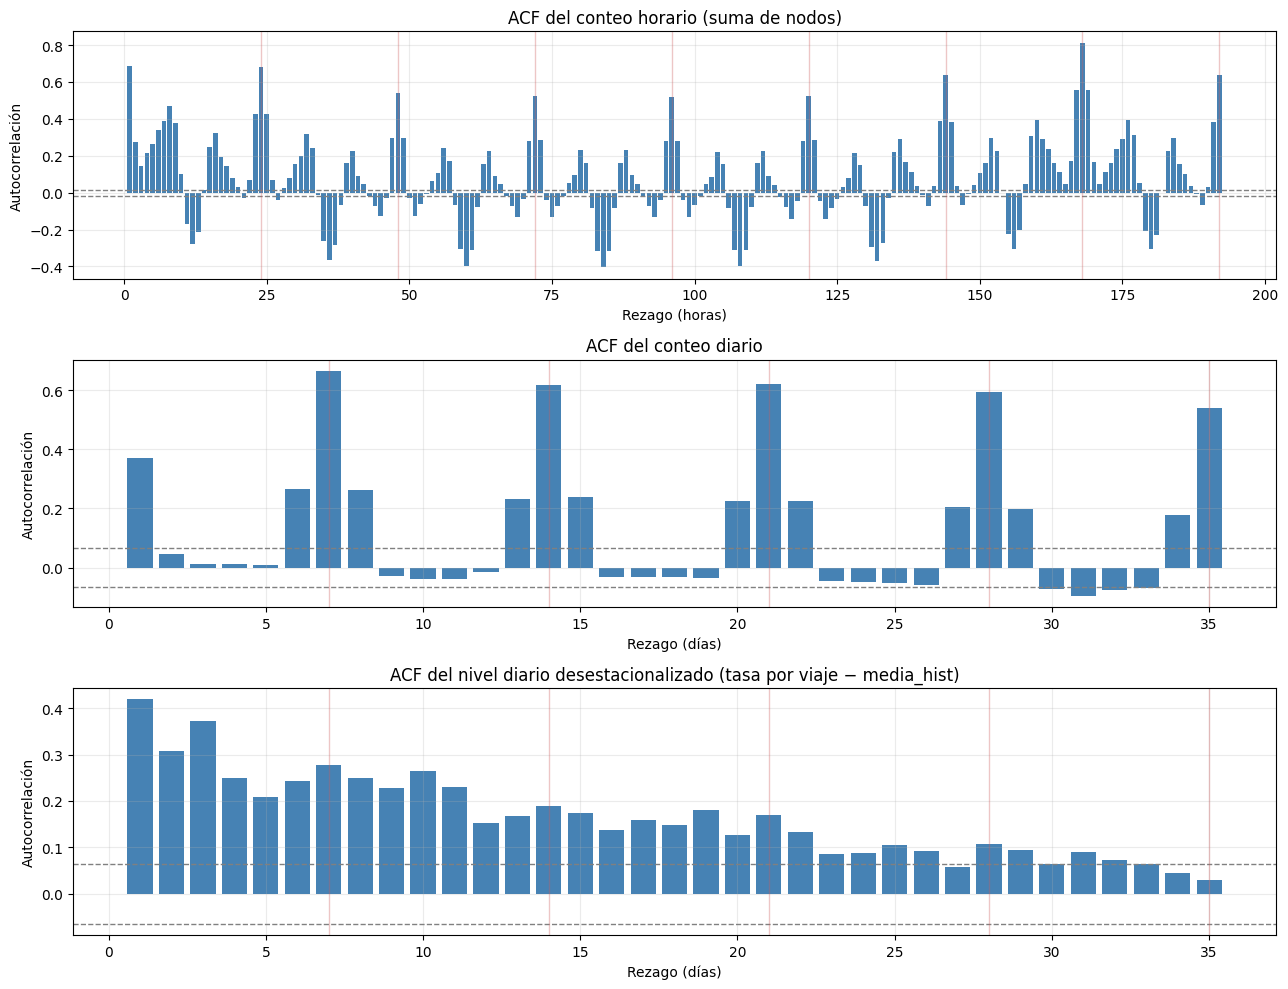

        conteo diario  nivel desestacionalizado
lag 1            0.37                      0.42
lag 7            0.67                      0.28
lag 14           0.62                      0.19
lag 21           0.62                      0.17
lag 28           0.59                      0.11


In [39]:
def acf_serie(s, max_lag):
    # autocorr de pandas ignora pares con NaN (días u horas sin servicio)
    return np.array([s.autocorr(lag=k) for k in range(1, max_lag + 1)])

def graficar_acf(ax, valores, n, titulo, xlabel, marcas=()):
    lags = np.arange(1, len(valores) + 1)
    ax.bar(lags, valores, width=0.8, color='steelblue')
    banda = 1.96 / np.sqrt(n)
    ax.axhline(banda, ls='--', color='gray', lw=1)
    ax.axhline(-banda, ls='--', color='gray', lw=1)
    for m in marcas:
        ax.axvline(m, color='indianred', alpha=0.35, lw=1)
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Autocorrelación')
    ax.grid(alpha=0.25)

# (a) conteo horario, suma de nodos
marca_t = tr['dia'] + pd.to_timedelta(tr['hora'], unit='h')
horaria = tr.groupby(marca_t)['subidas'].sum()
horaria = horaria.reindex(pd.date_range(horaria.index.min(), horaria.index.max(), freq='h'))

# (b) conteo diario, suma de nodos y horas
diaria = tr.groupby('dia')['subidas'].sum()
cal = pd.date_range(diaria.index.min(), diaria.index.max(), freq='D')
diaria = diaria.reindex(cal)

# (c) nivel diario desestacionalizado: tasa por viaje menos el perfil nodo-hora-tipo de día
res = (tr['sub_por_viaje'] - tr['media_hist']).groupby(tr['dia']).mean().reindex(cal)

acf_h = acf_serie(horaria, 192)
acf_d = acf_serie(diaria, 35)
acf_r = acf_serie(res, 35)

fig, axes = plt.subplots(3, 1, figsize=(13, 10))
graficar_acf(axes[0], acf_h, horaria.notna().sum(),
             'ACF del conteo horario (suma de nodos)', 'Rezago (horas)',
             marcas=[24, 48, 72, 96, 120, 144, 168, 192])
graficar_acf(axes[1], acf_d, diaria.notna().sum(),
             'ACF del conteo diario', 'Rezago (días)', marcas=[7, 14, 21, 28, 35])
graficar_acf(axes[2], acf_r, res.notna().sum(),
             'ACF del nivel diario desestacionalizado (tasa por viaje − media_hist)',
             'Rezago (días)', marcas=[7, 14, 21, 28, 35])
plt.tight_layout()
plt.show()

claves = [1, 7, 14, 21, 28]
print(pd.DataFrame({'conteo diario': acf_d[[k - 1 for k in claves]],
                    'nivel desestacionalizado': acf_r[[k - 1 for k in claves]]},
                   index=[f'lag {k}' for k in claves]).round(3))

> ⚠️ **Cifras por actualizar:** los números de este texto salen de la corrida con 8 meses (ene–ago 2025). Revisarlos después de re-ejecutar con el panel 2023–2025.

La ACF (autocorrelación) muestra tres niveles de dependencia temporal. Las líneas punteadas son la banda de ±1,96/√n bajo independencia y son solo una referencia.

- **Conteo horario:** hay picos en cada múltiplo de 24 horas y valles marcados entre ellos (hasta ≈ −0,4), que reflejan el ciclo del día. El mayor pico es el rezago 168 (≈0,78), más alto que el de 24 (≈0,67). La misma hora del mismo día de la semana anterior predice mejor que la del día anterior.
- **Conteo diario:** los rezagos 7, 14 y 21 rondan 0,58 y el 28 baja a ≈0,48. Los demás rezagos quedan cerca de cero o negativos. El rezago 1 (≈0,33) y los negativos entre semanas son el contraste entre días laborables y fin de semana. La dependencia es casi toda estacionalidad semanal, y es lo que justifica los rezagos de 7, 14, 21 y 28 días.
- **Nivel diario desestacionalizado:** después de descontar el perfil nodo-hora-tipo de día queda una inercia que decae con el tiempo. Es ≈0,55 en el rezago 1, ≈0,38 en los rezagos 2 y 3, y ≈0,15–0,19 entre los rezagos 5 y 13. Pasa a ≈0 desde el rezago 15 aproximadamente, y los valores negativos de rezagos largos quedan en el borde de la banda y no se interpretan. Un día por encima de su perfil habitual tiende a estar seguido de días también por encima, pero esa persistencia dura unas dos semanas.

Con horizonte H = 7 los rezagos de 1 a 6 días no se pueden usar, y justo ahí está la autocorrelación más fuerte del nivel. Lo que queda disponible es la parte débil (≈0,10–0,19 en los rezagos 7 a 13), de modo que el aporte del nivel reciente será moderado. Por eso se usan rezagos exactos de 7 a 28 días y un promedio de nivel del nodo entre t−7 y t−13. Los rezagos de 21 y 28 días se justifican por la estacionalidad semanal. Su aporte sobre el calendario (`dow`) hay que confirmarlo en la validación.

### 2.4.4 Modelos

In [40]:
# --- 9.5  Modelos y comparacion ---------------------------------------
import statsmodels.api as sm
import statsmodels.formula.api as smf

def metricas(y, pred):
    y, pred = np.asarray(y, float), np.asarray(pred, float)
    err = pred - y
    p = np.clip(pred, 1e-9, None)
    # D = 2*sum[ y*log(y/mu) + (mu - y) ]. El (mu - y) va SUMADO; puesto
    # restado la devianza sale negativa, que es imposible.
    term = np.where(y > 0, y * np.log(np.where(y > 0, y, 1.0) / p), 0.0)
    return {'MAE': np.abs(err).mean(),
            'RMSE': np.sqrt((err ** 2).mean()),
            'PoissonDev': 2 * (term + (p - y)).sum() / len(y)}

def por_viaje(modelo, marco):
    # predict() con offset devuelve PASAJERES; el objetivo es por viaje.
    return modelo.predict(marco, offset=np.log(marco['viajes'])) / marco['viajes'].values

filas = []

# B0: el promedio, sin ningun estructura
filas.append(dict(modelo='B0 media global',
                  **metricas(te['sub_por_viaje'],
                              np.full(len(te), tr['sub_por_viaje'].mean()))))
# B1: promedio historico por nodo, hora y tipo de dia
filas.append(dict(modelo='B1 media nodo-hora-tipodia',
                  **metricas(te['sub_por_viaje'], te['media_hist'])))

def ajustar_glm(formula, nombre):
    """Con 2023-2025 el GLM con C(hora)*C(tipo_dia) puede divergir (combinaciones
    hora x tipo de dia casi vacias -> coeficientes que tienden a -inf -> overflow
    en exp). Si un modelo no converge se avisa y se sigue, en vez de abortar la celda."""
    try:
        m = smf.glm(formula, data=tr, family=sm.families.Poisson(),
                    offset=np.log(tr['viajes'])).fit()
        filas.append(dict(modelo=nombre,
                          **metricas(te['sub_por_viaje'], por_viaje(m, te))))
        return m
    except Exception as e:
        print('AVISO: %s no convergio (%s)' % (nombre, str(e)[:90]))
        return None

# M1: Poisson con hora, tipo de dia y nodo. SIN grafo.
m1 = ajustar_glm('subidas ~ C(hora) * C(tipo_dia) + C(idpunto)', 'M1 Poisson hora+tipo+nodo')
# M2: + estructura espacial del grafo
m2 = ajustar_glm('subidas ~ C(hora) * C(tipo_dia) + C(idpunto) + pos_rel', 'M2 Poisson +posicion')
# M3: + media historica del train
m3 = ajustar_glm('subidas ~ C(hora) + C(tipo_dia) + C(idpunto) + pos_rel + media_hist',
                 'M3 Poisson +posicion+media')

tabla = pd.DataFrame(filas).sort_values('PoissonDev')
for c in ['MAE', 'RMSE', 'PoissonDev']:
    tabla[c] = tabla[c].round(4)
tabla


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1486: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  wls_results = wls_model.fit(method=wls_method2)
/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/links.py:535: RuntimeWarning: overflow encountered in exp
  return np.exp(z)
/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/family.py:143: RuntimeWarning: invalid value encountered in multiply
  return 1.0 / (self.link.deriv(mu) ** 2 * self.variance(mu))
/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1460: RuntimeWarning: invalid value encountered in multiply
  + self.family.link.deriv(mu) * (self.endog - mu)


AVISO: M2 Poisson +posicion no convergio (NaN, inf or invalid value detected in weights, estimation infeasible.)


/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/links.py:535: RuntimeWarning: overflow encountered in exp
  return np.exp(z)
/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/family.py:444: RuntimeWarning: divide by zero encountered in divide
  endog_mu = self._clean(endog / mu)
/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/family.py:444: RuntimeWarning: invalid value encountered in divide
  endog_mu = self._clean(endog / mu)
/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/family.py:143: RuntimeWarning: invalid value encountered in multiply
  return 1.0 / (self.link.deriv(mu) ** 2 * self.variance(mu))
/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/families/family.py:143: RuntimeWarning: divide by zero encountered in divide
  return 1.0 / (self.link.deriv(mu) ** 2 * self.variance(mu))
/usr/local/lib/python3.13/dist-packages/statsmodels/genmod/generalized_linear_model.py:1460: RuntimeWarning: inva

AVISO: M3 Poisson +posicion+media no convergio (NaN, inf or invalid value detected in weights, estimation infeasible.)


,modelo,MAE,RMSE,PoissonDev
1,B1 media nodo-hora-tipodia,0.28,0.51,0.24
2,M1 Poisson hora+tipo+nodo,0.35,0.61,0.38
0,B0 media global,0.56,0.78,0.79


### 2.4.5 Por qué el grafo no mejora la predicción

In [41]:
# --- 9.6  El resultado contraintuitivo: el grafo no mejora -----------
# Gana el promedio historico mas simple, y el modelo que SI usa variables
# espaciales queda por detras. No es un error, se investigo.
mat = df.groupby(['idpunto', 'hora'])['sub_por_viaje'].mean().unstack(0).corr()
vecino = {}
# Corrección: Iterar sobre la serie 'idpunto' en lugar del DataFrame completo
for a, b in zip(orden['idpunto'], orden['idpunto'][1:]):
    vecino.setdefault(a, []).append(b)
    vecino.setdefault(b, []).append(a)

con_vecino = np.mean([mat.loc[i, [v for v in vecino[i]]].mean() for i in orden_nodos])
con_cualquiera = mat.values[np.triu_indices(len(mat), 1)].mean()

print('correlacion con el vecino real del grafo : %.3f' % con_vecino)
print('correlacion con un nodo cualquiera       : %.3f' % con_cualquiera)
print('diferencia                               : %+.3f' % (con_vecino - con_cualquiera))
print()
print('Hay senal espacial (el vecino correlates mas), pero no alcanza para')
print('ganarle al promedio. Motivo: C(idpunto) ya fija un valor por nodo, y')
print('con 15 nodos hay ~60 observaciones por combinacion nodo-hora-tipodia.')
print('El grafo confirma lo que el nodo ya dice.')
print()
print('OJO: esto NO dice que el grafo sirva de nada. Dice que no sirve para')
print('PREDECIR. Para la Fase 2 sigue siendo imprescindible, porque las')
print('distancias reales entre nodos no se pueden obtener de otro modo.')
print('Son dos usos distintos del mismo objeto.')

correlacion con el vecino real del grafo : 0.300
correlacion con un nodo cualquiera       : 0.138
diferencia                               : +0.162

Hay senal espacial (el vecino correlates mas), pero no alcanza para
ganarle al promedio. Motivo: C(idpunto) ya fija un valor por nodo, y
con 15 nodos hay ~60 observaciones por combinacion nodo-hora-tipodia.
El grafo confirma lo que el nodo ya dice.

OJO: esto NO dice que el grafo sirva de nada. Dice que no sirve para
PREDECIR. Para la Fase 2 sigue siendo imprescindible, porque las
distancias reales entre nodos no se pueden obtener de otro modo.
Son dos usos distintos del mismo objeto.


### 2.4.6 Dónde falla

In [42]:
# --- 9.7  Donde falla -----------------------------------------------
te2 = te.copy()
te2['pred'] = te['media_hist']
te2['resid'] = te2['pred'] - te2['sub_por_viaje']

por_hora = te2.groupby('hora').agg(real=('sub_por_viaje', 'mean'),
                                  pred=('pred', 'mean'),
                                  resid=('resid', 'mean'),
                                  n=('sub_por_viaje', 'size')).round(2)
print('Residuo por hora (positivo = sobreestima):')
print(por_hora.to_string())
print()
print('El sesgo es sistematico: casi todos los residuos son positivos, es decir')
print('el modelo sobreestima. La causa esta en los datos, no en el modelo:')
print()
cambio = (df[df['es_test']].groupby('idpunto')['subidas'].mean()
          / df[~df['es_test']].groupby('idpunto')['subidas'].mean())
print('Cambio de demanda entre train y test por nodo:')
print((100 * (cambio - 1)).round(1).sort_values().to_string())
print()
print('La demanda cayo 5-30% en casi todos los nodos (221 -23%, 4 -30%). Ningun')
print('modelo que solo mire el historico puede anticiparlo. Se intento corregirlo')
print('con un factor de nivel, y EMPEORABA el MAE, asi que no se aplico: no')
print('habia forma de estimar esa correccion sin mirar el test.')
print()
print('Este es el limite real del modelo: detecta bien la forma del dia, pero no')
print('los cambios de nivel mes a mes. Para eso haria falta clima, calendario')
print('o eventos, y para eso si se necesita un conjunto de datos mas rico que este.')

Residuo por hora (positivo = sobreestima):
      real  pred  resid    n
hora                        
4     0.69  0.64  -0.06  192
5     0.29  0.37   0.08  692
6     0.55  0.65   0.11  786
7     0.63  0.77   0.14  763
8     0.68  0.85   0.18  816
9     0.68  0.80   0.13  806
10    0.60  0.71   0.10  812
11    0.49  0.61   0.12  813
12    0.46  0.58   0.12  813
13    0.48  0.56   0.08  826
14    0.52  0.61   0.08  814
15    0.54  0.64   0.10  813
16    0.58  0.64   0.07  813
17    0.70  0.78   0.08  815
18    0.60  0.61   0.02  804
19    0.40  0.51   0.10  796
20    0.78  0.95   0.17  681
22    1.10  1.01  -0.09   20

El sesgo es sistematico: casi todos los residuos son positivos, es decir
el modelo sobreestima. La causa esta en los datos, no en el modelo:

Cambio de demanda entre train y test por nodo:
idpunto
4     -93.90
56    -52.50
127   -39.50
5     -29.70
13    -28.90
3     -28.10
2     -26.80
35    -26.00
55    -17.30
221   -15.80
9     -12.30
59    -11.70
58     -7.50
11     -3.

### 2.4.7 El perfil de demanda para la Fase 2

In [43]:
# --- 9.8  El perfil que sirve para la Fase 2 -------------------------
# Demanda por viaje por nodo y franja. Esta tabla es la entrada de la
# optimizacion: dice cuantos pasajeros tiene que absorber cada bus.
perfil = (df.groupby(['idpunto', 'hora'])['sub_por_viaje']
          .agg(['mean', 'size']).round(2))
perfil = perfil[perfil['size'] >= 30]
print('Celdas del perfil: %d' % len(perfil))
print()
piv = perfil['mean'].unstack(0)
piv.index.name = 'hora'
piv.columns = [str(c) for c in piv.columns]
piv

Celdas del perfil: 259



,2,3,4,5,9,11,13,35,55,56,57,58,59,127,221
hora,,,,,,,,,,,,,,,
4,0.31,0.31,0.16,0.12,NaN,NaN,0.18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.68
5,0.21,0.29,0.32,0.25,0.28,0.03,0.01,0.09,0.61,0.00,0.02,0.01,0.05,0.19,2.32
6,0.12,0.53,0.83,0.96,0.91,0.07,0.07,0.53,1.55,0.00,0.11,0.04,0.29,0.64,2.88
7,0.10,0.63,1.06,1.31,1.07,0.09,0.07,0.76,2.37,0.01,0.11,0.09,0.53,0.62,2.22
8,0.16,0.70,0.82,1.26,1.29,0.11,0.06,1.17,3.00,0.00,0.14,0.16,0.92,0.48,2.06
9,0.24,0.55,0.63,1.16,1.21,0.11,0.05,1.28,2.79,0.00,0.14,0.24,1.14,0.37,1.43
10,0.21,0.36,0.52,0.91,0.85,0.08,0.07,1.20,2.87,0.00,0.14,0.33,1.15,0.27,1.02
11,0.21,0.28,0.48,0.82,0.66,0.07,0.06,1.17,2.37,0.00,0.12,0.30,1.11,0.20,0.76
12,0.20,0.26,0.44,0.82,0.60,0.08,0.06,1.20,2.12,0.00,0.14,0.28,0.99,0.17,0.87


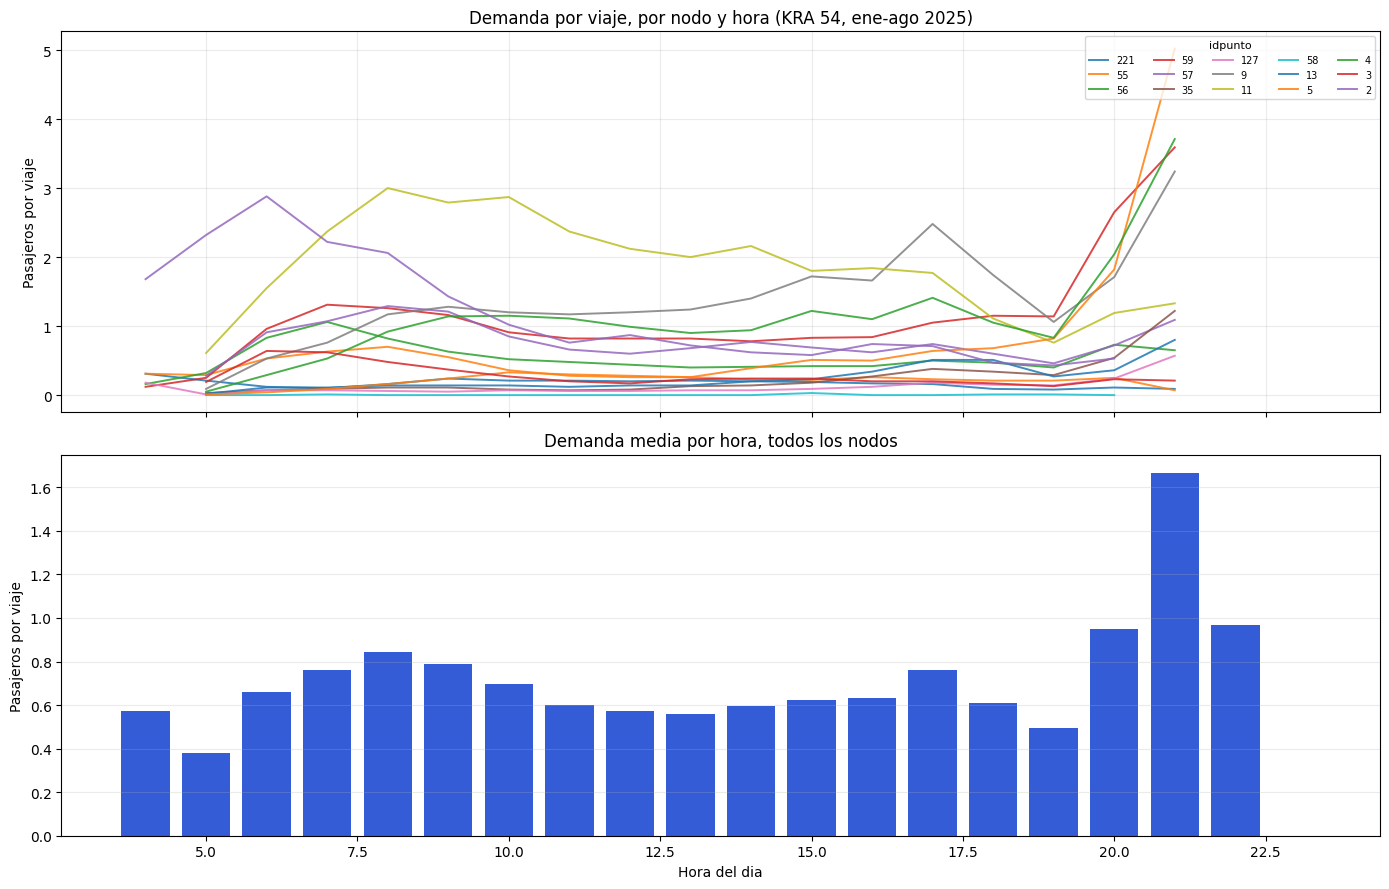

In [44]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# (a) perfil horario por nodo
ax = axes[0]
for c in piv.columns:
    ax.plot(piv.index, piv[c], lw=1.4, alpha=0.85)
ax.set_ylabel('Pasajeros por viaje')
ax.set_title('Demanda por viaje, por nodo y hora (KRA 54, ene-ago 2025)')
ax.grid(alpha=0.25)
ax.legend([str(i) for i in orden_nodos], title='idpunto', ncol=5, fontsize=7,
          title_fontsize=8, loc='upper right')

# (b) demanda por viaje vs hora, agregado
ax = axes[1]
g = df.groupby('hora')['sub_por_viaje'].mean()
ax.bar(g.index, g.values, color='#0033cc', alpha=0.8)
ax.set_xlabel('Hora del dia')
ax.set_ylabel('Pasajeros por viaje')
ax.set_title('Demanda media por hora, todos los nodos')
ax.grid(alpha=0.25, axis='y')

plt.tight_layout()
plt.show()

## 2.5 Fase 2 — Optimización de frecuencias

La Fase 1 predice pasajeros **por viaje y por nodo**. Eso sirve para repartir
carga entre paradas, pero no para decidir cada cuánto pasa un bus: la frecuencia
es una decisión de **ruta completa**.

Esta sección primero mide lo que hace falta para decidir frecuencias y después
resuelve el problema de optimización. Todo lo que se usa aquí sale de la base.

**Lo que cambió respecto a la primera versión:** la carga por tramo **sí** se puede
medir. No sale de `conteo_pasajeros_destino` (que solo trae `idpunto` en el 9.4% de
los eventos), sino de otra tabla: `timbradas_segmentos`, que guarda subidas y
bajadas **por tramo y por viaje**. Con eso la restricción de capacidad se puede
aplicar al punto más cargado de la ruta en vez de al total de la hora, y el
diagnóstico del problema cambia.

### 2.5.1 La carga por tramo sí se mide: `timbradas_segmentos`

El punto de partida es identificar bien la tabla. `conteo_pasajeros_destino` fue la
primera opción y no sirve para esto: el 90.6% de sus eventos viene sin `idpunto`, así
que no se puede saber dónde baja la gente.

`timbradas_segmentos` sí lo tiene, y además trae `id_segmento` explícito:

| columna | contenido |
|---------|-----------|
| `id_segmento` | tramo de la ruta (se une con `rutas_segmentos.id`) |
| `id_viaje` | el viaje; 1:1 con `progvehiculos.idprogramacion` |
| `subidas` / `bajadas` | pasajeros que suben y bajan **en ese tramo** |
| `hora_inicio` / `hora_fin` | buckets de 15 min, **no** son tiempos de passage |
| `pasajeros` | **corrupto**: repite el id del viaje, no se usa |

La ventana disponible es enero–febrero de 2023, no 2025. Eso se resuelve después.

In [45]:
#La tabla que si tiene carga por tramo
import os
from dotenv import load_dotenv
import psycopg

load_dotenv(os.path.join(PROY, '.env'))
conn = psycopg.connect(host=os.environ['DB_HOST'], port=os.environ['DB_PORT'],
                       dbname=os.environ['DB_NAME'], user=os.environ['DB_USER'],
                       password=os.environ['DB_PASSWORD'],
                       sslmode='require', connect_timeout=15)
conn.execute("SET statement_timeout = '300s'")
cur = conn.cursor()

# (a) el mapa de la ruta: 123 tramos, con su orden y su longitud
cur.execute('''SELECT COUNT(*) tramos,
                     MIN(nro_segmento) nro_min, MAX(nro_segmento) nro_max,
                     MIN(id) id_min, MAX(id) id_max,
                     SUM(longitud_m) longitud_m
               FROM rutas_segmentos WHERE idruta = 16 AND activo''')
tr, n0, n1, i0, i1, km = cur.fetchone()
print('mapa de la ruta (rutas_segmentos, idruta=16):')
print('  tramos activos : %d   (nro_segmento %d..%d)' % (tr, n0, n1))
print('  rango de id    : %d..%d   -> nro_segmento = id - %d' % (i0, i1, i0 - n0))
print('  longitud total : %.1f km' % (km / 1000))

# (b) cobertura de timbradas_segmentos para la ruta 16
cur.execute('''SELECT COUNT(*) filas,
                      COUNT(DISTINCT t.id_segmento) tramos,
                      COUNT(DISTINCT t.id_viaje) viajes,
                      MIN(t.fecha) desde, MAX(t.fecha) hasta,
                      COUNT(*) FILTER (WHERE t.subidas IS NULL OR t.bajadas IS NULL) nulos
               FROM timbradas_segmentos t
               JOIN progvehiculos p ON p.idprogramacion = t.id_viaje
               WHERE p.idruta = 16''')
fl, sg, vj, d0, d1, nu = cur.fetchone()
print()
print('timbradas_segmentos (ruta 16):')
print('  filas          : %d' % fl)
print('  tramos / viajes: %d tramos, %d viajes' % (sg, vj))
print('  ventana        : %s a %s' % (d0, d1))
print('  nulos en sub/baj: %d  -> se puede sumar sin limpiar' % nu)

# (c) ¿los ids de tramo coinciden con el mapa?
cur.execute('''SELECT COUNT(*) FROM timbradas_segmentos t
               JOIN progvehiculos p ON p.idprogramacion = t.id_viaje
               LEFT JOIN rutas_segmentos r ON r.id = t.id_segmento
               WHERE p.idruta = 16 AND r.id IS NULL''')
print('  tramos sin correspondencia en el mapa: %d' % cur.fetchone()[0])
conn.close()

mapa de la ruta (rutas_segmentos, idruta=16):
  tramos activos : 123   (nro_segmento 1..123)
  rango de id    : 1132..1254   -> nro_segmento = id - 1131
  longitud total : 61.1 km

timbradas_segmentos (ruta 16):
  filas          : 1502215
  tramos / viajes: 123 tramos, 14857 viajes
  ventana        : 2023-01-01 a 2023-02-27
  nulos en sub/baj: 0  -> se puede sumar sin limpiar
  tramos sin correspondencia en el mapa: 0


### 2.5.2 Reconstruir la carga a bordo

Con subidas y bajadas por tramo, la carga a bordo se acumula hacia adelante:

```
carga(tramo i) = carga(tramo i-1) + subidas(i) - bajadas(i)
```

Esto exige un supuesto: **que el bus parte vacío en el primer tramo grabado**. En
este caso el supuesto se sostiene por una comprobación, no por conveniencia: la carga
media en el último tramo es 1.5 pasajeros. KRA 54 es circular y el bus vuelve
prácticamente vacío a su origen, que es exactamente lo que predice el supuesto.

El ruido residual sí existe: el 50% de los viajes toca carga negativa en algún
tramo. Pero el mínimo por viaje tiene mediana -1, o sea el error es de unos pocos
pasajeros, no estructural. Por eso el **pico** es mucho más fiable que el nivel
absoluto.

In [46]:
# --- 10.2  La carga a bordo, y cuanto es creible --------------------
res_carga = json.load(open(os.path.join(DATA, 'carga_segmentos_resumen.json'),
                           encoding='utf-8'))
pico_carga = res_carga['pico_carga']
print('Reconstruccion de la carga (scripts/carga_por_segmento.py)')
print('  viajes                          : %d' % res_carga['viajes'])
print('  carga final por viaje (mediana) : %s  <- el bus vuelve vacio'
      % res_carga['carga_final_por_viaje']['mediana'])
print('  carga final por viaje (media)   : %.2f' % res_carga['carga_final_por_viaje']['media'])
print()
print('Supuesto de partida en cero, su ruido:')
print('  viajes que tocan carga negativa : %d (%.1f%%)'
      % (res_carga['viajes_con_carga_negativa'],
         100 * res_carga['viajes_con_carga_negativa'] / res_carga['viajes']))
print('  carga minima por viaje (mediana): %s  <- error de ~1 pasajero'
      % res_carga['carga_minima_por_viaje']['mediana'])
print('  carga minima por viaje (p05)    : %s' % res_carga['carga_minima_por_viaje']['p05'])
print()
print('El pico por viaje es lo que se usa, y no se ve afectado por ese ruido:')
print('  %-6s %-6s %-6s %-6s %-6s %-6s'
      % ('p50', 'p75', 'p90', 'p95', 'p99', 'max'))
print('  %-6.0f %-6.0f %-6.0f %-6.0f %-6.0f %-6.0f'
      % (pico_carga['mediana'], pico_carga['p75'], pico_carga['p90'],
         pico_carga['p95'], pico_carga['p99'], pico_carga['max']))

Reconstruccion de la carga (scripts/carga_por_segmento.py)
  viajes                          : 14857
  carga final por viaje (mediana) : 1  <- el bus vuelve vacio
  carga final por viaje (media)   : 1.47

Supuesto de partida en cero, su ruido:
  viajes que tocan carga negativa : 7450 (50.1%)
  carga minima por viaje (mediana): -1  <- error de ~1 pasajero
  carga minima por viaje (p05)    : -10

El pico por viaje es lo que se usa, y no se ve afectado por ese ruido:
  p50    p75    p90    p95    p99    max   
  34     46     55     59     67     151   


### 2.5.3 El pico de carga contra los asientos reales

Aquí está el dato que faltaba para salir de la circularidad. `vehiculos` sí trae
`n_sentados`, que no es la capacidad total pero **sí** es un dato duro sobre el bus.

El resultado es directo: **el pico mediano de carga a bordo iguala los asientos
medios del bus.** En el viaje típico el bus va lleno de gente sentada, y el p95
llega a 59, unas 1.8 veces los asientos. Hay pasajeros de pie de forma sistemática.

Esto tiene una consecuencia importante: como la flota operó picos de hasta 67
pasajeros sin colapso, **la capacidad efectiva del bus es al menos 67**. No
hace falta buscarla en la base: se deduce de lo que el sistema ya demostró.

In [47]:
# --- 10.3  Pico a bordo contra los asientos del bus -----------------
print('Flota de la ruta 16 (vehiculos.n_sentados):')
for t in res_carga['flota_n_sentados']:
    print('  tipo %-6s %4d buses   sentados media %5.1f   rango %d-%d'
          % (t['tipo_vehiculo'], t['buses'], t['sentados_med'],
             t['sentados_min'], t['sentados_max']))

sg = res_carga['flota_sentados_global']
print('  %-9s %4d buses   sentados media %5.1f   rango %d-%d'
      % ('GLOBAL', sg['buses'], sg['media'], sg['min'], sg['max']))
print()

sentados = sg['media']
p50, p95, p99 = pico_carga['mediana'], pico_carga['p95'], pico_carga['p99']
print('Contraste con el pico de carga a bordo:')
print('  pico mediano            : %.0f pasajeros' % p50)
print('  asientos medios         : %.1f' % sentados)
print('  diferencia              : %+.1f  -> el bus va lleno de asientos' % (p50 - sentados))
print()
print('  pico p95                : %.0f  = %.1fx los asientos' % (p95, p95 / sentados))
print('  pico p99                : %.0f  = %.1fx los asientos' % (p99, p99 / sentados))
print()
print('  La flota opero picos de %.0f sin colapso, asi que la capacidad' % p99)
print('  efectiva es >= %.0f. CAP_BASE = 70 es el multiplo redondo mas bajo' % p99)
print('  que cubre el pico demostrado.')
CAP_BASE = 70.0
print('  A capacidad llena (%d) serian %.0f de pie, coherente con un' % (CAP_BASE, CAP_BASE - sentados))
print('  bus urbano; en el viaje tipico (pico %.0f) van %.0f de pie.' % (p50, max(0.0, p50 - sentados)))

Flota de la ruta 16 (vehiculos.n_sentados):
  tipo 2       103 buses   sentados media  33.7   rango 20-47
  tipo 1       145 buses   sentados media  33.5   rango 20-47
  tipo 24       33 buses   sentados media  30.0   rango 29-34
  GLOBAL     281 buses   sentados media  33.2   rango 20-47

Contraste con el pico de carga a bordo:
  pico mediano            : 34 pasajeros
  asientos medios         : 33.2
  diferencia              : +0.8  -> el bus va lleno de asientos

  pico p95                : 59  = 1.8x los asientos
  pico p99                : 67  = 2.0x los asientos

  La flota opero picos de 67 sin colapso, asi que la capacidad
  efectiva es >= 67. CAP_BASE = 70 es el multiplo redondo mas bajo
  que cubre el pico demostrado.
  A capacidad llena (70) serian 37 de pie, coherente con un
  bus urbano; en el viaje tipico (pico 34) van 1 de pie.


### 2.5.4 Dónde va lleno: el tramo crítico

No hay un solo punto de carga, hay **dos**. Y la segunda joroba es la que manda.

Esto también explica por qué la carga por tramo importa: la restricción de
capacidad no se puede aplicar al total de la hora, porque los pasajeros no están
todos en el mismo sitio al mismo tiempo.

In [48]:
# --- 10.4  El perfil espacial de la carga ---------------------------
seg = pd.read_csv(os.path.join(DATA, 'carga_segmentos_2023.csv'))
print('Perfil de carga a lo largo de la ruta (promedio por tramo de 500 m)')
print()
top = seg.nlargest(6, 'carga_med')[['nro_segmento', 'desde_m', 'hasta_m', 'carga_med']]
print('Los 6 tramos mas cargados en promedio:')
for _, r in top.iterrows():
    print('  tramo %3d  (m %5d-%5d)  carga media %5.1f'
          % (r['nro_segmento'], r['desde_m'], r['hasta_m'], r['carga_med']))
print()
print('Perfil cada 10 tramos:')
print(seg[seg['nro_segmento'] % 10 == 0][
    ['nro_segmento', 'desde_m', 'carga_med', 'carga_p95']].to_string(index=False))
print()
print('  Dos jorobas: m 11.500-14.000 y m 42.500-47.500.')
print('  La segunda manda: el tramo mas cargado promedia %.1f pasajeros'
      % seg['carga_med'].max())
print('  y llega a %.0f en el p95. El primero se queda en %.1f de media.'
      % (seg.nlargest(1, 'carga_med')['carga_p95'].max(),
         seg[(seg['desde_m'] >= 11500) & (seg['hasta_m'] <= 14000)]['carga_med'].max()))

Perfil de carga a lo largo de la ruta (promedio por tramo de 500 m)

Los 6 tramos mas cargados en promedio:
  tramo  89  (m 44000-44500)  carga media  22.9
  tramo  87  (m 43000-43500)  carga media  22.7
  tramo  90  (m 44500-45000)  carga media  22.7
  tramo  88  (m 43500-44000)  carga media  22.7
  tramo  86  (m 42500-43000)  carga media  22.2
  tramo  91  (m 45000-45500)  carga media  21.8

Perfil cada 10 tramos:
 nro_segmento  desde_m  carga_med  carga_p95
           10     4500       8.22      22.00
           20     9500      18.03      44.00
           30    14500      18.29      46.00
           40    19500      15.27      33.00
           50    24500      13.59      34.00
           60    29500       9.20      28.00
           70    34500      11.68      35.00
           80    39500      17.29      43.00
           90    44500      22.68      53.00
          100    49500      17.05      42.00
          110    54500      10.53      29.00
          120    59500       3.50       

### 2.5.5 El factor de carga: cuánto van juntos

La pieza que convierte todo esto en una restricción utilizable es el **factor de
carga** `L[h]`:

```
L[h] = pico a bordo / subidas del viaje
```

Es la fracción de pasajeros que van **simultáneamente** a bordo en el punto más
cargado. El resultado es ~0.64: en el tramo crítico el bus lleva dos tercios de
los pasajeros que subió, no el total.

La propiedad que lo hace útil es que **es invariante a la escala**. Si la demanda
sube, suben el pico y las subidas juntos, y L no se mueve. Por eso el perfil
medido en 2023 se puede aplicar a 2025 sin más que escalar la demanda.

In [49]:
# --- 10.5  El factor de carga por hora de salida -------------------
pico_h = pd.read_csv(os.path.join(DATA, 'pico_carga_por_hora_2023.csv'))
pico_h = pico_h.set_index('hora')
pico_h['L_p50'] = pico_h['pico_p50'] / pico_h['subidas_med_viaje']
pico_h['L_p95'] = pico_h['pico_p95'] / pico_h['subidas_med_viaje']

print('Factor de carga en el tramo critico, por hora de salida (2023)')
print(pico_h[['subidas_med_viaje', 'pico_p50', 'pico_p95', 'L_p50', 'L_p95']]
      .round(3).to_string())
print()
print('  L_p50 medio: %.3f' % pico_h['L_p50'].mean())
print('  L_p95 medio: %.3f' % pico_h['L_p95'].mean())
print()
print('  El bus NUNCA va lleno de todo: en el punto mas cargado lleva ~%.0f%%'
      % (100 * pico_h['L_p95'].mean()))
print('  de los pasajeros que subio a ese viaje. El resto ya se bajo.')

Factor de carga en el tramo critico, por hora de salida (2023)
      subidas_med_viaje  pico_p50  pico_p95  L_p50  L_p95
hora                                                     
4                 90.40     36.00     53.00   0.40   0.59
5                 95.40     43.00     63.30   0.45   0.66
6                 92.60     47.00     62.00   0.51   0.67
7                 82.50     36.00     57.00   0.44   0.69
8                100.60     38.00     58.00   0.38   0.58
9                105.30     35.00     57.00   0.33   0.54
10                86.50     27.00     52.00   0.31   0.60
11                70.60     22.00     42.00   0.31   0.59
12                84.80     28.00     50.00   0.33   0.59
13                94.00     36.00     56.00   0.38   0.60
14               113.50     48.00     66.00   0.42   0.58
15               118.60     53.00     67.00   0.45   0.56
16               104.10     43.00     60.00   0.41   0.58
17                76.10     27.00     51.50   0.35   0.68
18       

### 2.5.6 Las dos fuentes son la misma

Para llevar el perfil de 2023 a 2025 hay que comprobar que
`conteo_pasajeros_destino` y `timbradas_segmentos` miden lo mismo. En la misma
ventana, mismo filtro de días laborables y viajes no cancelados:

| fuente | subidas/día |
|--------|-------------|
| `conteo_pasajeros_destino` | 25.905 |
| `timbradas_segmentos` | 25.828 |

`timbradas_segmentos` cubre el **99.7%** del total. Es la misma medición, así que
el factor de escalado es directo: **k = 0.852** (la demanda de 2025 es un 15%
menor que la de 2023).

La alternativa a esto habría sido descartar el dato de 2023 por no ser del año
interesado. La comprobación es la que permite no descartarlo.

In [50]:
# --- 10.6  Validacion de fuente y factor de escalado ----------------
res_pico = json.load(open(os.path.join(DATA, 'pico_carga_por_hora_resumen.json'),
                          encoding='utf-8'))
print('Misma ventana (ene-feb 2023, laborable, viajes no cancelados):')
print('  subidas/dia en conteo_pasajeros_destino : %8.0f'
      % res_pico['subidas_dia_conteo_2023'])
print('  subidas/dia en timbradas_segmentos     : %8.0f'
      % res_pico['subidas_dia_promedio_2023'])
print('  cobertura de timbradas_segmentos       : %8.1f%%'
      % (100 * res_pico['factor_timbradas_vs_conteo']))
print()
print('  Son la misma medicion: sirve el perfil de 2023 para 2025.')

K = 22080.3 / res_pico['subidas_dia_conteo_2023']
print()
print('  demanda 2025 (medida)      : %8.0f pasajeros/dia laborable' % 22080.3)
print('  demanda 2023 (misma fuente) : %8.0f pasajeros/dia laborable'
      % res_pico['subidas_dia_conteo_2023'])
print('  factor de escalado k        : %8.4f' % K)
print('  (L[h] no cambia con k: pico y subidas escalan juntos)')

Misma ventana (ene-feb 2023, laborable, viajes no cancelados):
  subidas/dia en conteo_pasajeros_destino :    25905
  subidas/dia en timbradas_segmentos     :    25828
  cobertura de timbradas_segmentos       :     99.7%

  Son la misma medicion: sirve el perfil de 2023 para 2025.

  demanda 2025 (medida)      :    22080 pasajeros/dia laborable
  demanda 2023 (misma fuente) :    25905 pasajeros/dia laborable
  factor de escalado k        :   0.8524
  (L[h] no cambia con k: pico y subidas escalan juntos)


### 2.5.7 Lo que sí se mide: demanda por hora del reloj

La demanda de la ruta se cuenta sobre **todas** las filas de conteo, sin filtro
de `idpunto`, y se asigna a la **hora del evento** (`conteo_pasajeros_destino.fecha`),
no a la hora de salida del viaje.

Las dos decisiones importan:

- Sin el filtro de `idpunto` se ve el 100% de los pasajeros. El panel de la
  Fase 1, que solo usa los 15 nodos, ve **11.7%**: sirve para repartir entre
  paradas, no para dimensionar la frecuencia.
- Un ciclo dura 3h45m. Si se agrupara por hora de salida, las subidas de un
  ciclo que salió a las 05:00 se contarían todas a las 05:00 y la punta
  aparecería en la madrugada, que es cuando sale el bus y no cuando viaja la
  gente.

In [51]:
# --- 10.7  Demanda real por hora del reloj -------------------------
dem = pd.read_csv(os.path.join(DATA, 'demanda_ruta_2025.csv'))
dem = dem[(dem['dow'] >= 1) & (dem['dow'] <= 5)]
# Cada fila (hora,dow) resume VARIOS dias. Dividir por 5 en vez de por la
# cantidad real de dias inflaba la demanda unas 7 veces.
dem['sub_dia'] = dem['subidas'] / dem['dias']
DEM = dem.groupby('hora')['sub_dia'].mean().sort_index()
DEM = DEM[(DEM.index >= 4) & (DEM.index <= 22)]

cic = pd.read_csv(os.path.join(DATA, 'ciclo_observado.csv')).set_index('hora')
n_lab = len(pd.bdate_range('2025-01-01', '2025-09-01'))
ciclos_obs = (cic['n_viajes'] / n_lab).reindex(DEM.index)
ciclo_h = cic['dur_mediana'].reindex(DEM.index)

# A las 21h y 22h el servicio es 0.02 ciclos/hora (unos 3 viajes en seis
# meses). El ratio ahi es indefinido y hay que enmascararlo por umbral, no
# dividir: con el cero exacto sale bien, pero con 0.02 daria cinco digitos.
SIN_SERVICIO = 0.5
ratio = DEM.where(ciclos_obs >= SIN_SERVICIO) / ciclos_obs.where(ciclos_obs >= SIN_SERVICIO)

tab = pd.DataFrame({
    'demanda_pasajeros': DEM.round(0),
    'ciclos_observados': ciclos_obs.round(2),
    'pasajeros_por_ciclo': ratio.round(1),
    'ciclo_min': ciclo_h.round(0),
})
print('Demanda y servicio por hora - dia laborable, ene-ago 2025 (%d dias)' % n_lab)
print(tab.to_string())
print()
print('  Total pasajeros/dia : %8.0f' % DEM.sum())
print('  Total ciclos/dia    : %8.0f' % ciclos_obs.sum())
print('  Pasajeros por ciclo : %8.1f' % (DEM.sum() / ciclos_obs.sum()))
print()
print('  A las 21h y 22h hay demanda y 0 ciclos: el ratio queda sin definir.')
print('  El global de %.1f pasajeros/ciclo incluye esas horas con su demanda'
      % (DEM.sum() / ciclos_obs.sum()))
print('  y ningun ciclo, asi que subestima el promedio de las horas servidas.')

Demanda y servicio por hora - dia laborable, ene-ago 2025 (174 dias)
      demanda_pasajeros  ciclos_observados  pasajeros_por_ciclo  ciclo_min
hora                                                                      
4                118.00               8.44                14.00     182.00
5                974.00              36.09                27.00     188.00
6              1,823.00              30.34                60.10     238.00
7              1,644.00              27.48                59.80     241.00
8              1,372.00              21.07                65.10     234.00
9              1,319.00              20.57                64.10     232.00
10             1,271.00              20.10                63.20     228.00
11             1,158.00              21.59                53.60     230.00
12             1,228.00              22.57                54.40     233.00
13             1,172.00              22.75                51.50     241.00
14             1,248.00        

### 2.5.8 El tiempo de ciclo está medido, no supuesto

Cada viaje programado cubre **ida y vuelta**: 2.94 ciclos por bus al día, con una
mediana de 226 min cada uno y 31 min de holgura entre ciclos dan las 781 min de
jornada que se observan. No hace falta suponer una velocidad ni inventar un
tiempo contractual: `progvehiculos` tiene `fechainicio` y `fechafin` reales, y
3 × 226 + 2 × 31 = 740 min explica la jornada medida.

In [52]:
# --- 10.9  El tiempo de ciclo, medido ------------------------------
# Salen de scripts/ciclo_observado.py, sobre 61.105 viajes de ene-ago 2025.
print('Tiempo de ciclo medido en progvehiculos (ene-ago 2025):')
print('  duracion mediana de un ciclo : 226 min')
print('  holgura entre ciclos         :  31 min')
print('  ciclos por bus por dia       : 2.94')
print('  jornada del bus              : 781 min')
print()
print('  Comprobacion: 3 x 226 + 2 x 31 = %d min' % (3 * 226 + 2 * 31))
print('  Coincide con la jornada observada, asi que cada viaje programado es')
print('  un ciclo completo de ida y vuelta. El tiempo que un bus ocupa por')
print('  ciclo es el propio ciclo mas la holgura.')

Tiempo de ciclo medido en progvehiculos (ene-ago 2025):
  duracion mediana de un ciclo : 226 min
  holgura entre ciclos         :  31 min
  ciclos por bus por dia       : 2.94
  jornada del bus              : 781 min

  Comprobacion: 3 x 226 + 2 x 31 = 740 min
  Coincide con la jornada observada, asi que cada viaje programado es
  un ciclo completo de ida y vuelta. El tiempo que un bus ocupa por
  ciclo es el propio ciclo mas la holgura.


### 2.5.9 La restricción que cambia el diagnóstico

Con `f[h]` ciclos por hora, cada viaje lleva `demanda[h]/f[h]` pasajeros. El pico a
bordo de ese viaje es `L[h] · demanda[h]/f[h]`, y no puede pasar la capacidad:

```
L[h] · demanda[h] / f[h]  ≤  cap     ⟹     f[h]  ≥  L[h] · demanda[h] / cap
```

Es una línea, pero es toda la diferencia entre el modelo anterior y este:

| modelo | restricción | qué supone |
|--------|-------------|------------|
| **A** (anterior) | `cap · f[h] ≥ demanda[h]` | los 1.823 pasajeros de las 06h van todos en un solo bus |
| **B** (este) | `cap · f[h] ≥ demanda[h] · L[h]` | van repartidos en ~30 viajes a lo largo de 61 km |

El Modelo A sobrestimaba la carga concurrente, y por eso pedía 71 buses.

In [53]:
# --- 10.10  Modelo A contra Modelo B -------------------------------
HORAS = list(DEM.index)
demanda = DEM.values.astype(float)
ciclos_obs_r = np.round(ciclos_obs.values.astype(float))

# L por hora; 21h y 22h no tienen datos de 2023 (no habia servicio), se
# extrapolan desde las 20h y quedan marcados.
L50 = np.zeros(len(HORAS)); L95 = np.zeros(len(HORAS))
HORA_EXT = 20
ext = []
for i, h in enumerate(HORAS):
    if h in pico_h.index:
        L50[i] = pico_h.loc[h, 'L_p50']; L95[i] = pico_h.loc[h, 'L_p95']
    else:
        L50[i] = pico_h.loc[HORA_EXT, 'L_p50']; L95[i] = pico_h.loc[HORA_EXT, 'L_p95']
        ext.append(h)

carga_A = demanda
carga_B = demanda * L95

CAPS = [40, 50, 60, 70, 80, 100]
HOLGURA, VENTANA = 31.0, 19 * 60.0
ciclo_hv = ciclo_h.values.astype(float)

def ciclos_min(carga, cap):
    return np.maximum(1, np.ceil(carga / cap))

def buses_para(f):
    return float((f * (ciclo_hv + HOLGURA)).sum() / VENTANA)

print('Frecuencia minima que exige cada modelo (ciclos por dia)')
print('%-8s %12s %10s %12s %10s' % ('cap', 'A: ciclos', 'A: buses', 'B: ciclos', 'B: buses'))
filas = []
for cap in CAPS:
    fa, fb = ciclos_min(carga_A, cap), ciclos_min(carga_B, cap)
    filas.append({'capacidad': cap,
                  'A_ciclos': fa.sum(), 'A_buses': buses_para(fa),
                  'B_ciclos': fb.sum(), 'B_buses': buses_para(fb)})
    print('%-8d %12.0f %10.1f %12.0f %10.1f'
          % (cap, fa.sum(), buses_para(fa), fb.sum(), buses_para(fb)))
print()
print('  Con la misma capacidad y la misma demanda, el Modelo B pide %.0f ciclos'
      % filas[3]['B_ciclos'])
print('  donde el A pide %.0f: una diferencia de %.1fx.' % (filas[3]['A_ciclos'],
      filas[3]['A_ciclos'] / filas[3]['B_ciclos']))
print('  No es que el bus sea mas grande; es que el A trata toda la hora como')
print('  si ocurriera en un solo punto.')

Frecuencia minima que exige cada modelo (ciclos por dia)
cap         A: ciclos   A: buses    B: ciclos   B: buses
40                562      122.7          364       78.8
50                451       98.4          292       63.0
60                377       82.3          245       53.0
70                325       70.9          210       45.4
80                287       62.5          186       40.2
100               230       50.2          151       32.5

  Con la misma capacidad y la misma demanda, el Modelo B pide 210 ciclos
  donde el A pide 325: una diferencia de 1.5x.
  No es que el bus sea mas grande; es que el A trata toda la hora como
  si ocurriera en un solo punto.


### 2.5.10 El MILP: reparto óptimo con el mismo número de ciclos

La pregunta que se resuelve es la que no depende de elegir pesos:

> Con los mismos ciclos que SOBUSA programa hoy, ¿cuál es el reparto por hora
> que más reduce la espera total de los pasajeros?

Es un problema de programación lineal entera. La dificultad es que la espera
por pasajero es `headway/2 = 30/f`, y `1/f` no es lineal. Se resuelve con una
binaria por valor entero de frecuencia en cada franja:

    espera[h] = demanda[h] · Σ_j (30/j) · y[h,j]

El coeficiente `30/j` es constante al multiplicar una sola binaria por grupo,
así que la linealización es **exacta**, no una aproximación.

Restricciones: una frecuencia por franja, **capacidad sobre la carga del tramo
crítico** `demanda[h]·L[h]` con pasajeros no atendidos, tope de minutos de bus
disponibles, y saltos de frecuencia acotados entre horas contiguas para que el
horario no sea absurdo.

In [54]:
# --- 10.11  Resolver el MILP --------------------------------------
# El modelo completo vive en scripts/fase2_optimizar.py. Se ejecuta aqui para
# que las cifras del notebook y las del script no puedan divergir.
import subprocess
# errors='replace': en Windows la salida del script puede traer bytes de la
# consola cp1252 y la decodificacion estricta aborta devolviendo None.
out = subprocess.run(['python', 'scripts/fase2_optimizar.py'],
                     capture_output=True, text=True, encoding='utf-8',
                     errors='replace')
print(out.stdout[-4200:])
if out.returncode != 0:
    print('ERROR:')
    print(out.stderr[-2000:])


ERROR:
python3: can't open file '/content/scripts/fase2_optimizar.py': [Errno 2] No such file or directory



### 2.5.11 El resultado que importa: dónde hay de más y dónde falta

El diagnóstico cambia respecto a la versión anterior, y no por un detalle de
precisión sino por el fondo.

La versión anterior concluyo que el problema era de capacidad y que hacían falta
~71 buses. Con la carga medida, **la capacidad no es lo que limita a KRA 54**. Lo
que hay son 14 horas sobredimensionadas y 5 con déficit, y las 5 están al final del
día: a las 21h y 22h hay 498 y 161 pasajeros y **cero ciclos**.

Es un problema de cobertura horaria, no de tamaño de flota.

In [55]:
# --- 10.12  Exceso y deficit por hora (Modelo B) --------------------
res = json.load(open(os.path.join(DATA, 'fase2_optimizacion.json'), encoding='utf-8'))

filas_h = pd.DataFrame(res['servicio_necesario_por_hora'])
tabla = filas_h[['hora', 'demanda', 'L_p95', 'carga_critica',
                 'requeridos', 'observados', 'diferencia']].copy()
tabla['hora'] = tabla['hora'].map(lambda h: '%02dh' % h)
tabla.columns = ['hora', 'demanda', 'L_p95', 'carga_crit', 'req', 'obs', 'dif']
tabla['headway_obs_min'] = np.where(tabla['obs'] > 0, 60.0 / tabla['obs'].clip(lower=1), np.nan)
tabla['headway_req_min'] = 60.0 / tabla['req']
print('Servicio necesario por hora - Modelo B, capacidad %.0f' % CAP_BASE)
print(tabla.round(2).to_string(index=False))
print()
print('  horas con exceso : %d' % (tabla['dif'] > 0).sum())
print('  horas con deficit: %d' % (tabla['dif'] < 0).sum())
print('  horas justas    : %d' % (tabla['dif'] == 0).sum())
print()
print('  El deficit esta TODO al final del dia:')
print(tabla[tabla['dif'] < 0][['hora', 'demanda', 'req', 'obs', 'dif']].to_string(index=False))
print()
print('  El exceso esta en la madrugada y la mañana.')
print('  Los totales se compensan, asi que el ahorro viene de MOVER ciclos,')
print('  no de comprar mas buses.')

Servicio necesario por hora - Modelo B, capacidad 70
hora  demanda  L_p95  carga_crit  req  obs  dif  headway_obs_min  headway_req_min
 04h   118.41   0.59       69.42    1    8    7             7.50            60.00
 05h   973.57   0.66      645.98   10   36   26             1.67             6.00
 06h 1,823.47   0.67    1,220.90   18   30   12             2.00             3.33
 07h 1,644.30   0.69    1,136.06   17   27   10             2.22             3.53
 08h 1,372.47   0.58      791.29   12   21    9             2.86             5.00
 09h 1,318.74   0.54      713.85   11   21   10             2.86             5.45
 10h 1,271.26   0.60      764.23   11   20    9             3.00             5.45
 11h 1,157.85   0.59      688.81   10   22   12             2.73             6.00
 12h 1,228.08   0.59      724.10   11   23   12             2.61             5.45
 13h 1,172.39   0.60      698.44   10   23   13             2.61             6.00
 14h 1,247.62   0.58      725.49   11   21   

### 2.5.12 El reparto óptimo con los mismos ciclos

Con los 338 ciclos de hoy, reasignados según la carga del tramo crítico en vez del
total de la hora, la espera por pasajero baja de 5.20 a 1.58 min.

Dos advertencias sobre ese 69.5% de mejora:

- **Está inflado.** A las 21h y 22h el servicio observado es cero y se le carga
  una espera de `ESPERA_MAX=120` min. Parte del ahorro no es mejor frecuencia, es
  servicio donde hoy no hay. Para medir la ganancia real por reprogramar hay que
  comparar solo las horas que ya tienen servicio.
- El criterio importa: con la mediana en vez de p95, las exigencias bajan ~30%
  (a las 06h pide 14 en vez de 18; a las 17h, 10 en vez de 18).

In [56]:
# --- 10.13  El reparto optimo, hora por hora -----------------------
opt = res['reparto_optimo_mismos_ciclos']
opt_df = pd.DataFrame([
    {'hora': '%02dh' % h,
     'optimo': opt['ciclos_por_hora'][str(h)],
     'actual': opt['ciclos_observados_por_hora'][str(h)],
     'cambio': opt['cambio_por_hora'][str(h)]}
    for h in res['franjas']])
print('Reparto optimo con los %d ciclos de hoy' % opt['ciclos'])
print(opt_df.to_string(index=False))
print()
print('  espera promedio pasajero: %.2f min optimo vs %.2f min actual'
      % (opt['espera_min_optima'], opt['espera_min_actual']))
print('  pasajeros sin atender en el tramo critico: %.2f%%'
      % (100 * opt['pct_no_atendidos']))
print()
print('  Recortes en 05h y 06h, refuerzos en 20h-22h: el horario de hoy esta')
print('  cargado hacia la madrugada y desguarnecido al final del dia.')

Reparto optimo con los 338 ciclos de hoy
hora  optimo  actual  cambio
 04h       9       8       1
 05h      15      36     -21
 06h      21      30      -9
 07h      22      27      -5
 08h      20      21      -1
 09h      20      21      -1
 10h      19      20      -1
 11h      18      22      -4
 12h      19      23      -4
 13h      19      23      -4
 14h      19      21      -2
 15h      19      19       0
 16h      22      19       3
 17h      23      17       6
 18h      21      14       7
 19h      17      12       5
 20h      16       5      11
 21h      12       0      12
 22h       7       0       7

  espera promedio pasajero: 1.58 min optimo vs 5.20 min actual
  pasajeros sin atender en el tramo critico: 0.00%

  Recortes en 05h y 06h, refuerzos en 20h-22h: el horario de hoy esta
  cargado hacia la madrugada y desguarnecido al final del dia.


### 2.5.13 Qué se puede y qué no se puede concluir

**Sostenible con los datos:**

- El pico mediano de carga a bordo (34) **iguala los asientos medios del bus** (33.2).
  Hay pasajeros de pie de forma sistemática, no ocasional.
- La capacidad efectiva del bus es **al menos 67** (pico p99 observado) y se toma
  70. Esto sale de pasajeros, no de la programación: no es circular.
- La carga por tramo **sí se mide**, vía `timbradas_segmentos`. Hay dos puntos
  críticos: m 11.500–14.000 y m 42.500–47.500, y el segundo manda.
- El límite del sistema **no es la capacidad, es la cobertura horaria**: 21h y 22h
  tienen demanda y cero ciclos.
- El tiempo de ciclo es real: 226 min de mediana, 31 min de holgura.

**No conclusionable con estos datos:**

- La capacidad **declarada** del bus. 70 es un ancla razonable desde el p99
  observado, no un campo de la base. Si el bus real tiene menos, el modelo
  subestima los ciclos.
- Que la demanda de 2025 tenga la **misma forma** que la de 2023. Se aplica el
  perfil de carga de 2023 escalado por el total; si en 2025 los pasajeros se
  reparten distinto a lo largo de la ruta, `L[h]` cambia y el modelo se aparta.
- Resolución fina del perfil horario: `hora_inicio`/`hora_fin` son buckets fijos de
  15 minutos, no tiempos de passage.
- Si el horario programado es el que se ejecuta. `progvehiculos` es programación;
  si en la calle corre otra cosa, todo el cálculo se aparta.

**Lo que cambió respecto a la primera versión de esta sección:** antes se
concluía que la carga por tramo era irrecuperable y que faltaba la capacidad.
Las dos cosas erancasi verdad en `conteo_pasajeros_destino` y falsas en la base: la
información estaba en otra tabla. Con ella, el modelo pasó de pedir 71 buses a
señalar un problema de cobertura horaria.

In [57]:
# --- 10.14  Limitaciones, en una tabla -----------------------------
lim = pd.DataFrame([
    ['capacidad del bus', 'vehiculos.capacidad = 0 en 655/656 filas',
     'se ancla en el p99 observado (67) -> 70, con sensibilidad'],
    ['carga por tramo', 'si se mide, pero solo en 2023-01/02',
     'se escala por el total diario de la misma fuente (k=0.852)'],
    ['forma del perfil', 'L[h] se supone igual en 2025 y en 2023',
     'es invariante a escala, pero no a la forma del viaje'],
    ['cobertura por tramo', 'mediana 104 de 123 tramos por viaje',
     'los viajes no recorren la ruta completa'],
    ['tramos de terminal', 'tramos 2-4 y 118-121 con menos de 1000 viajes',
     'su carga media no se usa'],
    ['resolucion horaria', 'hora_inicio/hora_fin son buckets de 15 min',
     'no se puede medir velocidad por tramo'],
    ['perfil de demanda', 'se usa la hora del evento, no la de salida',
     'la punta cae donde viaja la gente'],
    ['tiempo de ciclo', 'mediana historica de fechafin-fechainicio',
     'es real, no contractual'],
    ['oferta real', 'progvehiculos es programacion',
     'si se ejecuta distinto, el modelo se aparta'],
    ['columna pasajeros', 'timbradas_segmentos.pasajeros esta corrupta',
     'se usan solo subidas y bajadas'],
], columns=['que', 'por que', 'como se maneja'])
print(lim.to_string(index=False))

                que                                       por que                                             como se maneja
  capacidad del bus      vehiculos.capacidad = 0 en 655/656 filas  se ancla en el p99 observado (67) -> 70, con sensibilidad
    carga por tramo           si se mide, pero solo en 2023-01/02 se escala por el total diario de la misma fuente (k=0.852)
   forma del perfil        L[h] se supone igual en 2025 y en 2023       es invariante a escala, pero no a la forma del viaje
cobertura por tramo           mediana 104 de 123 tramos por viaje                    los viajes no recorren la ruta completa
 tramos de terminal tramos 2-4 y 118-121 con menos de 1000 viajes                                   su carga media no se usa
 resolucion horaria    hora_inicio/hora_fin son buckets de 15 min                      no se puede medir velocidad por tramo
  perfil de demanda    se usa la hora del evento, no la de salida                          la punta cae donde viaja la gente


# 3 Modelado con LightGBM



## 3.1 Feature engineering

Con horizonte H, una feature solo es válida si usa información disponible al menos H días antes del día que se predice. Por defecto H = 7, y `H` es un parámetro: la sección 3.2.8 repite el experimento con H = 1 y H = 3. Se rezaga la tasa `sub_por_viaje` y no el conteo crudo, para que no arrastre el calendario de buses (el modelo usa `offset = log(viajes)`).

- **Rezagos cortos y semanales:** misma celda (nodo, hora) 7, 14, 21 y 28 días antes y su promedio. Si H < 7 entran también los rezagos de 1, 2 y 3 días.
- **Rezago anual (nuevo):** misma celda 364 días antes (misma semana del año anterior y mismo día de la semana). Solo es posible desde que el panel cubre 2023-2025.
- **Nivel reciente:** tasa media del nodo en los días t−H a t−(H+6).
- **Calendario:** hora y día de la semana cíclicos, festivo y víspera de festivo de Colombia, y desde esta versión el **Carnaval de Barranquilla** (sábado a martes anteriores al Miércoles de Ceniza) y el **ciclo anual** (día del año en seno/coseno).


In [58]:
import holidays
from dateutil.easter import easter

H = 7                                  # horizonte de pronostico (dias). Probar 1 y 3 en 3.2.8
LAGS_CANDIDATOS = [1, 2, 3, 7, 14, 21, 28]
LAG_ANUAL = 364                        # misma semana del año anterior, mismo dia de la semana

CAL_FEATS = ['hora_sin', 'hora_cos', 'dow_sin', 'dow_cos',
             'es_festivo', 'es_prefestivo', 'es_carnaval', 'doy_sin', 'doy_cos']
FEATURES_BASE = ['idpunto', 'pos_rel', 'hora', 'dow']

def lags_para(h):
    """Un rezago es valido si usa informacion con >= h dias de antelacion."""
    return [k for k in LAGS_CANDIDATOS if k >= h]

def nuevas_para(h):
    return ([f'lag_{k}d' for k in lags_para(h)]
            + [f'lag_{LAG_ANUAL}d', 'lag_media', 'nivel_nodo_7d'] + CAL_FEATS)

def conjuntos_features(h):
    """(solo calendario, + rezagos, completo) para el horizonte h."""
    f_cal = FEATURES_BASE + CAL_FEATS
    f_lag = f_cal + [f'lag_{k}d' for k in lags_para(h)] + [f'lag_{LAG_ANUAL}d', 'lag_media']
    return f_cal, f_lag, f_lag + ['nivel_nodo_7d']

LAGS = lags_para(H)
FEATURES_NUEVAS = nuevas_para(H)

def dias_carnaval(anios):
    """Sabado a martes de Carnaval: los 4 dias previos al Miercoles de Ceniza
    (Pascua - 46 dias). Barranquilla: 2023 = 18-21 feb, 2024 = 10-13 feb, 2025 = 1-4 mar."""
    out = []
    for a in anios:
        ceniza = pd.Timestamp(easter(int(a))) - pd.Timedelta(days=46)
        out += [ceniza - pd.Timedelta(days=d) for d in (4, 3, 2, 1)]
    return pd.DatetimeIndex(out)

def construir_features(base, lags=None, h=None):
    """Features autorregresivas y de calendario. Cada rezago se une por FECHA
    (dia + k), no por posicion de fila, asi los huecos del panel quedan en NaN.
    `lags` y `h` por defecto son los globales LAGS y H."""
    lags = LAGS if lags is None else lags
    h = H if h is None else h
    assert not base.duplicated(['idpunto', 'hora', 'dia']).any(), 'claves duplicadas'
    out = base.copy()

    # --- rezagos exactos (mismo nodo, misma hora, k dias antes) + rezago anual
    src = base[['idpunto', 'hora', 'dia', 'sub_por_viaje']]
    for k in list(lags) + [LAG_ANUAL]:
        s = (src.assign(dia=src['dia'] + pd.Timedelta(days=k))
                .rename(columns={'sub_por_viaje': f'lag_{k}d'}))
        out = out.merge(s, on=['idpunto', 'hora', 'dia'], how='left')
    cols_lag = [f'lag_{k}d' for k in lags]
    validos = out[cols_lag].notna().sum(axis=1)
    out['lag_media'] = out[cols_lag].mean(axis=1).where(validos >= 2)

    # --- nivel reciente del nodo: tasa media diaria en los dias t-h ... t-(h+6)
    nodo_dia = base.groupby(['idpunto', 'dia'], as_index=False)['sub_por_viaje'].mean()
    cols_n = []
    for k in range(h, h + 7):
        s = (nodo_dia.assign(dia=nodo_dia['dia'] + pd.Timedelta(days=k))
                     .rename(columns={'sub_por_viaje': f'_n{k}'}))
        out = out.merge(s, on=['idpunto', 'dia'], how='left')
        cols_n.append(f'_n{k}')
    out['nivel_nodo_7d'] = out[cols_n].mean(axis=1)
    out = out.drop(columns=cols_n)

    # --- calendario (se conoce de antemano: no hay fuga)
    out['dow'] = out['dia'].dt.dayofweek
    out['hora_sin'] = np.sin(2 * np.pi * out['hora'] / 24)
    out['hora_cos'] = np.cos(2 * np.pi * out['hora'] / 24)
    out['dow_sin'] = np.sin(2 * np.pi * out['dow'] / 7)
    out['dow_cos'] = np.cos(2 * np.pi * out['dow'] / 7)
    anios = sorted(base['dia'].dt.year.unique())
    fest = pd.to_datetime(list(holidays.country_holidays('CO', years=anios).keys()))
    out['es_festivo'] = out['dia'].isin(fest).astype(int)
    out['es_prefestivo'] = (out['dia'] + pd.Timedelta(days=1)).isin(fest).astype(int)
    out['es_carnaval'] = out['dia'].isin(dias_carnaval(anios)).astype(int)
    doy = out['dia'].dt.dayofyear
    out['doy_sin'] = np.sin(2 * np.pi * doy / 365.25)
    out['doy_cos'] = np.cos(2 * np.pi * doy / 365.25)
    return out

dfm = construir_features(df)

print('dfm:', dfm.shape, '| H =', H, '| rezagos:', LAGS)
print()
print('% de NaN por feature nueva:')
print((dfm[FEATURES_NUEVAS].isna().mean() * 100).round(1).to_string())
print()
print('Dias de Carnaval marcados:', sorted(dfm.loc[dfm['es_carnaval'] == 1, 'dia'].dt.date.unique()))


dfm: (216924, 29) | H = 7 | rezagos: [7, 14, 21, 28]

% de NaN por feature nueva:
lag_7d           5.20
lag_14d          6.10
lag_21d          6.80
lag_28d          7.40
lag_364d        41.20
lag_media        3.50
nivel_nodo_7d    0.70
hora_sin         0.00
hora_cos         0.00
dow_sin          0.00
dow_cos          0.00
es_festivo       0.00
es_prefestivo    0.00
es_carnaval      0.00
doy_sin          0.00
doy_cos          0.00

Dias de Carnaval marcados: [datetime.date(2023, 2, 18), datetime.date(2023, 2, 19), datetime.date(2023, 2, 20), datetime.date(2023, 2, 21), datetime.date(2024, 2, 10), datetime.date(2024, 2, 11), datetime.date(2024, 2, 12), datetime.date(2024, 2, 13), datetime.date(2025, 3, 1), datetime.date(2025, 3, 2), datetime.date(2025, 3, 3), datetime.date(2025, 3, 4)]


> ⚠️ **Cifras por actualizar:** los números de este texto salen de la corrida con 8 meses (ene–ago 2025). Revisarlos después de re-ejecutar con el panel 2023–2025.

El marco de modelado `dfm` tiene 49.800 filas y 25 columnas (las originales más 12 features nuevas).

- **Valores faltantes en los rezagos:** crecen con el rezago (9,9 %, 12,7 %, 15,6 % y 18,0 % para 7, 14, 21 y 28 días), unos 2,8 puntos por cada semana. Eso corresponde a los primeros 7, 14, 21 y 28 días del panel, que no tienen historia. El resto, ≈7 %, viene de celdas sin servicio ese día o eliminadas en la limpieza de contadores. `lag_media` tiene 8,1 % de NaN, porque exige al menos 2 rezagos válidos. `nivel_nodo_7d` tiene 2,8 %, que equivale a la primera semana del panel.
- **Calendario:** las features de calendario (`hora_sin`, `hora_cos`, `dow_sin`, `dow_cos`, `es_festivo`, `es_prefestivo`) no tienen nulos, porque se derivan solo de la fecha.
- **Tratamiento de los NaN:** no se imputan. LightGBM maneja valores faltantes de forma nativa, y rellenarlos con cero confundiría "sin información" con "sin demanda".

### 3.1.1 Verificación de fuga de información

1. Ninguna feature se deriva del objetivo del mismo instante (`subidas`, `bajadas`, `sub_por_viaje`).
2. **Truncamiento:** las features de los días anteriores a un corte no cambian si se borra todo lo posterior.
3. **Perturbación a horizonte H:** se multiplica por 1000 el objetivo desde el corte; las features de los días anteriores a corte + H no pueden cambiar. Un control negativo (rezago de 1 día) debe fallar, lo que confirma que la prueba detecta fugas.
4. Ninguna feature se correlaciona de forma sospechosa con el objetivo.

In [59]:
def iguales(a, b, cols):
    return all(np.allclose(a[c].to_numpy(float), b[c].to_numpy(float), equal_nan=True)
               for c in cols)

# 1) columnas prohibidas como feature
PROHIBIDAS = {'subidas', 'bajadas', 'sub_por_viaje'}
assert not PROHIBIDAS & set(FEATURES_NUEVAS), 'hay una feature derivada del objetivo'
print('OK 1: ninguna feature es una columna del objetivo')

dias = np.sort(df['dia'].unique())
corte = pd.Timestamp(dias[len(dias) // 2])
limite = corte + pd.Timedelta(days=H)

# 2) truncamiento: borrar el futuro no debe cambiar las features del pasado
full = construir_features(df)
a = full[full['dia'] < corte].reset_index(drop=True)
b = construir_features(df[df['dia'] < corte]).reset_index(drop=True)
assert len(a) == len(b) and iguales(a, b, FEATURES_NUEVAS), 'FUGA: usa información futura'
print('OK 2: las features no dependen de datos posteriores al corte (%s)' % corte.date())

# 3) perturbación a horizonte H
df_p = df.copy()
df_p.loc[df_p['dia'] >= corte, 'sub_por_viaje'] *= 1000
full_p = construir_features(df_p)
a = full[full['dia'] < limite].reset_index(drop=True)
b = full_p[full_p['dia'] < limite].reset_index(drop=True)
assert iguales(a, b, FEATURES_NUEVAS), 'FUGA: alguna feature usa datos a menos de H días'
print('OK 3: las features de dias < corte + %d no cambian al alterar el objetivo desde el corte' % H)

# control negativo: con un rezago menor que H la prueba DEBE detectar la fuga
if H > 1:
    k_mal = H - 1
    c1 = construir_features(df, lags=[k_mal])
    c2 = construir_features(df_p, lags=[k_mal])
    c1 = c1[c1['dia'] < limite].reset_index(drop=True)
    c2 = c2[c2['dia'] < limite].reset_index(drop=True)
    assert not iguales(c1, c2, [f'lag_{k_mal}d']), 'la prueba no detecta fugas: revisar'
    print('OK control: la prueba detecta un rezago de %d día(s) (< H) como fuga' % k_mal)
else:
    print('Control negativo omitido: con H = 1 no existe un rezago menor que H.')

# 4) cribado de correlación con el objetivo
corr = dfm[FEATURES_NUEVAS].corrwith(dfm['sub_por_viaje']).abs().sort_values(ascending=False)
print()
print('|correlación| con sub_por_viaje:')
print(corr.round(3).to_string())
sospechosas = corr[corr > 0.95].index.tolist()
print('\nFeatures con |corr| > 0.95:', sospechosas if sospechosas else 'ninguna')

OK 1: ninguna feature es una columna del objetivo
OK 2: las features no dependen de datos posteriores al corte (2024-04-28)
OK 3: las features de dias < corte + 7 no cambian al alterar el objetivo desde el corte
OK control: la prueba detecta un rezago de 6 día(s) (< H) como fuga

|correlación| con sub_por_viaje:
lag_media       0.75
lag_7d          0.66
lag_14d         0.64
lag_21d         0.64
lag_28d         0.63
lag_364d        0.61
nivel_nodo_7d   0.59
es_carnaval     0.04
dow_sin         0.02
hora_cos        0.02
es_festivo      0.01
es_prefestivo   0.01
hora_sin        0.01
dow_cos         0.00
doy_sin         0.00
doy_cos         0.00

Features con |corr| > 0.95: ninguna


> ⚠️ **Cifras por actualizar:** los números de este texto salen de la corrida con 8 meses (ene–ago 2025). Revisarlos después de re-ejecutar con el panel 2023–2025.

Las cuatro pruebas de fuga pasan.

- **Columnas del objetivo:** ninguna feature es `subidas`, `bajadas` ni `sub_por_viaje`.
- **Truncamiento:** al borrar todos los datos posteriores al 2025-05-02, las features de los días anteriores quedan idénticas. Ninguna usa información futura.
- **Perturbación a horizonte H:** al multiplicar por 1000 el objetivo desde el corte, las features de los días anteriores a corte + 7 no cambian. Ninguna feature usa datos a menos de 7 días, que es lo que exige el horizonte.
- **Control negativo:** un rezago de 1 día sí cambia con la perturbación y la prueba lo marca como fuga. Esto confirma que la prueba detecta fugas reales y que el resultado anterior no es trivial.
- **Cribado de correlación:** ninguna feature supera 0,95. La más alta es `lag_media` (0,76), seguida de los rezagos individuales (0,65–0,68) y `nivel_nodo_7d` (0,60). `lag_media` supera a cada rezago por separado porque promediar reduce el ruido. Son valores esperables de persistencia semanal y no de fuga. Las de calendario tienen correlación lineal casi nula (≤0,03), lo que no las hace inútiles: su efecto es no lineal y los árboles lo capturan por interacción con hora y nodo.

Estas pruebas cubren las features construidas en `construir_features`. Cualquier feature que se agregue después debe pasar por la misma verificación.

## 3.2 Modelo LightGBM

### 3.2.1 Configuración, offset y validación walk-forward

El conteo `subidas` se modela con `init_score = log(viajes)`, de modo que `predict()` devuelve pasajeros por viaje. La validación es walk-forward con ventana expansiva: en cada origen T se entrena con `dia <= T` y se predicen los 7 días siguientes.

In [60]:
import lightgbm as lgb
import optuna
import shap
import json

SEED = 42

# ---- partición por FECHA (misma que 2.4.3) ---------------------------
dfm['es_test'] = dfm['dia'] >= FECHA_TEST_INI
TRAIN = dfm[~dfm['es_test']].copy()
DIA_FIN_TRAIN = TRAIN['dia'].max()
DIA_FIN_TEST = dfm.loc[dfm['es_test'], 'dia'].max()

# ---- features --------------------------------------------------------
CATEGORIAS_NODO = pd.CategoricalDtype(sorted(dfm['idpunto'].unique()))

F_CAL_PREVIO = FEATURES_BASE + ['hora_sin', 'hora_cos', 'dow_sin', 'dow_cos',
                                'es_festivo', 'es_prefestivo']      # calendario de la version anterior
F_CAL, F_LAG, FEATURES = conjuntos_features(H)

assert set(FEATURES) == set(FEATURES_BASE) | set(FEATURES_NUEVAS)
assert not {'subidas', 'bajadas', 'sub_por_viaje', 'viajes'} & set(FEATURES), \
    'el objetivo y la exposición no pueden ser features'

# ---- utilidades ------------------------------------------------------
def matriz(sub, feats):
    X = sub[feats].copy()
    if 'idpunto' in X.columns:
        X['idpunto'] = X['idpunto'].astype(CATEGORIAS_NODO)   # categorías fijas en todos los folds
    return X

def dataset(sub, feats):
    return lgb.Dataset(matriz(sub, feats),
                       label=sub['subidas'].to_numpy(float),
                       init_score=np.log(sub['viajes'].to_numpy(float)))

def entrenar(sub, feats, params, n_rounds):
    p = dict(params)
    p.update(verbose=-1, seed=SEED, deterministic=True, force_row_wise=True)
    return lgb.train(p, dataset(sub, feats), num_boost_round=n_rounds)

def predecir_tasa(modelo, sub, feats):
    # Enlace log: predict() devuelve exp(raw) = pasajeros POR VIAJE (sin el offset).
    return modelo.predict(matriz(sub, feats))

def folds_wf(primer_origen, ultimo_dia, paso=H, horizonte=H):
    """Ventana expansiva. Origen T: entrena con dia <= T, predice T+1 ... T+horizonte."""
    folds, T = [], pd.Timestamp(primer_origen)
    while T < ultimo_dia:
        folds.append((T, T + pd.Timedelta(days=1),
                      min(T + pd.Timedelta(days=horizonte), ultimo_dia)))
        T += pd.Timedelta(days=paso)
    return folds

def walk_forward(folds, feats, params, n_rounds, datos=None):
    datos = dfm if datos is None else datos
    partes = []
    for T, ini, fin in folds:
        trn = datos[datos['dia'] <= T]
        tst = datos[(datos['dia'] >= ini) & (datos['dia'] <= fin)]
        if tst.empty:
            continue
        m = entrenar(trn, feats, params, n_rounds)
        partes.append(tst.assign(pred=predecir_tasa(m, tst, feats), origen=T))
    return pd.concat(partes, ignore_index=True)

def evaluar(sub, col_pred='pred'):
    m = metricas(sub['sub_por_viaje'], sub[col_pred])      # misma métrica que 2.4.4
    m['MAE_conteo'] = np.abs(sub[col_pred] * sub['viajes'] - sub['subidas']).mean()
    return m

FOLDS_TEST = folds_wf(DIA_FIN_TRAIN, DIA_FIN_TEST)
TUNING_DIAS = 28        # ventana de tuning: ultimas 4 semanas de train (subir a 56 si hay tiempo)
FOLDS_TUNING = folds_wf(DIA_FIN_TRAIN - pd.Timedelta(days=TUNING_DIAS), DIA_FIN_TRAIN)

print('Features (%d): %s' % (len(FEATURES), FEATURES))
print('Folds de tuning (solo train): %d | %s -> %s'
      % (len(FOLDS_TUNING), FOLDS_TUNING[0][1].date(), FOLDS_TUNING[-1][2].date()))
print('Folds de test (walk-forward) : %d | %s -> %s'
      % (len(FOLDS_TEST), FOLDS_TEST[0][1].date(), FOLDS_TEST[-1][2].date()))

Features (20): ['idpunto', 'pos_rel', 'hora', 'dow', 'hora_sin', 'hora_cos', 'dow_sin', 'dow_cos', 'es_festivo', 'es_prefestivo', 'es_carnaval', 'doy_sin', 'doy_cos', 'lag_7d', 'lag_14d', 'lag_21d', 'lag_28d', 'lag_364d', 'lag_media', 'nivel_nodo_7d']
Folds de tuning (solo train): 4 | 2025-06-02 -> 2025-06-29
Folds de test (walk-forward) : 9 | 2025-06-30 -> 2025-08-30


### 3.2.2 Líneas base con el mismo walk-forward

Para que la comparación sea justa, las bases se recalculan en cada fold con los datos disponibles hasta el origen:

- **B1:** media histórica por nodo, hora y tipo de día.
- **N7:** el valor de la misma celda 7 días antes. Es la base natural para H = 7. Si no existe, usa B1.

In [61]:
def baselines_wf(folds, datos=None):
    datos = dfm if datos is None else datos
    partes = []
    for T, ini, fin in folds:
        trn = datos[datos['dia'] <= T]
        tst = datos[(datos['dia'] >= ini) & (datos['dia'] <= fin)].copy()
        media = (trn.groupby(['idpunto', 'hora', 'tipo_dia'])['sub_por_viaje']
                    .mean().rename('b1').reset_index())
        tst = tst.merge(media, on=['idpunto', 'hora', 'tipo_dia'], how='left')
        tst['b1'] = tst['b1'].fillna(trn['sub_por_viaje'].mean())
        tst['naive7'] = tst['lag_7d'].fillna(tst['b1'])
        partes.append(tst[['idpunto', 'hora', 'dia', 'b1', 'naive7']])
    return pd.concat(partes, ignore_index=True)

base_wf = baselines_wf(FOLDS_TEST)
print('Filas de test cubiertas por las bases:', len(base_wf))

Filas de test cubiertas por las bases: 12875


### 3.2.3 Hiperparámetros con Optuna (solo con datos de train)

Cada prueba entrena 4 modelos en un walk-forward sobre las últimas 4 semanas de train (junio) y minimiza la devianza de Poisson promedio. Se buscan el tipo de objetivo (Poisson o Tweedie), la complejidad del árbol, la regularización y el número de árboles. No se usa early stopping, para no necesitar un conjunto de validación adicional. El periodo de test (jul–ago) no se toca en este paso.

In [62]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Con las features nuevas hay que volver a afinar. Si no hay tiempo, RETUNE = False
# reutiliza los hiperparametros de la corrida anterior (ya con los datos 2023-2025).
RETUNE = True
PARAMS_PREVIOS = {'objective': 'tweedie', 'num_leaves': 39, 'max_depth': 8,
                  'min_child_samples': 207, 'feature_fraction': 0.847021901463449,
                  'bagging_fraction': 0.6744401854297134, 'lambda_l1': 0.005313428378246248,
                  'lambda_l2': 0.027280491089404495, 'tweedie_variance_power': 1.1215499783483014,
                  'learning_rate': 0.03, 'bagging_freq': 1}
N_ROUNDS_PREVIOS = 900
N_TRIALS, TIMEOUT_S = 40, 3000      # antes timeout=1200 s: con 217k filas solo alcanzaba ~17 pruebas

def objetivo(trial):
    obj = trial.suggest_categorical('objective', ['poisson', 'tweedie'])
    params = dict(
        objective=obj,
        learning_rate=0.03,
        num_leaves=trial.suggest_int('num_leaves', 8, 63, log=True),
        max_depth=trial.suggest_int('max_depth', 3, 8),
        min_child_samples=trial.suggest_int('min_child_samples', 20, 300, log=True),
        feature_fraction=trial.suggest_float('feature_fraction', 0.5, 1.0),
        bagging_fraction=trial.suggest_float('bagging_fraction', 0.5, 1.0),
        bagging_freq=1,
        lambda_l1=trial.suggest_float('lambda_l1', 1e-3, 10.0, log=True),
        lambda_l2=trial.suggest_float('lambda_l2', 1e-3, 10.0, log=True),
    )
    if obj == 'tweedie':
        params['tweedie_variance_power'] = trial.suggest_float('tweedie_variance_power', 1.1, 1.9)
    n_rounds = trial.suggest_int('n_rounds', 150, 1200, step=50)

    pred = walk_forward(FOLDS_TUNING, FEATURES, params, n_rounds, datos=TRAIN)
    return metricas(pred['sub_por_viaje'], pred['pred'])['PoissonDev']

if RETUNE:
    study = optuna.create_study(direction='minimize',
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objetivo, n_trials=N_TRIALS, timeout=TIMEOUT_S)

    BEST = dict(study.best_params)
    N_ROUNDS = BEST.pop('n_rounds')
    PARAMS = dict(BEST, learning_rate=0.03, bagging_freq=1)

    print('Pruebas completadas: %d de %d' % (len(study.trials), N_TRIALS))
    print('Mejor devianza en tuning: %.4f' % study.best_value)
    print('Árboles: %d' % N_ROUNDS)
    print('Parámetros:', json.dumps(PARAMS, indent=2))
    print()
    print('Mejor resultado por tipo de objetivo:')
    tr_df = study.trials_dataframe()
    print(tr_df.groupby('params_objective')['value'].agg(['count', 'min', 'median']).round(4))
else:
    PARAMS, N_ROUNDS = dict(PARAMS_PREVIOS), N_ROUNDS_PREVIOS
    print('RETUNE = False: se reutilizan los hiperparametros de la corrida anterior')
    print(json.dumps(PARAMS, indent=2), '| arboles:', N_ROUNDS)


Pruebas completadas: 31 de 40
Mejor devianza en tuning: 0.2005
Árboles: 1000
Parámetros: {
  "objective": "tweedie",
  "num_leaves": 40,
  "max_depth": 6,
  "min_child_samples": 68,
  "feature_fraction": 0.6957487747436979,
  "bagging_fraction": 0.7739265553967837,
  "lambda_l1": 0.0011024414365556443,
  "lambda_l2": 0.0011084115274161695,
  "tweedie_variance_power": 1.2345128480244623,
  "learning_rate": 0.03,
  "bagging_freq": 1
}

Mejor resultado por tipo de objetivo:
                  count  min  median
params_objective                    
poisson               6 0.21    0.22
tweedie              25 0.20    0.20


### 3.2.4 Evaluación walk-forward en el periodo de test (desde 2025-07-01)

Con los hiperparámetros fijos, el modelo se reentrena cada semana con todo lo observado hasta el origen y predice los 7 días siguientes (un fold por semana). Todos los modelos se evalúan sobre exactamente las mismas filas.

In [63]:
pred_wf = walk_forward(FOLDS_TEST, FEATURES, PARAMS, N_ROUNDS)
comp = pred_wf.merge(base_wf, on=['idpunto', 'hora', 'dia'], how='inner')
assert len(comp) == len(pred_wf) == len(base_wf), 'las filas de test no coinciden'

modelos = [('B1 media nodo-hora-tipodia (WF)', 'b1'),
           ('N7 valor de hace 7 días (WF)', 'naive7'),
           ('LightGBM (WF)', 'pred')]
tabla_lgb = (pd.DataFrame([dict(modelo=n, **evaluar(comp, c)) for n, c in modelos])
               .sort_values('PoissonDev').round(4))
display(tabla_lgb)

# Estabilidad por fold (origen semanal)
filas = []
for T, g in comp.groupby('origen'):
    filas.append({'origen': T.date(), 'filas': len(g),
                  'DevPoisson_LGBM': metricas(g['sub_por_viaje'], g['pred'])['PoissonDev'],
                  'DevPoisson_B1': metricas(g['sub_por_viaje'], g['b1'])['PoissonDev'],
                  'MAE_LGBM': metricas(g['sub_por_viaje'], g['pred'])['MAE'],
                  'MAE_B1': metricas(g['sub_por_viaje'], g['b1'])['MAE']})
por_fold = pd.DataFrame(filas).round(4)
por_fold['gana_LGBM'] = por_fold['DevPoisson_LGBM'] < por_fold['DevPoisson_B1']
display(por_fold)
print('Folds donde LightGBM supera a B1 (devianza): %d de %d'
      % (por_fold['gana_LGBM'].sum(), len(por_fold)))

,modelo,MAE,RMSE,PoissonDev,MAE_conteo
2,LightGBM (WF),0.23,0.47,0.20,3.12
0,B1 media nodo-hora-tipodia (WF),0.28,0.51,0.24,3.80
1,N7 valor de hace 7 días (WF),0.30,0.60,0.79,4.10


,origen,filas,DevPoisson_LGBM,DevPoisson_B1,MAE_LGBM,MAE_B1,gana_LGBM
0,2025-06-29,1301,0.16,0.21,0.21,0.26,True
1,2025-07-06,1458,0.16,0.21,0.21,0.27,True
2,2025-07-13,1533,0.17,0.20,0.20,0.25,True
3,2025-07-20,1501,0.18,0.21,0.21,0.26,True
4,2025-07-27,1268,0.26,0.30,0.26,0.30,True
5,2025-08-03,1502,0.29,0.33,0.29,0.33,True
6,2025-08-10,1500,0.21,0.24,0.25,0.29,True
7,2025-08-17,1493,0.21,0.27,0.24,0.29,True
8,2025-08-24,1319,0.21,0.23,0.25,0.27,True


Folds donde LightGBM supera a B1 (devianza): 9 de 9


### 3.2.5 Ablación: ¿qué aportan los rezagos?

Se repite el walk-forward con tres conjuntos de features: solo calendario, más rezagos, y el conjunto completo con nivel reciente. Los hiperparámetros se mantienen fijos, así que la comparación mide el aporte de las features y no el del tuning.

In [64]:
# Cada grupo suma una idea. Mismos hiperparametros: se mide el aporte de las features, no del tuning.
grupos = {'1. calendario previo (sin carnaval ni ciclo anual)': F_CAL_PREVIO,
          '2. calendario nuevo (+ carnaval, ciclo anual)': F_CAL,
          '3. + rezagos (incluye el anual de 364 d)': F_LAG,
          '4. + nivel reciente (completo)': FEATURES}

filas = []
for nombre, feats in grupos.items():
    p = walk_forward(FOLDS_TEST, feats, PARAMS, N_ROUNDS)
    filas.append(dict(features=nombre, n_features=len(feats), **evaluar(p)))

ablacion = pd.DataFrame(filas).round(4)
ablacion['mejora_vs_calendario_previo_%'] = (
    100 * (1 - ablacion['PoissonDev'] / ablacion.loc[0, 'PoissonDev'])).round(2)
display(ablacion)


,features,n_features,MAE,RMSE,PoissonDev,MAE_conteo,mejora_vs_calendario_previo_%
0,1. calendario previo (sin carnaval ni ciclo an...,10,0.26,0.50,0.23,3.58,0.00
1,"2. calendario nuevo (+ carnaval, ciclo anual)",13,0.27,0.49,0.23,3.66,-1.59
2,3. + rezagos (incluye el anual de 364 d),19,0.24,0.47,0.21,3.22,8.91
3,4. + nivel reciente (completo),20,0.23,0.47,0.20,3.12,9.71


### 3.2.6 Diagnóstico y explicabilidad

- **Calibración:** si lo predicho coincide con lo observado por deciles de predicción.
- **Sesgo:** desvío de la suma de pasajeros predicha frente a la observada, por hora y por nodo.
- **SHAP:** aporte de cada feature a la predicción, en escala logarítmica de la tasa por viaje. Se calcula con un modelo entrenado solo con train y una muestra de las filas de test.

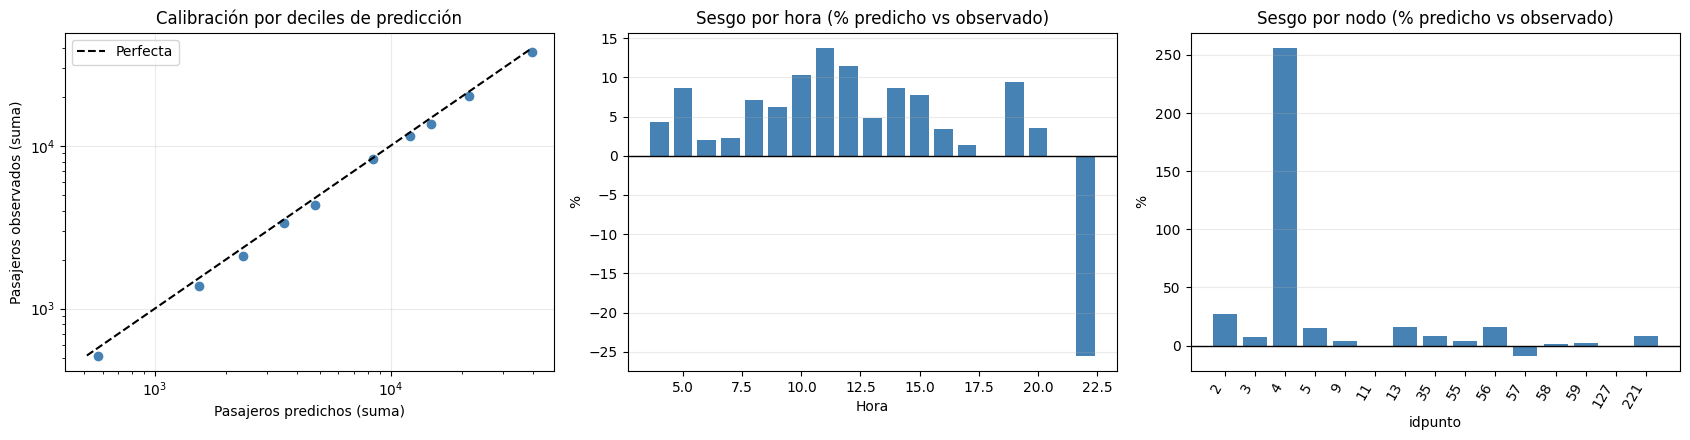

Sesgo global: +5.92%


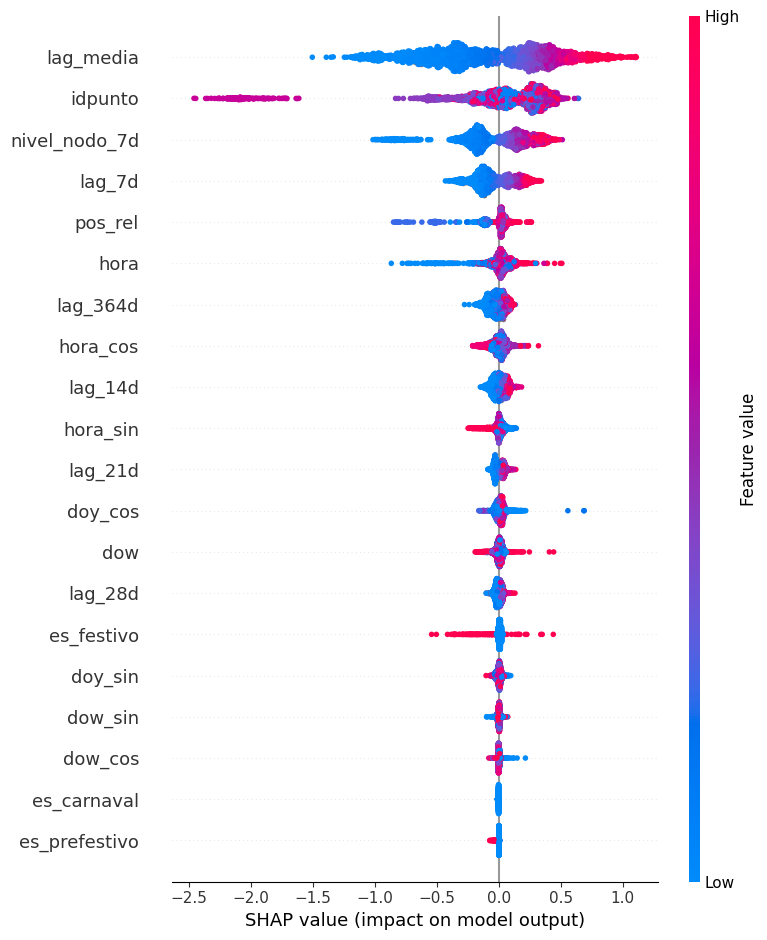

Importancia media |SHAP|:
lag_media       0.42
idpunto         0.30
nivel_nodo_7d   0.21
lag_7d          0.13
pos_rel         0.07
hora            0.07
lag_364d        0.05
hora_cos        0.04
lag_14d         0.04
hora_sin        0.03
lag_21d         0.03
doy_cos         0.03
dow             0.02
lag_28d         0.02
es_festivo      0.02
doy_sin         0.01
dow_sin         0.01
dow_cos         0.01
es_carnaval     0.00
es_prefestivo   0.00


In [65]:
comp['pred_conteo'] = comp['pred'] * comp['viajes']
comp['decil'] = pd.qcut(comp['pred'], 10, duplicates='drop')

def sesgo(t):
    t = t[t['real'] > 0]
    return 100 * (t['pred'] / t['real'] - 1)

cal = comp.groupby('decil', observed=True).agg(pred=('pred_conteo', 'sum'), real=('subidas', 'sum'))
por_hora = comp.groupby('hora').agg(pred=('pred_conteo', 'sum'), real=('subidas', 'sum'))
por_nodo = comp.groupby('idpunto').agg(pred=('pred_conteo', 'sum'), real=('subidas', 'sum'))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

ax = axes[0]
ax.scatter(cal['pred'], cal['real'], color='steelblue')
lim = [cal[['pred', 'real']].min().min(), cal[['pred', 'real']].max().max()]
ax.plot(lim, lim, 'k--', label='Perfecta')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_title('Calibración por deciles de predicción')
ax.set_xlabel('Pasajeros predichos (suma)'); ax.set_ylabel('Pasajeros observados (suma)')
ax.legend(); ax.grid(alpha=0.25)

ax = axes[1]
s = sesgo(por_hora)
ax.bar(s.index, s.values, color='steelblue')
ax.axhline(0, color='k', lw=1)
ax.set_title('Sesgo por hora (% predicho vs observado)')
ax.set_xlabel('Hora'); ax.set_ylabel('%'); ax.grid(alpha=0.25, axis='y')

ax = axes[2]
s = sesgo(por_nodo)
ax.bar(s.index.astype(str), s.values, color='steelblue')
ax.axhline(0, color='k', lw=1)
ax.set_title('Sesgo por nodo (% predicho vs observado)')
ax.set_xlabel('idpunto'); ax.set_ylabel('%')
plt.setp(ax.get_xticklabels(), rotation=60, ha='right')
ax.grid(alpha=0.25, axis='y')

plt.tight_layout()
plt.show()
print('Sesgo global: %+.2f%%' % (100 * (comp['pred_conteo'].sum() / comp['subidas'].sum() - 1)))

# ---- SHAP (TreeSHAP nativo de LightGBM; escala log-tasa) --------------
m_exp = entrenar(TRAIN, FEATURES, PARAMS, N_ROUNDS)
muestra = comp.sample(min(3000, len(comp)), random_state=SEED)
Xs = matriz(muestra, FEATURES)
contrib = m_exp.predict(Xs, pred_contrib=True)      # última columna = valor base

Xs_num = Xs.copy()
Xs_num['idpunto'] = Xs_num['idpunto'].cat.codes     # shap necesita numéricos para colorear
shap.summary_plot(contrib[:, :-1], Xs_num, max_display=len(FEATURES))

imp = (pd.Series(np.abs(contrib[:, :-1]).mean(axis=0), index=FEATURES)
         .sort_values(ascending=False).round(4))
print('Importancia media |SHAP|:')
print(imp.to_string())

### 3.2.7 Modelo final y guardado

El modelo de producción se entrena con todo el panel (ene-2023 hasta el ultimo dia disponible) y los hiperparámetros elegidos. Se guarda junto con un JSON de metadatos (features, categorías, hiperparámetros y métricas) para la API de la Fase 3. `predict()` devuelve pasajeros por viaje en cada nodo. Para pasar a pasajeros por franja se multiplica por los viajes **históricos** de esa franja, nunca por los propuestos (ver 3.3). Este modelo sirve para repartir carga entre paradas; la demanda total de ruta para el optimizador está en 3.3.

In [66]:
DIR_MOD = os.path.join(DATA, 'modelos')
os.makedirs(DIR_MOD, exist_ok=True)

modelo_final = entrenar(dfm, FEATURES, PARAMS, N_ROUNDS)
ruta_modelo = os.path.join(DIR_MOD, 'lgbm_kra54.txt')
modelo_final.save_model(ruta_modelo)

meta = {
    'ruta': 'KRA 54 (idruta 16)',
    'entrenado_con': '%s .. %s' % (dfm['dia'].min().date(), dfm['dia'].max().date()),
    'objetivo_modelo': PARAMS['objective'],
    'salida': 'pasajeros POR VIAJE en el nodo (exp(raw)); pasajeros/hora = salida * viajes HISTORICOS de esa hora',
    'horizonte_dias': H,
    'rezagos_dias': LAGS,
    'features': FEATURES,
    'categorias_idpunto': [int(c) for c in CATEGORIAS_NODO.categories],
    'hiperparametros': PARAMS,
    'n_arboles': N_ROUNDS,
    'fecha_inicio_test': str(FECHA_TEST_INI.date()),
    'rezago_anual_dias': LAG_ANUAL,
    'metricas_walk_forward_test': tabla_lgb.to_dict('records'),}

with open(os.path.join(DIR_MOD, 'lgbm_kra54_meta.json'), 'w', encoding='utf-8') as f:
    json.dump(meta, f, indent=2, ensure_ascii=False, default=str)

# Verificación: el modelo recargado debe dar las mismas predicciones
m_rec = lgb.Booster(model_file=ruta_modelo)
chk = dfm.sample(1000, random_state=SEED)
assert np.allclose(m_rec.predict(matriz(chk, FEATURES)),
                   modelo_final.predict(matriz(chk, FEATURES)))
print('Modelo guardado en', ruta_modelo)
print('OK: el modelo recargado reproduce las predicciones')

Modelo guardado en /content/drive/MyDrive/proyecto_sobusa/data/modelos/lgbm_kra54.txt
OK: el modelo recargado reproduce las predicciones


### 3.2.8 Horizonte en el modelo de nodos: ¿cuánto se gana con pronóstico diario (H = 1) frente a semanal (H = 7)?

`H = 7` **no** significa que el modelo prediga "por semana". Predice cada celda nodo-hora-día, pero solo se le permite usar información de hace 7 días o más. Con `H = 1` (pronóstico el día anterior) entran los rezagos de 1, 2 y 3 días, que son justo donde la ACF del nivel desestacionalizado era más alta (lag 1 ≈ 0,43 frente a lag 7 ≈ 0,29).

Aquí se repite el mismo walk-forward con H = 7, 3 y 1, con los mismos hiperparámetros y las mismas filas de test. Se reentrena una vez por semana en los tres casos, y lo único que cambia es qué tan reciente es la información de las features. Además de la devianza se reporta el error **agregado por hora de ruta** (suma de nodos), que es lo que consume el optimizador, y el sesgo.


In [67]:
# --- 3.2.8  Horizonte H = 7 / 3 / 1 -----------------------------------
HORIZONTES = [7, 3, 1]

def wmape_hora_ruta(p, col='pred'):
    """Error ponderado de la demanda por (dia, hora) sumando nodos: lo que ve el optimizador."""
    g = (p.assign(_pc=p[col] * p['viajes'])
          .groupby(['dia', 'hora']).agg(real=('subidas', 'sum'), pred=('_pc', 'sum')))
    return 100 * (g['pred'] - g['real']).abs().sum() / g['real'].sum()

def sesgo_pct(p, col='pred'):
    return 100 * ((p[col] * p['viajes']).sum() / p['subidas'].sum() - 1)

filas, preds_h = [], {}
for h in HORIZONTES:
    dfm_h = construir_features(df, lags=lags_para(h), h=h)
    _, _, feats_h = conjuntos_features(h)
    p = walk_forward(FOLDS_TEST, feats_h, PARAMS, N_ROUNDS, datos=dfm_h)
    p = p.merge(base_wf, on=['idpunto', 'hora', 'dia'], how='inner')
    assert len(p) == len(base_wf), 'las filas de test no coinciden'
    preds_h[h] = p
    filas.append(dict(modelo='LightGBM H=%d' % h, n_features=len(feats_h), **evaluar(p),
                      wMAPE_hora_ruta=wmape_hora_ruta(p), sesgo_pct=sesgo_pct(p)))

ref = preds_h[HORIZONTES[0]]
for nombre, col in [('B1 media historica', 'b1'), ('N7 valor de hace 7 dias', 'naive7')]:
    filas.append(dict(modelo=nombre, n_features=0, **evaluar(ref, col),
                      wMAPE_hora_ruta=wmape_hora_ruta(ref, col), sesgo_pct=sesgo_pct(ref, col)))

tabla_h = pd.DataFrame(filas).round(4).sort_values('PoissonDev').reset_index(drop=True)
display(tabla_h)

dev = tabla_h.set_index('modelo')['PoissonDev']
print('Mejora de devianza H=1 vs H=7: %.2f%%' % (100 * (1 - dev['LightGBM H=1'] / dev['LightGBM H=7'])))
print('Mejora de devianza H=3 vs H=7: %.2f%%' % (100 * (1 - dev['LightGBM H=3'] / dev['LightGBM H=7'])))


,modelo,n_features,MAE,RMSE,PoissonDev,MAE_conteo,wMAPE_hora_ruta,sesgo_pct
0,LightGBM H=1,23,0.23,0.46,0.20,3.03,19.83,3.29
1,LightGBM H=3,21,0.23,0.46,0.20,3.07,20.25,4.11
2,LightGBM H=7,20,0.23,0.47,0.20,3.12,20.91,5.92
3,B1 media historica,0,0.28,0.51,0.24,3.80,30.35,22.44
4,N7 valor de hace 7 dias,0,0.30,0.60,0.79,4.10,28.65,4.84


Mejora de devianza H=1 vs H=7: 1.81%
Mejora de devianza H=3 vs H=7: 0.78%


## 3.3 Demanda total de la ruta: el insumo del optimizador

El modelo de nodos (3.2) predice pasajeros **por viaje** en 15 paradas, que juntas ven ≈11,7 % de los pasajeros de la ruta. El optimizador de la Fase 2 necesita otra cosa: **pasajeros por hora de toda la ruta**. Hasta ahora los tomaba de un promedio histórico de día laborable (`demanda_ruta_2025.csv`), sin pasar por ningún modelo. Esta sección construye el modelo que faltaba y deja los pronósticos listos para que el optimizador los lea.

Decisiones de diseño:

- **Objetivo:** subidas de toda la ruta por (día, hora del evento), sin filtro de `idpunto`. Salen de `scripts/extraer_demanda_ruta_horaria.py`.
- **Sin offset de viajes.** La demanda de una hora no crece porque se pongan más buses. Por eso no se modela por viaje ni se usa `viajes` como feature: el pronóstico es la demanda bajo el servicio histórico, y el optimizador decide cuántos ciclos darle (carga por viaje = demanda / f).
- **Un horizonte, H7:** pronóstico con una semana de antelación, para planificar turnos y flota. También se evaluó H1 (con un día de antelación) y se descartó: casi no mejora el pronóstico y no mejora las decisiones (3.3.8 y 3.4).
- **Deriva entre años:** 2023 tuvo ≈15 % más demanda que 2025. Se comparan cuatro formas de tratarla (nada, pesos por recencia, nivel de los últimos 28 días como offset, o ambos) y se elige con validación, no con el test.
- **Calendario de estacionalidades** (`estacionalidades_anio`), además de festivos, Carnaval y ciclo anual.
- **Honestidad de la evaluación:** se compara contra líneas base fuertes (el valor de la semana pasada, el promedio de los 4 mismos días, la media histórica por hora y tipo de día). Un modelo que no las supere no justifica entrar al optimizador.


### 3.3.1 La serie de demanda de toda la ruta: de dónde sale y qué datos usamos

El modelo necesita la demanda de **toda la ruta** por (día, hora). La fuente se elige con `FUENTE_RUTA`, y aquí se deja en **`'panel'`**: la serie se reconstruye con archivos que **ya están descargados**, sin consultar la base ni forzar una descarga nueva. La alternativa `'conteo'` (medición real desde `conteo_pasajeros_destino`) sigue disponible, pero no se usa porque es pesada.

**Datos que usa esta celda**

| Archivo u objeto | Qué contiene | Para qué se usa |
|---|---|---|
| `df` (sección 2.4), construido con `panel_horario/panel_*.csv` y `servicio_*.csv` | Subidas por día, hora y nodo en los 15 nodos de KRA 54, de ene-2023 a ago-2025. Solo quedan las horas en que hubo servicio y ya se limpiaron las fallas de contador | Se suman las subidas de los 15 nodos por (día, hora) |
| `demanda_ruta_2025.csv` | Demanda **medida** de la ruta completa: pasajeros por hora y día de la semana, promedio de ene-ago 2025 | Calibrar la cuota: qué fracción de la ruta ven los 15 nodos en cada hora y día de la semana |
| `pico_carga_por_hora_resumen.json` | La medición de 25.905 pasajeros por día laborable en ene-feb 2023 | Solo para comprobar si la cuota de 2023 es la de 2025 |

**Qué no se usa:** ninguna consulta a la base de datos, y tampoco los viajes de `servicio` como variable (la demanda de una hora no se divide por viajes).

**Cómo se calcula:** `demanda de la ruta (día, hora) = suma de los 15 nodos / cuota (hora, día de la semana)`. Los 15 nodos ven en promedio ≈9-12 % de los pasajeros de la ruta; la cuota exacta de cada hora y día de la semana se mide en ene-ago 2025, donde ya se conoce la ruta completa.

**Qué significa para el resto del modelo:** todo lo que sigue (3.3.2 a 3.4) trabaja sobre esta serie, que es una **estimación**, no una medición. Los eventos de las paradas son una muestra de los de la ruta, y escalar por 1/cuota amplifica su ruido de muestreo (la celda imprime cuánto: 6-9 % por hora en el día, mucho más de noche). Además supone que la cuota de 2023-24 es la de 2025, y la celda lo contrasta con la medición de 2023.

En ambos casos: los días sin ningún dato no se inventan, las horas sin eventos de un día con datos cuentan como cero y los valores absurdos (más de 3 veces el p99 de su hora y tipo de día) pasan a NaN. Si hay meses reales descargados, la celda mide el error de la reconstrucción contra ellos.


In [68]:
# --- 3.3.1  Demanda total de ruta por (dia, hora) -----------------------------
import glob, sys

HORAS_RUTA = list(range(4, 23))                 # ventana del optimizador: 04h a 22h
DIR_RUTA = os.path.join(DATA, 'demanda_ruta_horaria')

# De donde sale la demanda de TODA la ruta por (dia, hora):
#   'panel'  : se reconstruye con el panel de 15 nodos que ya esta descargado (df), calibrado contra la
#              ruta completa que ya se midio (demanda_ruta_2025.csv y la medicion de 2023). No consulta la base.
#   'conteo' : se descarga de la base (conteo_pasajeros_destino) con scripts/extraer_demanda_ruta_horaria.py.
#              Es la medicion real, pero pesada: lee casi todos los eventos de la ruta.
FUENTE_RUTA = 'panel'
EXTRAER_DESDE_NOTEBOOK = False                  # solo se usa con FUENTE_RUTA = 'conteo'

def _ns(s):
    """Fechas siempre en datetime64[ns]: evita incompatibilidades de resolucion al unir tablas."""
    return pd.to_datetime(s).astype('datetime64[ns]')

def tipo_dia_de(dias):
    """'lab' (lun-vie no festivo), 'sab', 'dom_fest' (domingo o festivo de Colombia)."""
    dias = pd.Series(pd.to_datetime(dias)).reset_index(drop=True)
    fest = pd.to_datetime(list(holidays.country_holidays('CO', years=sorted(dias.dt.year.unique())).keys()))
    dow = dias.dt.dayofweek
    return np.where(dias.isin(fest) | (dow == 6), 'dom_fest', np.where(dow == 5, 'sab', 'lab'))

def _malla(dias, columnas):
    """Malla completa dias x 19 horas con las columnas dadas (hora sin datos = NaN, se rellena aparte)."""
    return (pd.MultiIndex.from_product([pd.DatetimeIndex(sorted(dias)), HORAS_RUTA], names=['dia', 'hora'])
              .to_frame(index=False).merge(columnas, on=['dia', 'hora'], how='left'))

f_hist = os.path.join(DATA, 'demanda_ruta_2025.csv')
f_res = os.path.join(DATA, 'pico_carga_por_hora_resumen.json')

if FUENTE_RUTA == 'conteo':
    # ---------------------------------------------------------------- medicion real desde la base
    if EXTRAER_DESDE_NOTEBOOK:
        import importlib
        sys.path.insert(0, os.path.join(PROY, 'scripts'))
        import extraer_demanda_ruta_horaria as ext_ruta
        ext_ruta = importlib.reload(ext_ruta)          # Python guarda el modulo en memoria: sin esto se sigue usando la version vieja
        ext_ruta.extraer(CONN, '2023-01', df['dia'].max().strftime('%Y-%m'), salida=DIR_RUTA)

    archivos = sorted(glob.glob(os.path.join(DIR_RUTA, 'demanda_ruta_horaria_*.csv')))
    if not archivos:
        raise FileNotFoundError(
            'No hay CSV en %s.\nGenerarlos con:\n'
            '  python scripts/extraer_demanda_ruta_horaria.py --desde 2023-01 --hasta AAAA-MM\n'
            'o poner EXTRAER_DESDE_NOTEBOOK = True, o usar FUENTE_RUTA = \'panel\'.' % DIR_RUTA)
    crudo = (pd.concat([pd.read_csv(f) for f in archivos], ignore_index=True)
               .drop_duplicates(['dia', 'hora'], keep='last'))
    crudo['dia'] = _ns(crudo['dia'])
    fuera = crudo.loc[~crudo['hora'].isin(HORAS_RUTA), 'subidas'].sum() / max(crudo['subidas'].sum(), 1)
    crudo = crudo[crudo['hora'].isin(HORAS_RUTA)]
    print('Fuente: conteo (medicion real). Archivos: %d | filas dia-hora: %d | %s .. %s'
          % (len(archivos), len(crudo), crudo['dia'].min().date(), crudo['dia'].max().date()))
    print('Subidas fuera de la ventana 04h-22h (se descartan): %.2f %%' % (100 * fuera))
    if 'eventos_descartados' in crudo.columns:
        print('Eventos descartados por falla del contador: %d de %d (%.4f %%)'
              % (crudo['eventos_descartados'].sum(), crudo['eventos'].sum(),
                 100 * crudo['eventos_descartados'].sum() / max(crudo['eventos'].sum(), 1)))
    # Una hora sin eventos en un dia con datos es un cero real; un dia SIN ningun dato no se inventa.
    base_ruta = _malla(crudo['dia'].unique(), crudo[['dia', 'hora', 'subidas']])
    base_ruta['dem'] = base_ruta['subidas'].fillna(0.0)
    base_ruta = base_ruta.drop(columns='subidas')

elif FUENTE_RUTA == 'panel':
    # ---------------------------------------------------------------- reconstruccion desde el panel de nodos
    # El panel (df) solo ve los eventos con idpunto: 15 paradas, ~11.7 % de los pasajeros. Si esos eventos
    # fueran una muestra proporcional de los de toda la ruta, cuota(hora, dia de la semana) = nodos / ruta, y
    #     demanda_ruta(dia, hora) = suma_de_nodos(dia, hora) / cuota(hora, dia de la semana).
    # La cuota se mide donde YA se conoce la ruta completa: demanda_ruta_2025.csv (ene-ago 2025).
    if not os.path.exists(f_hist):
        raise FileNotFoundError('Falta %s (demanda medida de la ruta, por hora y dia de la semana).' % f_hist)
    nodos_h = (df[df['hora'].isin(HORAS_RUTA)].groupby(['dia', 'hora'], as_index=False)['subidas'].sum()
                 .rename(columns={'subidas': 'nodos'}))
    nodos_h['dia'] = _ns(nodos_h['dia'])
    base_ruta = _malla(nodos_h['dia'].unique(), nodos_h)
    base_ruta['nodos'] = base_ruta['nodos'].fillna(0.0)          # hora sin eventos en los 15 nodos = 0
    base_ruta['dow_pg'] = (base_ruta['dia'].dt.dayofweek + 1) % 7   # convencion de la base: 0 = domingo ... 6 = sabado
    print('Fuente: PANEL de 15 nodos calibrado (estimacion, no medicion). Dias: %d | %s .. %s'
          % (base_ruta['dia'].nunique(), base_ruta['dia'].min().date(), base_ruta['dia'].max().date()))

    # --- cuota por (hora, dia de la semana), medida en la ventana de la ruta completa (ene-ago 2025)
    h_ = pd.read_csv(f_hist)
    h_['dow'] = h_['dow'] % 7                  # 0 = domingo (convencion de la base); un 7 ISO pasa a 0
    ruta_m = (h_['subidas'] / h_['dias'].replace(0, np.nan)).groupby([h_['hora'], h_['dow']]).mean()
    en_vent = (base_ruta['dia'] >= '2025-01-01') & (base_ruta['dia'] < '2025-09-01')
    if not en_vent.any():
        raise ValueError('El panel no tiene dias entre 2025-01-01 y 2025-08-31: no hay donde calibrar la cuota.')
    nod_m = base_ruta[en_vent].groupby(['hora', 'dow_pg'])['nodos'].mean()
    nod_m.index.names = ['hora', 'dow']
    cuota = (nod_m / ruta_m).reindex(pd.MultiIndex.from_product([HORAS_RUTA, range(7)], names=['hora', 'dow']))
    cuota = cuota.where((cuota > 0.02) & (cuota < 0.5))              # celdas sin datos o absurdas
    cuota = cuota.fillna(cuota.groupby(level='hora').transform('median')).fillna(cuota.median())
    base_ruta = base_ruta.merge(cuota.rename('cuota').reset_index().rename(columns={'dow': 'dow_pg'}),
                                on=['hora', 'dow_pg'], how='left')
    base_ruta['dem'] = base_ruta['nodos'] / base_ruta['cuota']

    # --- que tan estable es la cuota (lo que decide si la reconstruccion sirve)
    lab = [1, 2, 3, 4, 5]
    nl = nod_m[nod_m.index.get_level_values('dow').isin(lab)].groupby(level='hora').mean()
    rl = ruta_m[ruta_m.index.get_level_values('dow').isin(lab)].groupby(level='hora').mean()
    c_lab = (nl / rl).reindex(HORAS_RUTA)
    print('\nCuota del panel de nodos sobre la ruta completa, dia laborable (ene-ago 2025):')
    print('  total del dia: %.1f %%   | por hora, de %.1f %% a %.1f %% (horas 5-20)'
          % (100 * nl.sum() / rl.sum(), 100 * c_lab.loc[5:20].min(), 100 * c_lab.loc[5:20].max()))
    print('  hora:  ' + ' '.join('%5d' % h for h in (5, 6, 8, 10, 12, 14, 17, 19, 21)))
    print('  cuota: ' + ' '.join('%4.1f%%' % (100 * c_lab[h]) for h in (5, 6, 8, 10, 12, 14, 17, 19, 21)))

    # --- ruido esperado: los eventos de las paradas son una MUESTRA de los de la ruta; escalar por 1/cuota
    # amplifica el ruido de muestreo: sd relativa = sqrt((1 - p) / (p * T)) (supone muestreo proporcional)
    ruido = 100 * np.sqrt((1 - c_lab) / (c_lab * rl.reindex(HORAS_RUTA)))
    print('\nRuido de muestreo esperado de la reconstruccion por hora (% de la demanda, supuesto binomial):')
    print('  ' + ' '.join('%dh: %.0f%%' % (h, ruido[h]) for h in (6, 8, 12, 17, 21)))
    print('  (en el total del dia el ruido baja a ~%.0f %%)' % (100 * np.sqrt((1 - nl.sum() / rl.sum()) / (nl.sum() / rl.sum() * rl.sum()))))

    # --- ¿la cuota de 2023 es la de 2025? segundo punto medido de la ruta completa: ene-feb 2023
    if os.path.exists(f_res):
        ruta23 = json.load(open(f_res, encoding='utf-8')).get('subidas_dia_conteo_2023')
        e23 = (base_ruta['dia'] >= '2023-01-01') & (base_ruta['dia'] < '2023-03-01') & base_ruta['dow_pg'].isin(lab)
        if ruta23 and e23.any():
            c23 = base_ruta[e23].groupby('dia')['nodos'].sum().mean() / ruta23
            c25 = nl.sum() / rl.sum()
            print('\nCuota del dia laborable: ene-feb 2023 = %.1f %% | ene-ago 2025 = %.1f %% | cociente 2023/2025 = %.2f'
                  % (100 * c23, 100 * c25, c23 / c25))
            if abs(c23 / c25 - 1) > 0.10:
                print('REVISAR: la cuota cambio mas de 10 %% entre 2023 y 2025. Reconstruir 2023-24 con la cuota de 2025 sesgaria'
                      ' esa demanda en %+.0f %% (negativo = la subestima).' % (100 * (c23 / c25 - 1)))
            else:
                print('OK: la cuota es estable entre 2023 y 2025 (dentro de 10 %).')

    # --- si ya hay meses reales descargados, se mide el error de la reconstruccion contra ellos
    arch_real = sorted(glob.glob(os.path.join(DIR_RUTA, 'demanda_ruta_horaria_*.csv')))
    if arch_real:
        real = pd.concat([pd.read_csv(f) for f in arch_real]).drop_duplicates(['dia', 'hora'], keep='last')
        real['dia'] = _ns(real['dia'])
        m = base_ruta.merge(real[['dia', 'hora', 'subidas']], on=['dia', 'hora'])
        if len(m):
            e = (m['dem'] - m['subidas']).abs()
            d = m.groupby('dia').agg(r=('subidas', 'sum'), e=('dem', 'sum'))
            print('\nERROR DE LA RECONSTRUCCION contra la medicion real (%d dias descargados):' % d.shape[0])
            print('  por hora: wMAPE %.1f %% | sesgo %+.1f %% | por dia: MAPE %.1f %%'
                  % (100 * e.sum() / m['subidas'].sum(), 100 * (m['dem'].sum() / m['subidas'].sum() - 1),
                     100 * ((d['e'] - d['r']).abs() / d['r']).mean()))
    base_ruta = base_ruta.drop(columns=['nodos', 'dow_pg', 'cuota'])
else:
    raise ValueError("FUENTE_RUTA debe ser 'panel' o 'conteo'")

dias_con_datos = pd.DatetimeIndex(sorted(base_ruta['dia'].unique()))
calendario = pd.date_range(dias_con_datos.min(), dias_con_datos.max())
faltan = calendario.difference(dias_con_datos)
print('\nDias del calendario sin ningun dato: %d %s' % (len(faltan),
      [str(d.date()) for d in faltan[:8]] + (['...'] if len(faltan) > 8 else [])))

base_ruta['tipo_dia'] = tipo_dia_de(base_ruta['dia'])

# --- limpieza: un valor mayor que 3 veces el p99 de su (hora, tipo de dia) es una falla del
# contador. Se pone en NaN (no en cero) para que no contamine rezagos ni entrenamiento.
# Se usa p99 y no p99.9: con unos cientos de filas por grupo, el p99.9 es la propia falla y
# nunca la detecta (probado con fallas inyectadas).
q99 = base_ruta.groupby(['hora', 'tipo_dia'])['dem'].transform(lambda s: s.quantile(0.99))
atipico = base_ruta['dem'] > np.maximum(3 * q99, 50)
base_ruta.loc[atipico, 'dem'] = np.nan
print('Celdas dia-hora atipicas puestas en NaN: %d de %d (%.3f %%)'
      % (atipico.sum(), len(base_ruta), 100 * atipico.mean()))

# --- diagnostico: dias con demanda muy baja frente a su propio dia de la semana
tot_dia = base_ruta.groupby('dia')['dem'].sum()
rel_dia = (tot_dia / tot_dia.groupby(tot_dia.index.dayofweek).transform('median')).sort_values()
print('\nLos 8 dias de menor demanda relativa a la mediana de su dia de la semana:')
print('(un festivo real baja mucho; una falla de conteo tambien: revisar los que no sean festivo)')
fest_chk = tipo_dia_de(pd.Series(rel_dia.head(8).index))
print(pd.DataFrame({'razon': rel_dia.head(8).round(2).values,
                    'tipo_dia': fest_chk}, index=[d.date() for d in rel_dia.head(8).index]).to_string())


if FUENTE_RUTA == 'conteo':
    # --- validacion contra el archivo que usa hoy el optimizador
    f_hist = os.path.join(DATA, 'demanda_ruta_2025.csv')
    if os.path.exists(f_hist):
        h_ = pd.read_csv(f_hist)
        h_ = h_[(h_['dow'] >= 1) & (h_['dow'] <= 5)].copy()
        h_['sub_dia'] = h_['subidas'] / h_['dias'].replace(0, np.nan)
        ref = h_.groupby('hora')['sub_dia'].mean()
        sel = (base_ruta['dia'] >= '2025-01-01') & (base_ruta['dia'] <= '2025-08-31') & (base_ruta['dia'].dt.dayofweek < 5)
        mio = base_ruta[sel].groupby('hora')['dem'].mean()
        comp = pd.DataFrame({'archivo_optimizador': ref, 'esta_serie': mio}).reindex(HORAS_RUTA)
        comp['cociente'] = comp['esta_serie'] / comp['archivo_optimizador']
        print('\nPromedio de dia laborable ene-ago 2025: esta serie vs demanda_ruta_2025.csv')
        print(comp.round(2).to_string())
        c_tot = comp['esta_serie'].sum() / comp['archivo_optimizador'].sum()
        print('\nCociente total: %.3f' % c_tot)
        # el total puede cuadrar y haber horas rotas (una falla de contador en una hora): se mira hora por hora
        malas = comp[((comp['cociente'] < 0.85) | (comp['cociente'] > 1.15)) & ~comp.index.isin([21, 22])]
        if len(malas):
            print('REVISAR horas con cociente fuera de 0.85-1.15 (21h y 22h se excluyen: ahi pesa que las horas sin eventos '
                  'cuenten como cero): %s' % list(malas.index))
        if abs(c_tot - 1) > 0.05:
            print('REVISAR: difieren mas de 5 %. Causas probables: el filtro de viajes cancelados, la definicion de'
                  ' `subidas` del CSV, o que el CSV promedie solo los dias con eventos en cada hora'
                  ' (aqui las horas sin eventos cuentan como cero; afecta sobre todo a 21h-22h).')
        elif not len(malas):
            print('OK: la serie reproduce el archivo que ya usa el optimizador (total dentro de 5 % y cada hora dentro de 15 %).')
    else:
        print('\n(no se encontro %s: se omite la validacion cruzada)' % f_hist)


base_ruta.head()


Fuente: PANEL de 15 nodos calibrado (estimacion, no medicion). Dias: 966 | 2023-01-01 .. 2025-08-30

Cuota del panel de nodos sobre la ruta completa, dia laborable (ene-ago 2025):
  total del dia: 9.4 %   | por hora, de 5.3 % a 12.8 % (horas 5-20)
  hora:      5     6     8    10    12    14    17    19    21
  cuota: 12.8% 11.7% 12.1% 10.0%  9.7%  9.6%  8.5%  5.8%  0.1%

Ruido de muestreo esperado de la reconstruccion por hora (% de la demanda, supuesto binomial):
  6h: 6% 8h: 7% 12h: 9% 17h: 8% 21h: 130%
  (en el total del dia el ruido baja a ~2 %)

Cuota del dia laborable: ene-feb 2023 = 10.8 % | ene-ago 2025 = 9.4 % | cociente 2023/2025 = 1.15
REVISAR: la cuota cambio mas de 10 % entre 2023 y 2025. Reconstruir 2023-24 con la cuota de 2025 sesgaria esa demanda en +15 % (negativo = la subestima).

Dias del calendario sin ningun dato: 7 ['2025-01-31', '2025-02-28', '2025-03-31', '2025-04-30', '2025-05-31', '2025-06-30', '2025-07-31']
Celdas dia-hora atipicas puestas en NaN: 1 de 18354

,dia,hora,dem,tipo_dia
0,2023-01-01,4,0.00,dom_fest
1,2023-01-01,5,151.23,dom_fest
2,2023-01-01,6,286.54,dom_fest
3,2023-01-01,7,190.08,dom_fest
4,2023-01-01,8,290.14,dom_fest


### 3.3.2 Calendario de estacionalidades: por qué aporta

La tabla `estacionalidades_anio` (231 filas) dice, año por año, en qué días rige cada tipo de estacionalidad: `FESTIVO_NACIONAL`, `FIESTA_ATLANTICO`, `TEMPORADA_NACIONAL` y `FIESTAS_PATRONALES`. Los días que no caen en ninguno son `DIAS_CORRIENTES`. El EDA ya mostró que estos regímenes mueven la demanda en órdenes de magnitud.

Lo que aporta frente a lo que el modelo ya tenía:

1. **Regímenes de varios días, no solo festivos sueltos.** `es_festivo` marca un día. Una temporada (vacaciones de mitad de año, Navidad, Semana Santa) cambia el **nivel y la forma** del día durante semanas: baja la punta de la mañana y sube la de la tarde, por ejemplo.
2. **Anticipa los cambios de régimen.** Los rezagos de 7 a 28 días solo "se enteran" del cambio cuando ya pasaron H días dentro del nuevo régimen, justo cuando el modelo más se equivoca. El calendario lo sabe de antemano.
3. **Incluye fiestas que `holidays` no conoce:** `FIESTA_ATLANTICO` (Carnaval y otras de la región) y `FIESTAS_PATRONALES`.
4. **Posición dentro de la temporada.** `estac_dia_k` y `estac_faltan_k` cuentan cuántos días lleva y cuántos le faltan a la temporada larga que cubre el día. La primera y la última semana de unas vacaciones no se comportan como la del medio.

Condición para que no haya fuga: el calendario debe ser **planeado** (se publica antes de que ocurran los días). Si alguien lo etiquetó después, mirando la demanda, el modelo estaría usando el resultado como pista. La celda de abajo contrasta `FESTIVO_NACIONAL` con la librería `holidays` como prueba de cordura, pero no puede detectar eso: hay que confirmarlo con quien mantiene la tabla.

Fuera del rango que cubre la tabla las features quedan en NaN, y `pronosticar_ruta` avisa.


In [69]:
# --- 3.3.2  Calendario de estacionalidades (tabla estacionalidades_anio) ------------
USAR_ESTAC = True            # False: omite estas features (por si la tabla no se puede interpretar)
TIPOS_ESTAC = ['FESTIVO_NACIONAL', 'FIESTA_ATLANTICO', 'TEMPORADA_NACIONAL', 'FIESTAS_PATRONALES']
# DIAS_CORRIENTES no es una bandera: son los dias que no caen en ninguno de los cuatro.

def _leer_tablas_estac():
    """Devuelve (estacionalidades_anio, estacionalidades). La primera vez las baja de la base
    (231 y 24 filas) y las guarda en data/ para no volver a consultar."""
    p_ea = os.path.join(DATA, 'estacionalidades_anio.csv')
    p_es = os.path.join(DATA, 'estacionalidades.csv')
    if os.path.exists(p_ea) and os.path.exists(p_es):
        return pd.read_csv(p_ea), pd.read_csv(p_es)
    ea = consulta('SELECT * FROM estacionalidades_anio')
    es = consulta('SELECT * FROM estacionalidades')
    ea.to_csv(p_ea, index=False)
    es.to_csv(p_es, index=False)
    return ea, es

def _col(tabla, fragmentos):
    for frag in fragmentos:
        for c in tabla.columns:
            if frag in c.lower():
                return c
    return None

def construir_calendario_estac(ea, es):
    """Una fila por dia con banderas por tipo, cantidad de tipos activos y posicion dentro de la
    temporada larga que cubre el dia. Las columnas se DETECTAN (el notebook solo documentaba que la
    tabla tiene 6 columnas); si no se reconocen, falla con un mensaje que las muestra."""
    col_nombre = next((c for c in es.columns
                       if es[c].astype(str).isin(TIPOS_ESTAC + ['DIAS_CORRIENTES']).any()), None)
    col_id_es = 'id_estacionalidad' if 'id_estacionalidad' in es.columns else _col(es, ['id'])
    col_ini, col_fin = _col(ea, ['inicio', 'desde']), _col(ea, ['fin', 'hasta'])
    col_dia = _col(ea, ['fecha']) if not (col_ini and col_fin) else None
    if (col_nombre is None or col_id_es is None or 'id_estacionalidad' not in ea.columns
            or not ((col_ini and col_fin) or col_dia)):
        raise ValueError(
            'No pude interpretar las tablas de estacionalidad.\n'
            'estacionalidades_anio columnas: %s\n%s\n\nestacionalidades columnas: %s\n%s\n'
            'Se espera: en _anio un id_estacionalidad y fechas (inicio/fin o una fecha); en la otra el nombre del tipo.\n'
            'Ajustar los nombres arriba o poner USAR_ESTAC = False.'
            % (list(ea.columns), ea.head(3).to_string(), list(es.columns), es.head(3).to_string()))

    tipos = es[[col_id_es, col_nombre]].rename(columns={col_id_es: 'id_estacionalidad', col_nombre: 'tipo'})
    r = ea.merge(tipos, on='id_estacionalidad', how='left')
    if col_ini and col_fin:
        r['_ini'], r['_fin'] = _ns(r[col_ini]), _ns(r[col_fin])
    else:
        r['_ini'] = r['_fin'] = _ns(r[col_dia])
    malas = r['_ini'].isna() | r['_fin'].isna() | (r['_fin'] < r['_ini'])
    if malas.any():
        print('AVISO: %d filas de estacionalidades_anio con fechas invalidas se ignoran' % malas.sum())
    r = r[~malas & r['tipo'].isin(TIPOS_ESTAC)]

    filas = [(d, x['tipo'], x['_ini'], x['_fin'])
             for x in r.to_dict('records') for d in pd.date_range(x['_ini'], x['_fin'])]
    d = pd.DataFrame(filas, columns=['dia', 'tipo', 'ini', 'fin'])
    d['dia'], d['ini'], d['fin'] = _ns(d['dia']), _ns(d['ini']), _ns(d['fin'])

    cobertura = pd.date_range(r['_ini'].min(), r['_fin'].max())
    flags = (d.assign(v=1).pivot_table(index='dia', columns='tipo', values='v', aggfunc='max', fill_value=0)
               .reindex(index=cobertura, columns=TIPOS_ESTAC, fill_value=0).fillna(0).astype(int))
    flags.columns = ['estac_' + c for c in flags.columns]
    flags['estac_n'] = flags.sum(axis=1)

    d['largo'] = (d['fin'] - d['ini']).dt.days + 1
    larga = d[d['largo'] >= 3].sort_values('largo', ascending=False).drop_duplicates('dia')
    pos = larga.assign(estac_dia_k=(larga['dia'] - larga['ini']).dt.days.clip(upper=60),
                       estac_faltan_k=(larga['fin'] - larga['dia']).dt.days.clip(upper=60)
                       ).set_index('dia')[['estac_dia_k', 'estac_faltan_k']]
    cal = flags.join(pos)                      # NaN fuera de una temporada larga (no hay posicion)
    cal.index = _ns(cal.index)
    cal.index.name = 'dia'
    return cal

ESTAC_COLS, ESTAC_CAL, ESTAC_FIN = [], None, None
if USAR_ESTAC:
    _ea, _es = _leer_tablas_estac()
    ESTAC_CAL = construir_calendario_estac(_ea, _es)
    ESTAC_COLS = list(ESTAC_CAL.columns)
    ESTAC_FIN = ESTAC_CAL.index.max()

    print('estacionalidades_anio: %d filas | tipos: %s' % (len(_ea), sorted(_es.astype(str).stack().loc[lambda s: s.isin(TIPOS_ESTAC + ['DIAS_CORRIENTES'])].unique())))
    print('Calendario por dia: %s .. %s (%d dias)' % (ESTAC_CAL.index.min().date(), ESTAC_FIN.date(), len(ESTAC_CAL)))
    en_panel = ESTAC_CAL.reindex(base_ruta['dia'].drop_duplicates())
    print('\nDias del panel (%d) con cada tipo activo:' % len(en_panel))
    print((en_panel[[c for c in ESTAC_COLS if c.startswith('estac_') and c not in ('estac_n', 'estac_dia_k', 'estac_faltan_k')]]
           .sum().astype(int)).to_string())
    print('Dias del panel sin ningun tipo (DIAS_CORRIENTES): %d | fuera de la cobertura de la tabla: %d'
          % ((en_panel['estac_n'] == 0).sum(), en_panel['estac_n'].isna().sum()))

    # prueba de cordura: FESTIVO_NACIONAL deberia coincidir con la libreria holidays
    anios_c = sorted(set(ESTAC_CAL.index.year))
    lib = set(pd.to_datetime(list(holidays.country_holidays('CO', years=anios_c).keys())))
    lib = {d for d in lib if ESTAC_CAL.index.min() <= d <= ESTAC_FIN}
    tab = set(ESTAC_CAL.index[ESTAC_CAL['estac_FESTIVO_NACIONAL'] == 1])
    prec = len(tab & lib) / max(len(tab), 1)
    reca = len(tab & lib) / max(len(lib), 1)
    print('\nFESTIVO_NACIONAL vs libreria holidays: %.0f %% de los dias de la tabla son festivos reales, '
          'y la tabla recoge el %.0f %% de los festivos' % (100 * prec, 100 * reca))
    if prec < 0.9:
        print('REVISAR: la tabla no parece un calendario de festivos nacionales; confirmar como se leen sus columnas.')
    print('RECUERDA: confirmar que el calendario se publica ANTES de los dias (si se etiqueto despues, hay fuga).')


estacionalidades_anio: 231 filas | tipos: ['DIAS_CORRIENTES', 'FESTIVO_NACIONAL', 'FIESTAS_PATRONALES', 'FIESTA_ATLANTICO', 'TEMPORADA_NACIONAL']
Calendario por dia: 2017-01-01 .. 2026-12-25 (3646 dias)

Dias del panel (966) con cada tipo activo:
estac_FESTIVO_NACIONAL      47
estac_FIESTA_ATLANTICO      32
estac_TEMPORADA_NACIONAL    24
estac_FIESTAS_PATRONALES     3
Dias del panel sin ningun tipo (DIAS_CORRIENTES): 867 | fuera de la cobertura de la tabla: 0

FESTIVO_NACIONAL vs libreria holidays: 100 % de los dias de la tabla son festivos reales, y la tabla recoge el 100 % de los festivos
RECUERDA: confirmar que el calendario se publica ANTES de los dias (si se etiqueto despues, hay fuga).


### 3.3.3 Features de la serie de ruta

Misma regla que en 3.1: con horizonte H, una feature solo vale si usa datos de hace H días o más.

- **Rezagos** de la misma hora a 7, 14, 21 y 28 días (y a 1, 2 y 3 días si H < 7), más el rezago anual de 364 días.
- **`nivel28`:** demanda diaria media de los 28 días que terminan H días antes. Usar 28 días corridos (cuatro semanas completas) hace que cada día de la semana pese lo mismo.
- **Rezagos relativos** `lagrel_k = demanda(t−k) / nivel28(t−k)`: cuánto se desvió esa hora de su propio nivel de entonces. No arrastran el nivel del año.
- **Calendario:** hora y día de la semana, festivos, Carnaval, ciclo anual y las banderas de estacionalidad de 3.3.2.

**Tratamiento de la deriva entre años (recomendación 5).** Hay dos mecanismos, que se prueban solos y combinados en 3.3.5:

- *Pesos por recencia:* cada fila pesa `0,5^(edad / vida media)`. Los datos de 2023 siguen enseñando la forma del día, pero mandan menos que los de ayer.
- *Nivel como offset (`modo='offset'`):* el modelo predice `demanda = nivel28 × forma`, es decir, la razón respecto al nivel reciente. Un nivel distinto en 2023 y 2025 ya no cambia lo que hay que aprender. Es el mismo mecanismo de offset que usaba el modelo de nodos, pero con una exposición que sí tiene sentido para esta serie.


In [70]:
# --- 3.3.3  Features de la serie de ruta --------------------------------------------
NIVEL_VENTANA = 28            # dias corridos: cuatro semanas completas
NIVEL_MIN_DIAS = 14           # minimo de dias validos dentro de la ventana
N_HORAS = len(HORAS_RUTA)

def construir_features_ruta(base, h, estac=None, lags=None):
    """base: columnas dia, hora, dem (NaN = atipico o dia futuro). Devuelve base + features de
    horizonte h. Cada rezago se une por FECHA, asi que un hueco en el panel queda en NaN."""
    lags = lags_para(h) if lags is None else list(lags)
    out = base[['dia', 'hora', 'dem']].copy()
    out['dia'] = _ns(out['dia'])
    out = out.sort_values(['dia', 'hora']).reset_index(drop=True)
    assert not out.duplicated(['dia', 'hora']).any(), 'claves duplicadas'

    # nivel de los ultimos 28 dias, disponible h dias antes (calendario completo, futuro incluido)
    g = out.groupby('dia')['dem']
    tot = g.sum(min_count=1).where(g.count() == g.size())          # NaN si falta alguna hora
    cal = pd.date_range(out['dia'].min(), out['dia'].max())
    nivel = tot.reindex(cal).shift(h).rolling(NIVEL_VENTANA, min_periods=NIVEL_MIN_DIAS).mean()
    out['nivel28'] = out['dia'].map(nivel)
    out['rel'] = out['dem'] / out['nivel28'].where(out['nivel28'] > 0)

    # rezagos exactos de la misma hora, en valor y relativos a su nivel de entonces
    src = out[['dia', 'hora', 'dem', 'rel']]
    for k in list(lags) + [LAG_ANUAL]:
        s = (src.assign(dia=src['dia'] + pd.Timedelta(days=k))
                .rename(columns={'dem': f'lag_{k}d', 'rel': f'lagrel_{k}d'}))
        out = out.merge(s, on=['dia', 'hora'], how='left')
    for pref in ('lag', 'lagrel'):
        cols = [f'{pref}_{k}d' for k in lags]
        out[f'{pref}_media'] = out[cols].mean(axis=1).where(out[cols].notna().sum(axis=1) >= 2)
    c4 = [f'lag_{k}d' for k in (7, 14, 21, 28)]                     # linea base M4: promedio de 4 mismos dias
    if all(c in out.columns for c in c4):
        out['m4'] = out[c4].mean(axis=1).where(out[c4].notna().sum(axis=1) >= 2)

    # calendario (se conoce de antemano)
    out['dow'] = out['dia'].dt.dayofweek
    out['hora_sin'] = np.sin(2 * np.pi * out['hora'] / 24)
    out['hora_cos'] = np.cos(2 * np.pi * out['hora'] / 24)
    out['dow_sin'] = np.sin(2 * np.pi * out['dow'] / 7)
    out['dow_cos'] = np.cos(2 * np.pi * out['dow'] / 7)
    anios = sorted(out['dia'].dt.year.unique())
    fest = pd.to_datetime(list(holidays.country_holidays('CO', years=anios).keys()))
    out['es_festivo'] = out['dia'].isin(fest).astype(int)
    out['es_prefestivo'] = (out['dia'] + pd.Timedelta(days=1)).isin(fest).astype(int)
    out['es_carnaval'] = out['dia'].isin(dias_carnaval(anios)).astype(int)
    doy = out['dia'].dt.dayofyear
    out['doy_sin'] = np.sin(2 * np.pi * doy / 365.25)
    out['doy_cos'] = np.cos(2 * np.pi * doy / 365.25)
    out['tipo_dia'] = np.where((out['es_festivo'] == 1) | (out['dow'] == 6), 'dom_fest',
                               np.where(out['dow'] == 5, 'sab', 'lab'))
    if estac is not None:
        out = out.merge(estac, left_on='dia', right_index=True, how='left')
    return out

def feats_ruta(h, modo='raw', usar_estac=True):
    """modo 'raw': rezagos en pasajeros. modo 'offset': rezagos relativos al nivel (el nivel entra por el offset)."""
    pref = 'lag' if modo == 'raw' else 'lagrel'
    lag = [f'{pref}_{k}d' for k in lags_para(h)] + [f'{pref}_{LAG_ANUAL}d', f'{pref}_media', 'nivel28']
    return ['hora', 'dow'] + CAL_FEATS + (ESTAC_COLS if usar_estac else []) + lag

_t = construir_features_ruta(base_ruta, 7, ESTAC_CAL if USAR_ESTAC else None)
print('Ejemplo H=7: %d filas x %d columnas | features modo raw: %d | modo offset: %d'
      % (len(_t), _t.shape[1], len(feats_ruta(7, 'raw', USAR_ESTAC)), len(feats_ruta(7, 'offset', USAR_ESTAC))))
print('\n%% de NaN por feature (H=7, modo raw):')
print((_t[feats_ruta(7, 'raw', USAR_ESTAC)].isna().mean() * 100).round(1).loc[lambda s: s > 0].to_string())


Ejemplo H=7: 18354 filas x 36 columnas | features modo raw: 25 | modo offset: 25

%% de NaN por feature (H=7, modo raw):
estac_dia_k      94.20
estac_faltan_k   94.20
lag_7d            1.50
lag_14d           2.20
lag_21d           2.90
lag_28d           3.50
lag_364d         37.70
lag_media         1.40
nivel28           2.10


### 3.3.4 Verificación de fuga de información

Las mismas tres pruebas de 3.1.1 (truncación, perturbación a horizonte H y control negativo), aplicadas al constructor de la serie de ruta para H = 7 y H = 1.


In [71]:
# --- 3.3.4  Verificacion de fuga de informacion en la serie de ruta ------------------
def _iguales(a, b, cols):
    a = a.sort_values(['dia', 'hora']).reset_index(drop=True)
    b = b.sort_values(['dia', 'hora']).reset_index(drop=True)
    return len(a) == len(b) and all(
        np.allclose(a[c].to_numpy(float), b[c].to_numpy(float), equal_nan=True) for c in cols)

def verificar_fuga_ruta(h):
    est = ESTAC_CAL if USAR_ESTAC else None
    cols = sorted(set(feats_ruta(h, 'raw', USAR_ESTAC) + feats_ruta(h, 'offset', USAR_ESTAC) + ['nivel28']))
    base = base_ruta[['dia', 'hora', 'dem']]
    dias = np.sort(base['dia'].unique())
    corte = pd.Timestamp(dias[int(len(dias) * 0.7)])
    limite = corte + pd.Timedelta(days=h)

    # 1) truncacion: borrar todo lo posterior al corte no cambia las features de antes del corte
    full = construir_features_ruta(base, h, est)
    trunc = construir_features_ruta(base[base['dia'] <= corte], h, est)
    assert _iguales(full[full['dia'] <= corte], trunc, cols), 'H=%d: una feature usa datos futuros' % h

    # 2) perturbacion: multiplicar por 1000 la demanda desde el corte no cambia las features
    #    de los dias anteriores a corte + h (ninguna usa datos a menos de h dias)
    pert = base.copy()
    pert.loc[pert['dia'] >= corte, 'dem'] *= 1000
    fp = construir_features_ruta(pert, h, est)
    assert _iguales(full[full['dia'] < limite], fp[fp['dia'] < limite], cols), \
        'H=%d: alguna feature usa datos de menos de %d dias' % (h, h)

    # 3) control negativo: un rezago menor que h DEBE ser detectado como fuga
    if h > 1:
        k = h - 1
        c1 = construir_features_ruta(base, h, est, lags=[k])
        c2 = construir_features_ruta(pert, h, est, lags=[k])
        assert not _iguales(c1[c1['dia'] < limite], c2[c2['dia'] < limite], [f'lag_{k}d']), \
            'la prueba no detecta fugas: revisar'
    print('OK H=%d: sin fuga (truncacion y perturbacion); %s' %
          (h, 'el control negativo detecta un rezago de %d dia(s)' % (h - 1) if h > 1
           else 'control negativo omitido (con H=1 no hay rezago menor)'))

for _h in (7, 1):
    verificar_fuga_ruta(_h)


OK H=7: sin fuga (truncacion y perturbacion); el control negativo detecta un rezago de 6 dia(s)
OK H=1: sin fuga (truncacion y perturbacion); control negativo omitido (con H=1 no hay rezago menor)


### 3.3.5 El modelo: qué es, con qué variables y cómo se evalúa

**Qué modelo es.** Un **LightGBM**: muchos árboles de decisión en secuencia, donde cada árbol corrige los errores del anterior. Su objetivo es **Tweedie**, adecuado para conteos de pasajeros porque admite ceros (las horas de la noche) y picos. Es un único modelo para toda la ruta: cada fila es una hora de un día, y lo que predice es **cuántos pasajeros suben en toda la ruta** en esa hora.

**Configuración.** Es conservadora y sin afinar a propósito, porque la serie tiene solo unas 18 mil filas:

| Parámetro | Valor |
|---|---|
| Árboles | 600 |
| Tasa de aprendizaje | 0,03 |
| Hojas por árbol / profundidad máxima | 15 / 6 |
| Mínimo de filas por hoja | 30 |
| Filas y variables que ve cada árbol | 80 % / 80 % |
| Regularización L2 | 1,0 |
| Potencia Tweedie | 1,2 |

**Modo `offset`.** El modelo no predice los pasajeros directamente. Predice cuánto se aleja cada hora de la demanda horaria media reciente: `pronóstico = (nivel diario de las últimas 4 semanas / 19 horas) × factor aprendido`. Si la demanda general baja, el nivel baja y el pronóstico baja con él; el modelo solo tiene que aprender la **forma** del día (cuándo están las puntas, cómo es un sábado, un festivo).

**Las 25 variables:**

- **Calendario (11):** hora y día de la semana (y su versión en seno/coseno), festivo, víspera de festivo, Carnaval y ciclo anual.
- **Estacionalidades (7):** las 4 banderas de la tabla de la base (festivo nacional, fiesta del Atlántico, temporada nacional, fiestas patronales), cuántos tipos coinciden y cuántos días lleva o le faltan a la temporada larga.
- **Rezagos relativos (6):** lo que pasó a esa misma hora hace 7, 14, 21, 28 y 364 días (cada valor dividido por el nivel de aquel entonces), y el promedio de los de 7 a 28 días.
- **Nivel reciente (1):** `nivel28`, el promedio diario de las últimas 4 semanas.

Con horizonte H7, todas usan solo datos de hace 7 días o más.

**Periodo de entrenamiento.** `ENTRENAR_DESDE = '2024-01-01'`: el modelo aprende con las filas de 2024 y 2025. La decisión se justifica en 3.3.7.

**Cómo se evalúa.** Walk-forward: cada semana se reentrena con todo lo anterior y se predicen los 7 días siguientes. El test es desde el 2025-07-01 (9 semanas), así que nunca se predice un día con datos posteriores.

**Métricas** (calculadas sobre las mismas filas para todos los modelos):

- **Error por hora (wMAPE):** suma de errores absolutos / pasajeros reales. Un 15 % significa que, por cada 100 pasajeros reales, el pronóstico se equivoca en 15.
- **Error del total diario:** el error en el total de pasajeros de cada día.
- **Error medio absoluto:** cuántos pasajeros por hora se equivoca, en promedio.
- **Sesgo:** si en total pronostica de más (positivo) o de menos (negativo).

**Líneas base** (reglas simples que el modelo tiene que superar para justificar su existencia):

- **N7:** copiar lo que pasó el mismo día de la semana pasada.
- **M4:** promediar los **4 mismos días de la semana anteriores**. Por ejemplo, para pronosticar el lunes a las 7h se promedia lo que pasó a las 7h en los últimos 4 lunes (hace 7, 14, 21 y 28 días). Es lo que haría cualquier persona con una hoja de cálculo, y por eso es la línea base que más importa.
- **B1:** la media histórica por hora y tipo de día con toda la historia disponible.

**Qué imprime la celda:** la ficha del modelo (algoritmo, configuración, variables) y sus resultados en el test: métricas globales, comparación con las líneas base, desglose por franja horaria, por tipo de día y por mes, y los 5 días con mayor error.


In [72]:
# --- 3.3.5  Nucleo: entrenamiento, baselines, walk-forward, metricas ----------------
import lightgbm as lgb

N_ROUNDS_RUTA = 600
PARAMS_RUTA = dict(objective='tweedie', tweedie_variance_power=1.2, learning_rate=0.03,
                   num_leaves=15, max_depth=6, min_child_samples=30,
                   feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0)
# Conservadores a proposito: la serie de ruta tiene ~18 mil filas, no 217 mil. Sin tuning todavia.

# Periodo de entrenamiento: el modelo APRENDE con las filas desde esta fecha (None = toda la serie). Las variables
# (rezagos, nivel, rezago anual) siguen usando todo el historial; solo cambia con cuantas filas se aprende.
# Se fija en 2024 porque la serie reconstruida de 2023 esta inflada ~15 % por una cuota del panel distinta (3.3.1)
# y porque 2024-2025 dio mejor resultado que 2023-2025 (3.3.7).
ENTRENAR_DESDE = '2024-01-01'

def pesos_recencia(dias, ref, vida_media):
    if vida_media is None:
        return None
    edad = (pd.Timestamp(ref) - dias).dt.days.clip(lower=0).to_numpy(float)
    return 0.5 ** (edad / vida_media)

def filas_validas(fr):
    """Filas con objetivo y con nivel disponible: las mismas para todos los modos."""
    fr = fr.dropna(subset=['dem', 'nivel28'])
    return fr[fr['nivel28'] > 0]

def entrenar_ruta(trn, feats, modo, params, n_rounds, vida_media=None, ref=None):
    trn = filas_validas(trn)
    y = trn['dem'].to_numpy(float)
    w = pesos_recencia(trn['dia'], ref if ref is not None else trn['dia'].max(), vida_media)
    c0, init = 0.0, None
    if modo == 'offset':
        base_log = np.log(trn['nivel28'].to_numpy(float) / N_HORAS)     # demanda media por hora
        ww = np.ones_like(y) if w is None else w
        c0 = float(np.log((ww * y).sum() / (ww * np.exp(base_log)).sum()))   # equivale a boost_from_average
        init = base_log + c0
    p = dict(params, verbose=-1, seed=SEED, deterministic=True, force_row_wise=True)
    booster = lgb.train(p, lgb.Dataset(trn[feats], y, weight=w, init_score=init), num_boost_round=n_rounds)
    return dict(booster=booster, feats=feats, modo=modo, c0=c0)

def predecir_ruta(m, tst):
    raw = m['booster'].predict(tst[m['feats']], raw_score=True)
    if m['modo'] == 'offset':
        raw = raw + np.log(tst['nivel28'].to_numpy(float) / N_HORAS) + m['c0']
    return np.exp(raw)

def folds_semanales(primer_origen, ultimo_dia):
    """Origen T: entrena con dia <= T y predice T+1 ... T+7. Reentrena cada 7 dias para cualquier H."""
    folds, T = [], pd.Timestamp(primer_origen)
    while T < ultimo_dia:
        folds.append((T, T + pd.Timedelta(days=1), min(T + pd.Timedelta(days=7), ultimo_dia)))
        T += pd.Timedelta(days=7)
    return folds

def walk_forward_ruta(fr, folds, feats, modo, params, n_rounds, vida_media=None, desde=None):
    partes = []
    for T, ini, fin in folds:
        trn = fr[fr['dia'] <= T]
        if desde is not None:
            trn = trn[trn['dia'] >= pd.Timestamp(desde)]
        tst = filas_validas(fr[(fr['dia'] >= ini) & (fr['dia'] <= fin)])
        if tst.empty or filas_validas(trn).empty:
            continue
        m = entrenar_ruta(trn, feats, modo, params, n_rounds, vida_media, ref=T)
        partes.append(tst.assign(pred=predecir_ruta(m, tst), origen=T))
    return pd.concat(partes, ignore_index=True)

def baselines_ruta(fr, folds):
    """N7, M4 y B1 sobre las mismas filas de prueba que usan los modelos."""
    out = {'N7 (misma dia semana pasada)': [], 'M4 (promedio 4 mismos dias)': [], 'B1 (media historica hora x tipo)': []}
    for T, ini, fin in folds:
        tst = filas_validas(fr[(fr['dia'] >= ini) & (fr['dia'] <= fin)])
        if tst.empty:
            continue
        b1 = (fr[fr['dia'] <= T].dropna(subset=['dem']).groupby(['hora', 'tipo_dia'])['dem']
                .mean().rename('b1').reset_index())
        t1 = tst.merge(b1, on=['hora', 'tipo_dia'], how='left')
        out['N7 (misma dia semana pasada)'].append(t1.assign(pred=t1['lag_7d']))
        out['M4 (promedio 4 mismos dias)'].append(t1.assign(pred=t1['m4']))
        out['B1 (media historica hora x tipo)'].append(t1.assign(pred=t1['b1']))
    return {k: pd.concat(v, ignore_index=True) for k, v in out.items()}

def metricas_ruta(p, col='pred'):
    p = p.dropna(subset=[col, 'dem'])
    e = p[col] - p['dem']
    d = p.groupby('dia').agg(real=('dem', 'sum'), pr=(col, 'sum'))
    d = d[d['real'] > 0]
    return {'wMAPE_hora_%': 100 * e.abs().sum() / p['dem'].sum(),
            'sesgo_%': 100 * (p[col].sum() / p['dem'].sum() - 1),
            'MAPE_dia_%': 100 * ((d['pr'] - d['real']).abs() / d['real']).mean(),
            'MAE_hora': e.abs().mean()}

def tabla_metricas(preds, claves=('dia', 'hora')):
    """Una fila por modelo, calculada solo sobre las (dia, hora) que TODOS tienen."""
    claves = list(claves)
    validos = {k: p.dropna(subset=['pred', 'dem']).set_index(claves) for k, p in preds.items()}
    comunes = None
    for p in validos.values():
        comunes = p.index if comunes is None else comunes.intersection(p.index)
    filas = []
    for k, p in validos.items():
        q = p.loc[comunes].reset_index()
        filas.append(dict(modelo=k, n_filas=len(q), **metricas_ruta(q)))
    return pd.DataFrame(filas).round(2)

# --- datos por horizonte y particion (la fecha de test es la misma que en 3.2) -------
HORIZONTES_RUTA = (7, 3, 1)
DFR = {h: construir_features_ruta(base_ruta, h, ESTAC_CAL if USAR_ESTAC else None) for h in HORIZONTES_RUTA}

ULTIMO_DIA_RUTA = base_ruta.loc[base_ruta['dem'].notna(), 'dia'].max()
DIA_FIN_TRAIN_R = base_ruta.loc[base_ruta['dia'] < FECHA_TEST_INI, 'dia'].max()
FOLDS_TEST_R = folds_semanales(DIA_FIN_TRAIN_R, ULTIMO_DIA_RUTA)
FOLDS_VAL_R = folds_semanales(DIA_FIN_TRAIN_R - pd.Timedelta(days=56), DIA_FIN_TRAIN_R)   # 8 semanas previas al test

def correr(h, modo, vida_media, folds, usar_estac=True, desde=ENTRENAR_DESDE):
    return walk_forward_ruta(DFR[h], folds, feats_ruta(h, modo, usar_estac), modo,
                             PARAMS_RUTA, N_ROUNDS_RUTA, vida_media, desde)

print('Serie de ruta: %s .. %s | train hasta %s | test desde %s'
      % (base_ruta['dia'].min().date(), ULTIMO_DIA_RUTA.date(), DIA_FIN_TRAIN_R.date(), FECHA_TEST_INI.date()))
print('Folds de validacion (seleccion de configuracion): %d | folds de test: %d' % (len(FOLDS_VAL_R), len(FOLDS_TEST_R)))

# --- fichas y reportes (se reutilizan en 3.3.9) --------------------------------------
FRANJAS = {'punta AM (5-8h)': range(5, 9), 'valle (9-15h)': range(9, 16),
           'punta PM (16-19h)': range(16, 20), 'noche (20-22h)': range(20, 23)}

def _grupo(f):
    if f.startswith('estac_'):
        return 'estacionalidades (calendario de la base)'
    if f.startswith('lagrel_'):
        return 'rezagos relativos (misma hora, k dias antes, divididos por el nivel de entonces)'
    if f.startswith('lag_'):
        return 'rezagos en pasajeros (misma hora, k dias antes)'
    if f == 'nivel28':
        return 'nivel reciente (promedio diario de los 28 dias que terminan h dias antes)'
    return 'calendario (hora, dia de la semana, festivos, Carnaval, ciclo anual)'

def ficha_modelo(modo, feats, vida_media, desde, titulo):
    """Imprime que modelo es: algoritmo, configuracion, modo, entrenamiento y variables."""
    p = PARAMS_RUTA
    print('=' * 80)
    print(titulo)
    print('=' * 80)
    print('Algoritmo       : LightGBM (arboles de decision en secuencia; cada uno corrige al anterior)')
    print('Objetivo        : Tweedie, potencia %.1f, enlace log (apto para conteos con ceros y picos)'
          % p['tweedie_variance_power'])
    print('Hiperparametros : %d arboles | tasa de aprendizaje %.2f | %d hojas por arbol | profundidad max. %d'
          ' | min. %d filas por hoja' % (N_ROUNDS_RUTA, p['learning_rate'], p['num_leaves'], p['max_depth'],
                                         p['min_child_samples']))
    print('                  cada arbol usa %.0f %% de las filas y %.0f %% de las variables | regularizacion L2 = %.1f'
          % (100 * p['bagging_fraction'], 100 * p['feature_fraction'], p['lambda_l2']))
    print('                  (valores conservadores, SIN afinar: la serie tiene ~18 mil filas)')
    if modo == 'offset':
        print('Modo            : offset. No predice los pasajeros directamente: predice cuanto se aleja cada hora de la\n'
              '                  demanda horaria media reciente. Pronostico = (nivel diario de las ultimas 4 semanas / %d horas)'
              ' x factor aprendido.' % N_HORAS)
    else:
        print('Modo            : directo. Predice los pasajeros por hora usando rezagos expresados en pasajeros.')
    print('Pesos           : %s' % ('ninguno (todas las filas pesan igual)' if vida_media is None else
                                   'por recencia, vida media %d dias (una fila de hace %d dias pesa la mitad)'
                                   % (vida_media, vida_media)))
    print('Entrenamiento   : filas desde %s hasta el origen de cada fold; se reentrena cada 7 dias (walk-forward)'
          % (desde if desde else 'el inicio de la serie'))
    grupos = {}
    for f in feats:
        grupos.setdefault(_grupo(f), []).append(f)
    print('Variables       : %d en total' % len(feats))
    for g, fs in grupos.items():
        print('   - %s [%d]: %s' % (g, len(fs), ', '.join(fs)))

def reporte_modelo(p, titulo, baselines=None):
    """Imprime los resultados del modelo en el periodo de test: global, frente a las lineas base,
    por franja horaria, por tipo de dia, por mes y los dias de mayor error."""
    p = p.dropna(subset=['pred', 'dem']).copy()
    m = metricas_ruta(p)
    print('\n' + '=' * 80)
    print('RESULTADOS: %s' % titulo)
    print('Test: %s .. %s | %d filas hora-dia en %d dias' % (p['dia'].min().date(), p['dia'].max().date(),
                                                              len(p), p['dia'].nunique()))
    print('=' * 80)
    print('Error por hora (wMAPE) : %6.2f %%   suma de |error| / pasajeros reales; menor es mejor' % m['wMAPE_hora_%'])
    print('Error del total diario : %6.2f %%   error promedio del total de pasajeros de cada dia' % m['MAPE_dia_%'])
    print('Error medio absoluto   : %6.0f     pasajeros por hora' % m['MAE_hora'])
    print('Sesgo                  : %+6.2f %%   positivo = pronostica de mas; negativo = de menos' % m['sesgo_%'])
    if baselines:
        print('\nFrente a las lineas base (mismas filas):')
        display(tabla_metricas({**baselines, titulo: p}))

    def _fila(nombre, q):
        return {'grupo': nombre, 'filas': len(q), 'wMAPE_%': 100 * (q['pred'] - q['dem']).abs().sum() / q['dem'].sum(),
                'sesgo_%': 100 * (q['pred'].sum() / q['dem'].sum() - 1)}

    print('\nPor franja horaria:')
    display(pd.DataFrame([_fila(n, p[p['hora'].isin(list(h))]) for n, h in FRANJAS.items()]).round(2))
    if 'tipo_dia' in p.columns:
        print('\nPor tipo de dia (lab = lunes a viernes sin festivo; dom_fest = domingo o festivo):')
        display(pd.DataFrame([_fila(t, q) for t, q in p.groupby('tipo_dia')]).round(2))
    print('\nPor mes:')
    display(pd.DataFrame([_fila(mes, q) for mes, q in p.groupby(p['dia'].dt.to_period('M').astype(str))]).round(2))
    d = p.groupby('dia').agg(real=('dem', 'sum'), pronostico=('pred', 'sum'))
    d['error_%'] = 100 * (d['pronostico'] / d['real'] - 1)
    if 'tipo_dia' in p.columns:
        d['tipo_dia'] = p.groupby('dia')['tipo_dia'].first()
    print('\nLos 5 dias con mayor error en el total diario:')
    display(d.reindex(d['error_%'].abs().sort_values(ascending=False).index).head(5).round(1))

# --- el modelo base y sus resultados --------------------------------------------------
MODO_BASE, HL_BASE = 'offset', None        # nivel reciente como offset, sin pesos (3.3.6 lo contrasta con otras 3 formas)
ficha_modelo(MODO_BASE, feats_ruta(7, MODO_BASE, USAR_ESTAC), HL_BASE, ENTRENAR_DESDE, 'MODELO BASE (H7)')
pred_base = correr(7, MODO_BASE, HL_BASE, FOLDS_TEST_R, USAR_ESTAC)
reporte_modelo(pred_base, 'LightGBM H7 (modelo base)', baselines_ruta(DFR[7], FOLDS_TEST_R))


Serie de ruta: 2023-01-01 .. 2025-08-30 | train hasta 2025-06-29 | test desde 2025-07-01
Folds de validacion (seleccion de configuracion): 8 | folds de test: 9
MODELO BASE (H7)
Algoritmo       : LightGBM (arboles de decision en secuencia; cada uno corrige al anterior)
Objetivo        : Tweedie, potencia 1.2, enlace log (apto para conteos con ceros y picos)
Hiperparametros : 600 arboles | tasa de aprendizaje 0.03 | 15 hojas por arbol | profundidad max. 6 | min. 30 filas por hoja
                  cada arbol usa 80 % de las filas y 80 % de las variables | regularizacion L2 = 1.0
                  (valores conservadores, SIN afinar: la serie tiene ~18 mil filas)
Modo            : offset. No predice los pasajeros directamente: predice cuanto se aleja cada hora de la
                  demanda horaria media reciente. Pronostico = (nivel diario de las ultimas 4 semanas / 19 horas) x factor aprendido.
Pesos           : ninguno (todas las filas pesan igual)
Entrenamiento   : filas desde 2024-01

,modelo,n_filas,wMAPE_hora_%,sesgo_%,MAPE_dia_%,MAE_hora
0,N7 (misma dia semana pasada),1102,20.81,0.26,13.64,194.62
1,M4 (promedio 4 mismos dias),1102,17.64,0.96,11.72,164.96
2,B1 (media historica hora x tipo),1102,31.51,29.64,31.11,294.60
3,LightGBM H7 (modelo base),1102,14.79,2.70,8.58,138.33



Por franja horaria:


,grupo,filas,wMAPE_%,sesgo_%
0,punta AM (5-8h),240,17.16,0.98
1,valle (9-15h),420,13.02,4.41
2,punta PM (16-19h),240,12.46,2.76
3,noche (20-22h),180,29.16,-3.91



Por tipo de dia (lab = lunes a viernes sin festivo; dom_fest = domingo o festivo):


,grupo,filas,wMAPE_%,sesgo_%
0,dom_fest,190,22.15,8.49
1,lab,779,14.04,1.70
2,sab,171,14.79,4.92



Por mes:


,grupo,filas,wMAPE_%,sesgo_%
0,2025-07,570,15.68,3.04
1,2025-08,570,13.78,2.29



Los 5 dias con mayor error en el total diario:


,real,pronostico,error_%,tipo_dia
dia,,,,
2025-07-29,"14,850.10","22,866.90",54.00,lab
2025-07-09,"15,013.00","21,091.80",40.50,lab
2025-07-13,"7,235.60","9,480.00",31.00,dom_fest
2025-08-18,"7,772.50","9,801.40",26.10,dom_fest
2025-08-27,"15,890.50","19,174.40",20.70,lab


### 3.3.6 Deriva entre años: qué se eligió y cómo afecta

**El problema.** La demanda cambia de nivel con los años: en la serie reconstruida, 2023 queda más alta que 2025. Un modelo que no lo tiene en cuenta tiende a pronosticar de más cuando la demanda baja.

**Las cuatro formas de tratarlo** (todas con H7 y las mismas 25 variables):

1. **Sin corrección:** el modelo predice los pasajeros directamente y aprende solo cualquier cambio de nivel.
2. **Pesos por recencia:** cada fila de entrenamiento pesa menos cuanto más vieja es (la mitad cada 180 días), así que los datos recientes mandan más.
3. **Nivel reciente como offset:** el modelo predice la forma del día y el nivel lo pone el promedio de las últimas 4 semanas.
4. **Offset + pesos:** las dos anteriores juntas.

**Cómo se elige.** Con una ventana de validación (las 8 semanas anteriores al test), no con el test. Así el resultado final no se contamina por haber escogido mirándolo.

**Qué se eligió y cómo afecta.** La celda imprime la configuración elegida y su efecto frente a no corregir. En la corrida anterior (entrenando desde 2023) ganó la **3, nivel reciente como offset**: error por hora de 15,00 % en test frente a 15,30 % sin corrección, y sesgo de +3,85 % frente a +4,61 %. Las cuatro quedaron entre 14,85 % y 15,30 %: la elección cambió poco la cifra.

Lo que sí cambia con el offset es el comportamiento: el pronóstico sigue el nivel de las últimas 4 semanas, así que se adapta solo si la demanda sube o baja, sin depender de qué nivel tenían los años viejos.


In [73]:
# --- 3.3.6  Deriva entre años ---------------------------------------------------------
HL_DIAS = 180                         # vida media de los pesos por recencia (dias)
CANDIDATOS = {'1. sin correccion':              ('raw', None),
              '2. pesos por recencia':          ('raw', HL_DIAS),
              '3. nivel reciente como offset':  ('offset', None),
              '4. offset + pesos':              ('offset', HL_DIAS)}
FORZAR_CONFIG = None                  # p. ej. '3. nivel reciente como offset' para saltarse la seleccion

filas, pred_cfg = [], {}
for nombre, (modo, hl) in CANDIDATOS.items():
    mv = metricas_ruta(correr(7, modo, hl, FOLDS_VAL_R, USAR_ESTAC))
    pt = correr(7, modo, hl, FOLDS_TEST_R, USAR_ESTAC)
    pred_cfg[nombre] = pt
    mt = metricas_ruta(pt)
    filas.append({'config': nombre, 'wMAPE_val_%': mv['wMAPE_hora_%'], 'wMAPE_test_%': mt['wMAPE_hora_%'],
                  'sesgo_test_%': mt['sesgo_%'], 'MAPE_dia_test_%': mt['MAPE_dia_%']})
tabla_deriva = pd.DataFrame(filas).round(2)
display(tabla_deriva)

ELEGIDA = FORZAR_CONFIG or tabla_deriva.loc[tabla_deriva['wMAPE_val_%'].idxmin(), 'config']
MODO, HL = CANDIDATOS[ELEGIDA]
print('Configuracion elegida con VALIDACION (8 semanas previas al test): %s  [modo=%s, vida media=%s]'
      % (ELEGIDA, MODO, HL))

print('\nLa configuracion elegida frente a las lineas base (mismas filas):')
bl_test = baselines_ruta(DFR[7], FOLDS_TEST_R)
display(tabla_metricas({**bl_test, 'LightGBM H7 - ' + ELEGIDA: pred_cfg[ELEGIDA]}))

# --- que significa la eleccion y como afecta a los resultados -----------------------------
EXPLICACION_DERIVA = {
    '1. sin correccion': 'El modelo predice los pasajeros directamente con rezagos en pasajeros; cualquier cambio de nivel entre\n'
                         '  años lo tiene que aprender solo de los datos.',
    '2. pesos por recencia': 'Cada fila de entrenamiento pesa menos cuanto mas vieja es (la mitad cada %s dias): los datos\n'
                             '  recientes mandan mas, pero el modelo sigue prediciendo los pasajeros directamente.' % HL_DIAS,
    '3. nivel reciente como offset': 'El modelo predice la FORMA del dia; el nivel lo pone el promedio de las ultimas 4 semanas.\n'
                                     '  Si la demanda sube o baja, el pronostico sube o baja con ella sin depender de los años viejos.',
    '4. offset + pesos': 'Combina las dos: el nivel reciente como offset y, ademas, mas peso a las filas recientes.'}
sin = tabla_deriva.loc[tabla_deriva['config'] == '1. sin correccion'].iloc[0]
ele = tabla_deriva.loc[tabla_deriva['config'] == ELEGIDA].iloc[0]
print('\nQUE SE ELIGIO: %s' % ELEGIDA)
print('  ' + EXPLICACION_DERIVA[ELEGIDA])
if ELEGIDA == '1. sin correccion':
    print('\nLa configuracion elegida es NO corregir: ninguna de las tres correcciones mejoro en validacion.')
print('\nCOMO AFECTA A LOS RESULTADOS (periodo de test), frente a no corregir:')
print('  error por hora      : %.2f %% -> %.2f %%  (%+.2f puntos)' % (sin['wMAPE_test_%'], ele['wMAPE_test_%'], ele['wMAPE_test_%'] - sin['wMAPE_test_%']))
print('  error del total dia : %.2f %% -> %.2f %%  (%+.2f puntos)' % (sin['MAPE_dia_test_%'], ele['MAPE_dia_test_%'], ele['MAPE_dia_test_%'] - sin['MAPE_dia_test_%']))
print('  sesgo               : %+.2f %% -> %+.2f %%  (positivo = pronostica de mas)' % (sin['sesgo_test_%'], ele['sesgo_test_%']))
rango = tabla_deriva['wMAPE_test_%'].max() - tabla_deriva['wMAPE_test_%'].min()
print('  Entre la mejor y la peor de las 4 configuraciones hay %.2f puntos de error por hora: %s'
      % (rango, 'la eleccion cambia poco el resultado (diferencias de ese tamaño son ruido con 9 semanas de test).'
         if rango < 1 else 'la eleccion si importa.'))
mejor_test = tabla_deriva.loc[tabla_deriva['wMAPE_test_%'].idxmin(), 'config']
if mejor_test != ELEGIDA:
    print('  Nota: en el test la mejor fue "%s", pero la eleccion se hace con validacion, no con el test; esa diferencia es\n'
          '  el ruido de elegir con pocos datos.' % mejor_test)


,config,wMAPE_val_%,wMAPE_test_%,sesgo_test_%,MAPE_dia_test_%
0,1. sin correccion,14.70,15.11,4.23,8.89
1,2. pesos por recencia,14.28,15.04,3.51,8.73
2,3. nivel reciente como offset,15.12,14.77,2.68,8.38
3,4. offset + pesos,14.66,14.96,2.58,8.91


Configuracion elegida con VALIDACION (8 semanas previas al test): 2. pesos por recencia  [modo=raw, vida media=180]

La configuracion elegida frente a las lineas base (mismas filas):


,modelo,n_filas,wMAPE_hora_%,sesgo_%,MAPE_dia_%,MAE_hora
0,N7 (misma dia semana pasada),1102,20.81,0.26,13.64,194.62
1,M4 (promedio 4 mismos dias),1102,17.64,0.96,11.72,164.96
2,B1 (media historica hora x tipo),1102,31.51,29.64,31.11,294.60
3,LightGBM H7 - 2. pesos por recencia,1102,15.04,3.49,8.85,140.59



QUE SE ELIGIO: 2. pesos por recencia
  Cada fila de entrenamiento pesa menos cuanto mas vieja es (la mitad cada 180 dias): los datos
  recientes mandan mas, pero el modelo sigue prediciendo los pasajeros directamente.

COMO AFECTA A LOS RESULTADOS (periodo de test), frente a no corregir:
  error por hora      : 15.11 % -> 15.04 %  (-0.07 puntos)
  error del total dia : 8.89 % -> 8.73 %  (-0.16 puntos)
  sesgo               : +4.23 % -> +3.51 %  (positivo = pronostica de mas)
  Entre la mejor y la peor de las 4 configuraciones hay 0.34 puntos de error por hora: la eleccion cambia poco el resultado (diferencias de ese tamaño son ruido con 9 semanas de test).
  Nota: en el test la mejor fue "3. nivel reciente como offset", pero la eleccion se hace con validacion, no con el test; esa diferencia es
  el ruido de elegir con pocos datos.


### 3.3.7 ¿Qué aportan las estacionalidades y cada periodo de entrenamiento?

Dos ablaciones con la configuración elegida y H7, sobre el mismo test:

1. **Con y sin las banderas de `estacionalidades_anio`.**
2. **Con qué años se entrena.** Las variables (rezagos, nivel, rezago anual de 364 días) siempre usan todo el historial; lo que cambia es con cuántas filas *aprende* el modelo: solo 2025, 2024-2025 o 2023-2025.

**Estacionalidades.** En la corrida anterior bajaron el error de 15,08 % a 15,00 %: una mejora de 0,5 %, dentro del ruido. Solo el 10 % de los días trae alguna bandera, y el test (jul-ago) casi no contiene festivos ni temporadas. Se mantienen porque no perjudican y podrían servir en periodos con más días especiales, pero no justifican por sí solas el modelo.

**Decisión: entrenamos con 2024-2025 (`ENTRENAR_DESDE = '2024-01-01'`).** Resultados de la corrida anterior:

| Periodo de entrenamiento | Error por hora | Sesgo |
|---|---|---|
| Solo 2025 (4.351 filas) | 15,93 % | −1,87 % |
| **2024-2025 (11.304 filas)** | **14,77 %** | **+2,68 %** |
| 2023-2025 (17.859 filas) | 15,00 % | +3,85 % |

Por qué se elige 2024-2025:

- **El resultado, sin exagerarlo:** la diferencia con 2023-2025 es de apenas 1,6 %, dentro del ruido. Por sí sola no sería concluyente.
- **La razón de fondo:** la serie reconstruida de 2023 está inflada cerca de un 15 % porque la cuota del panel cambió (10,8 % en 2023 frente a 9,4 % en 2025; ver 3.3.1). Entrenar con ella le enseña un nivel que ya no existe, y se nota en el sesgo: +3,85 % con 2023 frente a +2,68 % sin él.
- **Por qué no solo 2025:** con 8 meses el modelo no ve cada época del año y no tiene el rezago anual. Da el peor error de los tres.

Esto no descarta 2023 del todo: sigue en el historial que usan los rezagos y el nivel. Solo deja de usarse para *aprender*. Si se quiere volver al historial completo, basta poner `ENTRENAR_DESDE = None` en 3.3.5.


In [74]:
# --- 3.3.7  Aporte de estacionalidades y de los años 2023-2024 ------------------------
print('(1) Banderas de estacionalidad')
res = {'con estacionalidades': pred_cfg[ELEGIDA] if USAR_ESTAC else correr(7, MODO, HL, FOLDS_TEST_R, False)}
if USAR_ESTAC:
    res['sin estacionalidades'] = correr(7, MODO, HL, FOLDS_TEST_R, usar_estac=False)
t1 = tabla_metricas(res)
display(t1)
if USAR_ESTAC:
    a, b = t1.set_index('modelo').loc['con estacionalidades', 'wMAPE_hora_%'], t1.set_index('modelo').loc['sin estacionalidades', 'wMAPE_hora_%']
    print('Con estacionalidades el wMAPE por hora cambia %.1f %% (%.2f -> %.2f)' % (100 * (a / b - 1), b, a))

print('\n(2) ¿Con cuantos años se entrena?')
ventanas = {'entrenar con 2025 (desde ene)': '2025-01-01',
            'entrenar con 2024-2025': '2024-01-01',
            'entrenar con 2023-2025': '2023-01-01'}
pv = {n: correr(7, MODO, HL, FOLDS_TEST_R, USAR_ESTAC, desde=d) for n, d in ventanas.items()}
t2 = tabla_metricas(pv)
T_ult = FOLDS_TEST_R[-1][0]
t2['filas_de_entrenamiento'] = [len(filas_validas(DFR[7][(DFR[7]['dia'] <= T_ult) & (DFR[7]['dia'] >= pd.Timestamp(d))]))
                                for d in ventanas.values()]
display(t2)
w2 = t2.set_index('modelo')['wMAPE_hora_%']
print('wMAPE con 2023-2025 frente a solo 2025: %+.1f %%' % (100 * (w2['entrenar con 2023-2025'] / w2['entrenar con 2025 (desde ene)'] - 1)))
print('wMAPE con 2023-2025 frente a 2024-2025: %+.1f %%' % (100 * (w2['entrenar con 2023-2025'] / w2['entrenar con 2024-2025'] - 1)))

# --- decision: periodo de entrenamiento -----------------------------------------------------
print('\nDECISION: periodo de entrenamiento -> ENTRENAR_DESDE = %s' % ENTRENAR_DESDE)
_nombre = {'2025-01-01': 'entrenar con 2025 (desde ene)', '2024-01-01': 'entrenar con 2024-2025',
           '2023-01-01': 'entrenar con 2023-2025'}.get(ENTRENAR_DESDE)
if _nombre in w2.index:
    s2 = t2.set_index('modelo')['sesgo_%']
    for otro in w2.index:
        if otro != _nombre:
            print('  frente a "%s": error por hora %.2f %% vs %.2f %% (%+.1f %%) | sesgo %+.2f %% vs %+.2f %%'
                  % (otro, w2[_nombre], w2[otro], 100 * (w2[_nombre] / w2[otro] - 1), s2[_nombre], s2[otro]))
    dif_max = 100 * (w2.max() / w2.min() - 1)
    print('  Diferencia entre el mejor y el peor periodo: %.1f %%. %s' % (dif_max,
          'Es chica: por si sola no seria concluyente.' if dif_max < 3 else 'Es una diferencia apreciable.'))
else:
    print('  (ENTRENAR_DESDE no coincide con ninguna de las tres ventanas comparadas)')
print('  Razon de fondo: la serie reconstruida de 2023 esta inflada ~15 % por la cuota del panel (3.3.1): entrenar con ella\n'
      '  enseña un nivel que ya no existe. Los rezagos y el nivel siguen usando todo el historial; solo cambia con cuantas filas se aprende.')


(1) Banderas de estacionalidad


,modelo,n_filas,wMAPE_hora_%,sesgo_%,MAPE_dia_%,MAE_hora
0,con estacionalidades,1140,15.04,3.51,8.73,139.75
1,sin estacionalidades,1140,15.13,3.45,8.88,140.62


Con estacionalidades el wMAPE por hora cambia -0.6 % (15.13 -> 15.04)

(2) ¿Con cuantos años se entrena?


,modelo,n_filas,wMAPE_hora_%,sesgo_%,MAPE_dia_%,MAE_hora,filas_de_entrenamiento
0,entrenar con 2025 (desde ene),1140,15.71,-1.53,9.15,146.02,4351
1,entrenar con 2024-2025,1140,15.04,3.51,8.73,139.75,11304
2,entrenar con 2023-2025,1140,15.00,3.78,8.85,139.42,17859


wMAPE con 2023-2025 frente a solo 2025: -4.5 %
wMAPE con 2023-2025 frente a 2024-2025: -0.3 %

DECISION: periodo de entrenamiento -> ENTRENAR_DESDE = 2024-01-01
  frente a "entrenar con 2025 (desde ene)": error por hora 15.04 % vs 15.71 % (-4.3 %) | sesgo +3.51 % vs -1.53 %
  frente a "entrenar con 2023-2025": error por hora 15.04 % vs 15.00 % (+0.3 %) | sesgo +3.51 % vs +3.78 %
  Diferencia entre el mejor y el peor periodo: 4.7 %. Es una diferencia apreciable.
  Razon de fondo: la serie reconstruida de 2023 esta inflada ~15 % por la cuota del panel (3.3.1): entrenar con ella
  enseña un nivel que ya no existe. Los rezagos y el nivel siguen usando todo el historial; solo cambia con cuantas filas se aprende.


### 3.3.8 Horizonte: H7 frente a H3 y H1 sobre la demanda de ruta

Es la pregunta de si pronosticar con un día de antelación mejora la decisión frente a hacerlo con una semana. Aquí se mide el **error de pronóstico**; en 3.4 se mide qué le cuesta ese error al plan de frecuencias. El desglose por franja muestra *dónde* ayuda la información reciente: se espera que sea sobre todo en las puntas, que es donde manda la restricción de capacidad.

**Resultado de la corrida anterior:** H1 redujo el error por hora solo 1,0 % (14,88 % frente a 15,03 %) y el del total diario 8 % (8,51 % frente a 9,30 %), y en 3.4 no mejoró las decisiones. **Se descarta H1**: solo se entrena H7.


In [75]:
# --- 3.3.8  Horizonte H7 / H3 / H1 sobre la demanda de ruta ---------------------------
RES_H = {h: correr(h, MODO, HL, FOLDS_TEST_R, USAR_ESTAC) for h in HORIZONTES_RUTA}
bl_h = baselines_ruta(DFR[7], FOLDS_TEST_R)
preds_h = {**bl_h, **{'LightGBM H%d' % h: p for h, p in RES_H.items()}}
tabla_h = tabla_metricas(preds_h).sort_values('wMAPE_hora_%').reset_index(drop=True)
display(tabla_h)

w = tabla_h.set_index('modelo')['wMAPE_hora_%']
print('wMAPE H1 frente a H7: %+.1f %%' % (100 * (w['LightGBM H1'] / w['LightGBM H7'] - 1)))
print('wMAPE H7 frente a M4 (la linea base fuerte): %+.1f %%' % (100 * (w['LightGBM H7'] / w['M4 (promedio 4 mismos dias)'] - 1)))

# --- donde ayuda la informacion reciente: error por franja horaria
FRANJAS = {'punta AM (5-8h)': range(5, 9), 'valle (9-15h)': range(9, 16),
           'punta PM (16-19h)': range(16, 20), 'noche (20-22h)': range(20, 23)}
claves = ['dia', 'hora']
comun = None
for p in (RES_H[7], RES_H[1], bl_h['M4 (promedio 4 mismos dias)']):
    k = p.dropna(subset=['pred']).set_index(claves).index
    comun = k if comun is None else comun.intersection(k)
filas = []
for nombre, horas in FRANJAS.items():
    fila = {'franja': nombre}
    for etiqueta, p in (('M4', bl_h['M4 (promedio 4 mismos dias)']), ('H7', RES_H[7]), ('H1', RES_H[1])):
        q = p.set_index(claves).loc[comun].reset_index()
        q = q[q['hora'].isin(list(horas))]
        fila['wMAPE_' + etiqueta + '_%'] = 100 * (q['pred'] - q['dem']).abs().sum() / q['dem'].sum()
    filas.append(fila)
print('\nwMAPE por franja horaria:')
display(pd.DataFrame(filas).round(2))


,modelo,n_filas,wMAPE_hora_%,sesgo_%,MAPE_dia_%,MAE_hora
0,LightGBM H7,1102,15.04,3.49,8.85,140.59
1,LightGBM H1,1102,15.26,3.16,9.16,142.68
2,LightGBM H3,1102,15.33,3.81,8.77,143.33
3,M4 (promedio 4 mismos dias),1102,17.64,0.96,11.72,164.96
4,N7 (misma dia semana pasada),1102,20.81,0.26,13.64,194.62
5,B1 (media historica hora x tipo),1102,31.51,29.64,31.11,294.60


wMAPE H1 frente a H7: +1.5 %
wMAPE H7 frente a M4 (la linea base fuerte): -14.7 %

wMAPE por franja horaria:


,franja,wMAPE_M4_%,wMAPE_H7_%,wMAPE_H1_%
0,punta AM (5-8h),23.41,17.14,17.61
1,valle (9-15h),15.66,13.05,13.16
2,punta PM (16-19h),15.68,13.47,13.77
3,noche (20-22h),30.06,28.75,29.05


### 3.3.9 Modelo final H7

Se entrena **solo H7**, que es el que se va a usar: pronostica los 7 días siguientes al último dato. H1 se evaluó en 3.3.8 y se **descartó** (mejora el error en 1 % y no mejora las decisiones del optimizador en 3.4), así que no se entrena ni se guarda.

**Configuración del modelo final** (la celda la imprime completa antes de entrenar):

- **Algoritmo y parámetros:** los de la ficha de 3.3.5 (LightGBM Tweedie, 600 árboles, 15 hojas, profundidad 6, sin afinar).
- **Modo y deriva:** la configuración elegida en 3.3.6 (en la corrida anterior, nivel reciente como offset, sin pesos).
- **Periodo de entrenamiento:** de 2024-01-01 al último día con datos (30-ago-2025), tal como se decidió en 3.3.7.
- **Variables:** las 25 de 3.3.5, todas con datos de hace 7 días o más.
- **Validez:** solo pronostica hasta 7 días después del último dato; más allá, los rezagos que necesita no existen y `pronosticar_ruta` se niega a extrapolar.

Se guarda `ruta_H7.txt` (el modelo) y `ruta_H7_meta.json` (variables, parámetros, periodo de entrenamiento y métricas) en `data/modelos`.

**Qué mirar en la importancia de variables.** Mide cuánto aporta cada variable a reducir el error. En la corrida anterior, dos rezagos relativos (el promedio de los de 7 a 28 días y el de hace 7 días) explicaron el 76 % de la ganancia; la hora, los festivos y el día de la semana, casi todo el resto; las estacionalidades, prácticamente nada. En términos prácticos, el modelo es **un promedio estacional de las últimas semanas, corregido por la hora y el calendario**.


In [76]:
# --- 3.3.9  Modelo final H7 -------------------------------------------------------------
DIR_MOD = os.path.join(DATA, 'modelos')
os.makedirs(DIR_MOD, exist_ok=True)
CLAVES_RUTA = {'H7': 7}      # H1 se descarto (3.3.8 y 3.4): solo se entrena el modelo que se va a usar
MODELOS_RUTA = {}
_tm = tabla_h.set_index('modelo')

for clave, h in CLAVES_RUTA.items():
    feats = feats_ruta(h, MODO, USAR_ESTAC)
    ficha_modelo(MODO, feats, HL, ENTRENAR_DESDE, 'MODELO FINAL %s (el que se usa en el optimizador)' % clave)

    # filas con las que aprende el modelo final: desde ENTRENAR_DESDE hasta el ultimo dia con datos
    trn_final = DFR[h][DFR[h]['dia'] >= pd.Timestamp(ENTRENAR_DESDE)] if ENTRENAR_DESDE else DFR[h]
    n_filas = int(len(filas_validas(trn_final)))
    m = entrenar_ruta(trn_final, feats, MODO, PARAMS_RUTA, N_ROUNDS_RUTA, HL, ref=ULTIMO_DIA_RUTA)
    m['h'], m['vida_media'] = h, HL
    MODELOS_RUTA[clave] = m
    m['booster'].save_model(os.path.join(DIR_MOD, 'ruta_%s.txt' % clave))
    dias_trn = filas_validas(trn_final)['dia']
    print('\nEntrenado con %d filas hora-dia (%d dias, %s .. %s). Valido para pronosticar hasta %d dias despues de %s.'
          % (n_filas, dias_trn.nunique(), dias_trn.min().date(), dias_trn.max().date(), h, ULTIMO_DIA_RUTA.date()))

    meta = {
        'objetivo': 'subidas de toda la ruta por hora del reloj (pasajeros/hora), sin offset de viajes',
        'fuente_serie_ruta': FUENTE_RUTA,   # panel = reconstruida desde 15 nodos (estimacion); conteo = medida
        'horizonte_dias': h,
        'modo': MODO,
        'configuracion_deriva': ELEGIDA,
        'vida_media_dias': HL,
        'c0': m['c0'],
        'n_horas': N_HORAS,
        'nivel_ventana_dias': NIVEL_VENTANA,
        'lag_anual_dias': LAG_ANUAL,
        'features': feats,
        'usar_estacionalidades': bool(USAR_ESTAC),
        'estacionalidades_hasta': str(ESTAC_FIN.date()) if USAR_ESTAC else None,
        'params': PARAMS_RUTA,
        'n_rounds': N_ROUNDS_RUTA,
        'entrenar_desde': ENTRENAR_DESDE,
        'entrenado_hasta': str(ULTIMO_DIA_RUTA.date()),
        'filas_entrenamiento': n_filas,
        'metricas_test': _tm.loc['LightGBM H%d' % h].to_dict() if ('LightGBM H%d' % h) in _tm.index else None,
        'uso': 'pronosticar_ruta(clave, fechas) con fechas hasta ultimo_dia + horizonte_dias; '
               'predict con raw_score=True, sumar log(nivel28/n_horas)+c0 si modo=offset, y exp()',
        'advertencia': 'la demanda es la que se espera BAJO EL SERVICIO HISTORICO; no depende de los ciclos que '
                       'proponga el optimizador (la elasticidad de la demanda al servicio no se modela)',
    }
    with open(os.path.join(DIR_MOD, 'ruta_%s_meta.json' % clave), 'w', encoding='utf-8') as fh:
        json.dump(meta, fh, indent=2, ensure_ascii=False, default=str)
    print('Guardado: %s y %s (en %s)' % ('ruta_%s.txt' % clave, 'ruta_%s_meta.json' % clave, DIR_MOD))

# --- que aprendio el modelo: importancia de las variables
imp = pd.Series(MODELOS_RUTA['H7']['booster'].feature_importance('gain'),
                index=MODELOS_RUTA['H7']['feats']).sort_values(ascending=False)
imp = 100 * imp / imp.sum()
print('\nIMPORTANCIA DE LAS VARIABLES (ganancia, %): cuanto aporta cada una a reducir el error. Top 10:')
print(imp.round(1).head(10).to_string())
print('\nPor grupo de variables:')
print(imp.groupby(imp.index.map(_grupo)).sum().sort_values(ascending=False).round(1).to_string())

# --- resultados de esta misma configuracion en el test (calculados en 3.3.6 con el mismo periodo de entrenamiento)
mt = metricas_ruta(pred_cfg[ELEGIDA])
print('\nRESULTADOS EN EL TEST de esta configuracion (3.3.6): error por hora %.2f %% | error del total diario %.2f %% | sesgo %+.2f %%'
      % (mt['wMAPE_hora_%'], mt['MAPE_dia_%'], mt['sesgo_%']))


MODELO FINAL H7 (el que se usa en el optimizador)
Algoritmo       : LightGBM (arboles de decision en secuencia; cada uno corrige al anterior)
Objetivo        : Tweedie, potencia 1.2, enlace log (apto para conteos con ceros y picos)
Hiperparametros : 600 arboles | tasa de aprendizaje 0.03 | 15 hojas por arbol | profundidad max. 6 | min. 30 filas por hoja
                  cada arbol usa 80 % de las filas y 80 % de las variables | regularizacion L2 = 1.0
                  (valores conservadores, SIN afinar: la serie tiene ~18 mil filas)
Modo            : directo. Predice los pasajeros por hora usando rezagos expresados en pasajeros.
Pesos           : por recencia, vida media 180 dias (una fila de hace 180 dias pesa la mitad)
Entrenamiento   : filas desde 2024-01-01 hasta el origen de cada fold; se reentrena cada 7 dias (walk-forward)
Variables       : 25 en total
   - calendario (hora, dia de la semana, festivos, Carnaval, ciclo anual) [11]: hora, dow, hora_sin, hora_cos, dow_sin, dow_co

### 3.3.10 Pronóstico para el optimizador

`pronosticar_ruta(clave, fechas)` arma las variables de las fechas futuras con el mismo constructor del entrenamiento (la demanda de esos días es desconocida y los rezagos salen del historial) y predice. El resultado se escribe en `data/pronostico_demanda_ruta.json`, que es lo que lee `scripts/fase2_optimizar.py --fuente modelo`.

**Qué se obtiene.** Para cada uno de los 7 días siguientes al último dato (31-ago a 6-sep-2025), 19 valores: los pasajeros que se esperan por hora entre las 04h y las 22h en toda la ruta.

**Cómo leer las tablas de la celda:**

1. **Resumen por día.** El total pronosticado, frente a dos referencias: el promedio de los últimos 60 días del mismo tipo de día, y la demanda de día laborable que usa hoy el optimizador (22.080 pasajeros, promedio de ene-ago 2025). También la hora pico y cuántos pasajeros se esperan en ella.
2. **Perfil por hora** del primer día laborable pronosticado, frente al promedio reciente de la misma hora.

**Qué dijeron los resultados de la corrida anterior:**

- Los días laborables salieron entre 18.300 y 19.300 pasajeros, es decir, **7 % a 9 % por debajo** del promedio reciente (≈20.070) y cerca de **16 % por debajo** de los 22.080 del optimizador. El domingo (7.492) y el sábado (15.611) también quedaron unos 7 % debajo de su promedio.
- Que la baja sea pareja en todos los tipos de día sugiere que el modelo está siguiendo el nivel de las últimas semanas, que sería menor que el de los 60 días anteriores. Es posible que sea real, pero **hay que contrastarlo con los totales reales de las últimas semanas** antes de usarlo.
- Para el lunes 1-sep influye además que uno de los rezagos (hace 14 días) cae en el festivo del 18-ago, y el modelo no sabe que ese día fue especial.
- Las horas 20 a 22 son poco fiables: ahí la cuota del panel es casi cero y la reconstrucción de la demanda es muy ruidosa (ver 3.3.1).

Este pronóstico no dice cuántos buses poner: es la demanda que se espera **bajo el servicio histórico**. El optimizador decide los ciclos a partir de ella.


In [77]:
# --- 3.3.10  Pronostico para el optimizador -------------------------------------------
def pronosticar_ruta(clave, fechas):
    """Demanda por hora (pasajeros) de la ruta completa para las fechas dadas, con el modelo H7."""
    cfg = MODELOS_RUTA[clave]
    h = cfg['h']
    fechas = _ns(pd.Series(pd.to_datetime(list(fechas)))).reset_index(drop=True)
    ultimo = base_ruta.loc[base_ruta['dem'].notna(), 'dia'].max()
    lejos = fechas[(fechas - ultimo).dt.days > h]
    if len(lejos):
        raise ValueError('El modelo %s solo pronostica hasta %d dia(s) despues del ultimo dato (%s); '
                         'piden %s. Mas alla, los rezagos que necesita no existen.'
                         % (clave, h, ultimo.date(), lejos.iloc[0].date()))
    if USAR_ESTAC and (fechas > ESTAC_FIN).any():
        print('AVISO: hay fechas despues del fin del calendario de estacionalidades (%s): sus banderas quedan en NaN'
              % ESTAC_FIN.date())
    fut = pd.DataFrame([(d, hh) for d in fechas for hh in HORAS_RUTA], columns=['dia', 'hora'])
    fut['dia'] = _ns(fut['dia'])
    fut['dem'] = np.nan
    hist = base_ruta.loc[~base_ruta['dia'].isin(fechas), ['dia', 'hora', 'dem']]
    fr = construir_features_ruta(pd.concat([hist, fut], ignore_index=True), h,
                                 ESTAC_CAL if USAR_ESTAC else None)
    sel = fr[fr['dia'].isin(fechas)].copy()
    if sel['nivel28'].isna().any():
        raise ValueError('No hay suficiente historial reciente para calcular el nivel de 28 dias en esas fechas.')
    sel['pred'] = predecir_ruta(cfg, sel)
    return sel[['dia', 'hora', 'pred', 'tipo_dia']]

PRON = {'generado': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M'),
        'ultimo_dia_observado': str(ULTIMO_DIA_RUTA.date()),
        'unidad': 'pasajeros (subidas) por hora del reloj, ruta completa, ambos sentidos; ventana 04h-22h',
        'nota': 'demanda bajo el servicio historico: no depende de los ciclos que proponga el optimizador'
                + ('; serie reconstruida desde el panel de 15 nodos (estimacion, no medicion)'
                   if FUENTE_RUTA == 'panel' else ''),
        'configuracion': {'deriva': ELEGIDA, 'estacionalidades': bool(USAR_ESTAC),
                          'fuente_serie_ruta': FUENTE_RUTA, 'entrenar_desde': ENTRENAR_DESDE},
        'modelos': {}}

# referencia: la demanda de dia laborable que usa HOY el optimizador (medida, promedio ene-ago 2025)
ref_opt = None
_f_hist = os.path.join(DATA, 'demanda_ruta_2025.csv')
if os.path.exists(_f_hist):
    _h = pd.read_csv(_f_hist)
    _h['dow'] = _h['dow'] % 7
    _h = _h[_h['dow'].between(1, 5)]
    ref_opt = (_h['subidas'] / _h['dias'].replace(0, np.nan)).groupby(_h['hora']).mean()

_DS = ['lun', 'mar', 'mie', 'jue', 'vie', 'sab', 'dom']
resumen_pron, perfiles = [], {}
for clave, h in CLAVES_RUTA.items():
    fechas = pd.date_range(ULTIMO_DIA_RUTA + pd.Timedelta(days=1), periods=h)       # H7: los 7 dias siguientes
    p = pronosticar_ruta(clave, fechas)
    PRON['modelos'][clave] = {
        'horizonte_dias': h,
        'fechas': {str(d.date()): {str(int(r.hora)): round(float(r.pred), 1) for r in g.itertuples()}
                   for d, g in p.groupby('dia')}}
    for d, g in p.groupby('dia'):
        tipo = g['tipo_dia'].iloc[0]
        rec = base_ruta[(base_ruta['tipo_dia'] == tipo) & (base_ruta['dia'] > d - pd.Timedelta(days=60))
                        & (base_ruta['dia'] < d)]
        rec_dia = rec.groupby('dia')['dem'].sum().mean()
        pico = g.loc[g['pred'].idxmax()]
        fila = {'fecha': str(d.date()), 'dia': _DS[d.dayofweek], 'tipo_dia': tipo,
                'pronostico_total': round(float(g['pred'].sum())),
                'media_reciente_mismo_tipo': round(float(rec_dia)) if pd.notna(rec_dia) else None,
                'vs_reciente_%': round(100 * (g['pred'].sum() / rec_dia - 1), 1) if pd.notna(rec_dia) else None,
                'vs_optimizador_hoy_%': (round(100 * (g['pred'].sum() / ref_opt.sum() - 1), 1)
                                         if (ref_opt is not None and tipo == 'lab') else None),
                'hora_pico': int(pico['hora']), 'pasajeros_en_pico': round(float(pico['pred']))}
        resumen_pron.append(fila)
        perfiles[str(d.date())] = (g.set_index('hora')['pred'], rec.groupby('hora')['dem'].mean(), tipo)

RUTA_PRON = os.path.join(DATA, 'pronostico_demanda_ruta.json')
with open(RUTA_PRON, 'w', encoding='utf-8') as fh:
    json.dump(PRON, fh, indent=2, ensure_ascii=False)
print('Guardado:', RUTA_PRON)
print('Ultimo dia con datos: %s | se pronostican los %d dias siguientes con el modelo H7\n' % (ULTIMO_DIA_RUTA.date(), CLAVES_RUTA['H7']))

print('RESUMEN POR DIA: total pronosticado frente a (a) el promedio de los ultimos 60 dias del mismo tipo de dia y')
print('(b) la demanda de dia laborable que usa hoy el optimizador (%s pasajeros, promedio ene-ago 2025):'
      % ('{:,.0f}'.format(ref_opt.sum()).replace(',', '.') if ref_opt is not None else 'no disponible'))
tabla_pron = pd.DataFrame(resumen_pron)
display(tabla_pron)

# perfil por hora del primer dia laborable pronosticado
lab = [f for f, (_, _, t) in perfiles.items() if t == 'lab']
if lab:
    f0 = lab[0]
    pr, rc, _ = perfiles[f0]
    perf = pd.DataFrame({'pronostico': pr, 'media_reciente_misma_hora': rc})
    perf['dif_%'] = 100 * (perf['pronostico'] / perf['media_reciente_misma_hora'].replace(0, np.nan) - 1)
    if ref_opt is not None:
        perf['optimizador_hoy'] = ref_opt.reindex(perf.index)
    print('\nPERFIL POR HORA del primer dia laborable pronosticado (%s): pasajeros esperados en toda la ruta' % f0)
    display(perf.round(0).astype({'pronostico': int}))

# --- lectura de los resultados
sub = tabla_pron[tabla_pron['tipo_dia'] == 'lab']
print('\nLECTURA:')
print('  * Unidad: pasajeros que suben en TODA la ruta en cada hora (no por viaje ni por parada).')
if len(sub):
    print('  * Dias laborables: entre %s y %s pasajeros al dia; la hora pico es la %dh con ~%s pasajeros.'
          % ('{:,}'.format(int(sub['pronostico_total'].min())).replace(',', '.'),
             '{:,}'.format(int(sub['pronostico_total'].max())).replace(',', '.'),
             int(sub['hora_pico'].mode().iloc[0]), '{:,}'.format(int(sub['pasajeros_en_pico'].median())).replace(',', '.')))
    if sub['vs_reciente_%'].notna().any():
        print('  * Frente al promedio reciente del mismo tipo de dia: %+.1f %% en promedio. Si es una baja sostenida en todos los dias,\n'
              '    el modelo esta siguiendo el nivel de las ultimas semanas: hay que contrastarlo con los totales reales recientes.'
              % sub['vs_reciente_%'].mean())
    if sub['vs_optimizador_hoy_%'].notna().any():
        print('  * Frente a la demanda que usa hoy el optimizador: %+.1f %% en promedio. Es normal que difiera: el optimizador usa\n'
              '    el promedio de ene-ago, y el modelo el nivel de las ultimas semanas.' % sub['vs_optimizador_hoy_%'].mean())
print('  * Las horas 20 a 22 son poco fiables: la cuota del panel ahi es casi cero y la reconstruccion es muy ruidosa (3.3.1).')
print('  * Es la demanda esperada BAJO EL SERVICIO HISTORICO; el optimizador decide cuantos ciclos darle.')


Guardado: /content/drive/MyDrive/proyecto_sobusa/data/pronostico_demanda_ruta.json
Ultimo dia con datos: 2025-08-30 | se pronostican los 7 dias siguientes con el modelo H7

RESUMEN POR DIA: total pronosticado frente a (a) el promedio de los ultimos 60 dias del mismo tipo de dia y
(b) la demanda de dia laborable que usa hoy el optimizador (22.082 pasajeros, promedio ene-ago 2025):


,fecha,dia,tipo_dia,pronostico_total,media_reciente_mismo_tipo,vs_reciente_%,vs_optimizador_hoy_%,hora_pico,pasajeros_en_pico
0,2025-08-31,dom,dom_fest,7138,8050,-11.30,NaN,18,569
1,2025-09-01,lun,lab,18509,20065,-7.80,-16.20,17,1768
2,2025-09-02,mar,lab,19307,20070,-3.80,-12.60,16,1623
3,2025-09-03,mie,lab,18450,20070,-8.10,-16.40,17,1570
4,2025-09-04,jue,lab,18043,20070,-10.10,-18.30,17,1611
5,2025-09-05,vie,lab,17585,20092,-12.50,-20.40,17,1467
6,2025-09-06,sab,sab,15449,16834,-8.20,NaN,7,1686



PERFIL POR HORA del primer dia laborable pronosticado (2025-09-01): pasajeros esperados en toda la ruta


,pronostico,media_reciente_misma_hora,dif_%,optimizador_hoy
hora,,,,
4,96,102.00,-6.00,118.00
5,773,801.00,-4.00,974.00
6,1420,"1,633.00",-13.00,"1,823.00"
7,1162,"1,525.00",-24.00,"1,644.00"
8,1216,"1,276.00",-5.00,"1,372.00"
9,1101,"1,183.00",-7.00,"1,319.00"
10,1050,"1,155.00",-9.00,"1,271.00"
11,1032,"1,085.00",-5.00,"1,158.00"
12,1079,"1,089.00",-1.00,"1,228.00"



LECTURA:
  * Unidad: pasajeros que suben en TODA la ruta en cada hora (no por viaje ni por parada).
  * Dias laborables: entre 17.585 y 19.307 pasajeros al dia; la hora pico es la 17h con ~1.611 pasajeros.
  * Frente al promedio reciente del mismo tipo de dia: -8.5 % en promedio. Si es una baja sostenida en todos los dias,
    el modelo esta siguiendo el nivel de las ultimas semanas: hay que contrastarlo con los totales reales recientes.
  * Frente a la demanda que usa hoy el optimizador: -16.8 % en promedio. Es normal que difiera: el optimizador usa
    el promedio de ene-ago, y el modelo el nivel de las ultimas semanas.
  * Las horas 20 a 22 son poco fiables: la cuota del panel ahi es casi cero y la reconstruccion es muy ruidosa (3.3.1).
  * Es la demanda esperada BAJO EL SERVICIO HISTORICO; el optimizador decide cuantos ciclos darle.


## 3.4 Backtest de decisión: ¿cuánto vale pronosticar?

La pregunta de fondo no es qué tan bien se predice la demanda, sino **cuánto cuesta equivocarse al decidir los ciclos**. Para medirlo se usa el propio optimizador (`fase2_optimizar.py`, importado como módulo):

1. Para cada día laborable del test se resuelve el reparto óptimo de ciclos con distintas demandas: el **promedio histórico** de las 8 semanas previas (lo que se haría hoy, sin modelo), el **pronóstico H7**, el pronóstico H1 (solo como referencia, ya está descartado) y la **demanda real** (el *oráculo*, el mejor plan posible con información perfecta).
2. Cada plan se evalúa contra la demanda que realmente ocurrió ese día, con la misma función de costo del optimizador: espera total de pasajeros más 40 por cada pasajero que no cabe (`evaluar_plan`).
3. El **regret** de un plan es lo que cuesta de más frente al oráculo. Un pronóstico vale lo que reduce el regret frente al promedio histórico.

El presupuesto de ciclos se fija en los ciclos diarios que hoy se programan (338), para aislar el efecto del *reparto*: el modelo no puede ganar poniendo más buses. La restricción de capacidad usa L95 de 2023, como el script. La comparación vale para días laborables; con fines de semana y festivos habría que fijar otro presupuesto.

**Ojo con la fuente de la demanda real.** Con `FUENTE_RUTA = 'panel'`, la "demanda real" de este backtest es la serie reconstruida, una estimación con ruido de muestreo. La comparación entre planes sigue siendo informativa, pero el tamaño de la mejora no es una medición.

**Resultados de la corrida anterior (40 días laborables):**

| Plan | Costo medio | Cambio vs histórico |
|---|---|---|
| Histórico (8 semanas) | 32.224 | — |
| H7 | 32.224 | 0,0 % |
| H1 | 32.339 | −0,4 % |
| Oráculo | 30.646 | +4,9 % |

**Cómo leerlos:**

- **El modelo no mejoró la decisión.** Con el pronóstico H7 el costo fue idéntico al del promedio histórico. Aunque pronostica mejor que las reglas simples (3.3.6), esa ventaja no cambia el reparto de ciclos.
- **Hay poco que ganar.** Ni siquiera la demanda perfecta mejora más de un 4,9 %, y ese techo probablemente es menor, porque el oráculo también aprovecha el ruido de la serie estimada. La razón es que, con los mismos 338 ciclos, lo que decide el costo es la *forma* del día, y esa forma casi no cambia de una semana a otra: el promedio de las últimas semanas ya la captura.
- **El empate esconde un patrón.** H7 fue mejor que el histórico en el 90 % de los días, pero perdió lo suficiente en unos pocos como para anular el promedio. Con 40 pasajeros de penalización por cada uno sin cupo, subestimar la demanda un día sale caro. La celda lista esos días y el error del pronóstico en ellos.
- **Espera frente a pasajeros sin cupo.** H7 redujo ligeramente la espera (30.381 frente a 30.438 minutos) pero dejó sin cupo a más pasajeros (46,1 frente a 44,7 por día). El oráculo deja solo 17,5, lo que muestra dónde está el margen real.
- **H1 no aporta:** quedó por debajo del histórico, lo que confirma descartarlo.


In [78]:
# --- 3.4  Backtest de decision con el optimizador ---------------------------------------
import importlib, subprocess

os.chdir(PROY)                                        # fase2_optimizar.py lee data/ relativo a la raiz del proyecto
if os.path.join(PROY, 'scripts') not in sys.path:
    sys.path.insert(0, os.path.join(PROY, 'scripts'))
import fase2_optimizar as opt
opt = importlib.reload(opt)                           # por si se edito el script desde la ultima ejecucion

if FUENTE_RUTA == 'panel':
    print('AVISO: la "demanda real" de este backtest es la serie reconstruida desde el panel (estimacion con ruido de')
    print('muestreo), no la medicion. Sirve para comparar planes entre si, no para afirmar cuanto se mejora en la realidad.')
    print("Para una medicion real, descargar solo jul-ago 2025 con FUENTE_RUTA = 'conteo' y repetir.\n")

horas_opt = list(opt.HORAS)
assert horas_opt == HORAS_RUTA, 'las horas del optimizador (%s) no coinciden con la serie de ruta' % horas_opt
B = int(round(opt.ciclos_obs.sum()))                  # presupuesto: ciclos que hoy se programan en un dia laborable
N_DIAS_BACKTEST = 40

def vec(serie):
    return np.array([float(serie.get(h, 0.0)) for h in horas_opt])

real_d = base_ruta.pivot(index='dia', columns='hora', values='dem')            # NaN = atipico
p7 = RES_H[7].pivot(index='dia', columns='hora', values='pred')
p1 = RES_H[1].pivot(index='dia', columns='hora', values='pred')
es_lab = base_ruta.drop_duplicates('dia').set_index('dia')['tipo_dia'] == 'lab'
elegibles = [d for d in p7.index.intersection(p1.index)
             if es_lab.get(d, False)
             and real_d.loc[d].notna().all() and p7.loc[d].notna().all() and p1.loc[d].notna().all()]
dias_bt = [elegibles[i] for i in np.unique(np.linspace(0, len(elegibles) - 1, min(N_DIAS_BACKTEST, len(elegibles))).astype(int))]
print('Dias laborables del test elegibles: %d | usados: %d | presupuesto: %d ciclos/dia' % (len(elegibles), len(dias_bt), B))

def v_historico(d):
    """Promedio por hora de los dias laborables de las 8 semanas que terminan 7 dias antes (info disponible a H7)."""
    sel = base_ruta[(base_ruta['dia'] >= d - pd.Timedelta(days=62)) & (base_ruta['dia'] <= d - pd.Timedelta(days=7))
                    & (base_ruta['tipo_dia'] == 'lab')]
    return vec(sel.groupby('hora')['dem'].mean())

filas = []
for d in dias_bt:
    real = vec(real_d.loc[d])
    planes = {'historico': v_historico(d), 'H7': vec(p7.loc[d]), 'H1': vec(p1.loc[d]), 'oraculo': real}
    for nombre, v in planes.items():
        r = opt.resolver(opt.L95 * v, presupuesto_ciclos=B, demanda_vec=v, time_limit=20)
        if r['ok']:
            filas.append(dict(dia=d, plan=nombre, **opt.evaluar_plan(r['f'], real)))
res = pd.DataFrame(filas)
n_planes = res.groupby('dia')['plan'].nunique()
res = res[res['dia'].isin(n_planes[n_planes == 4].index)]            # solo dias en que los 4 planes resolvieron
print('Dias comparados (los 4 planes resolvieron): %d' % res['dia'].nunique())

costo = res.pivot(index='dia', columns='plan', values='costo')
resumen = pd.DataFrame({
    'costo_medio': costo.mean(),
    'espera_total_media_min': res.pivot(index='dia', columns='plan', values='espera_total_min').mean(),
    'no_atendidos_medio': res.pivot(index='dia', columns='plan', values='no_atendidos').mean()})
resumen['regret_vs_oraculo_%'] = 100 * (resumen['costo_medio'] / resumen.loc['oraculo', 'costo_medio'] - 1)
resumen['mejora_vs_historico_%'] = 100 * (1 - resumen['costo_medio'] / resumen.loc['historico', 'costo_medio'])
resumen['dias_mejor_que_historico_%'] = [100 * (costo[p] < costo['historico']).mean() if p in ('H7', 'H1') else np.nan
                                         for p in resumen.index]
display(resumen.loc[['historico', 'H7', 'H1', 'oraculo']].round(2))

reg7 = resumen.loc['H7', 'mejora_vs_historico_%']
reg1 = resumen.loc['H1', 'mejora_vs_historico_%']
print('\nCambio de costo frente al promedio historico (positivo = el plan mejora; negativo = empeora):')
print('  plan con H7: %+.1f %%   |   plan con H1: %+.1f %%   |   oraculo (tope posible): %+.1f %%'
      % (reg7, reg1, resumen.loc['oraculo', 'mejora_vs_historico_%']))
print('H1 frente a H7: %+.1f puntos de costo. Si es chico, no justifica operar un ajuste diario.' % (reg1 - reg7))
print('Con pocos dias la diferencia entre planes puede ser ruido: mirar tambien dias_mejor_que_historico_%.')

# --- lectura dia por dia: de donde sale el empate -----------------------------------------------
dif = costo['historico'] - costo['H7']                     # positivo = el plan con H7 es mejor ese dia
print('\nLECTURA DIA POR DIA (plan con H7 frente al historico, %d dias):' % len(dif))
print('  H7 es mejor en %d dias y peor en %d | mejora tipica (mediana) %+.0f | promedio %+.0f (unidades de costo)'
      % ((dif > 0).sum(), (dif < 0).sum(), dif.median(), dif.mean()))
tot_real, tot_p7 = real_d.loc[dif.index].sum(axis=1), p7.loc[dif.index].sum(axis=1)
print('  Los 4 dias en que H7 pierde mas:')
for d, v in dif.sort_values().head(4).items():
    print('    %s (%s): H7 cuesta %.0f mas que el historico; el pronostico del total del dia erro %+.1f %%'
          % (d.date(), d.day_name(), -v, 100 * (tot_p7[d] / tot_real[d] - 1)))
cap = (costo['historico'] - costo['H7']).sum() / max((costo['historico'] - costo['oraculo']).sum(), 1e-9)
print('  H7 captura %.0f %% de la mejora que daria el oraculo (con demanda perfecta).' % (100 * cap))
print('  Espera total: H7 %+.1f %% frente al historico | pasajeros sin cupo por dia: historico %.1f, H7 %.1f, oraculo %.1f'
      % (100 * (resumen.loc['H7', 'espera_total_media_min'] / resumen.loc['historico', 'espera_total_media_min'] - 1),
         resumen.loc['historico', 'no_atendidos_medio'], resumen.loc['H7', 'no_atendidos_medio'],
         resumen.loc['oraculo', 'no_atendidos_medio']))
print('  Conclusion: %s' % ('el pronostico NO mejora la decision frente al promedio de las ultimas semanas.'
                            if resumen.loc['H7', 'mejora_vs_historico_%'] < 1 else
                            'el pronostico mejora la decision %.1f %% frente al promedio historico.' % resumen.loc['H7', 'mejora_vs_historico_%']))
print('Ojo: el costo mezcla espera y no atendidos (40 por pasajero); mirar las dos columnas por separado.')

# --- el optimizador leyendo el pronostico (prueba de punta a punta)
# primer dia laborable pronosticado (el optimizador usa ciclos observados de dia laborable)
fechas_h7 = sorted(PRON['modelos']['H7']['fechas'])
fecha_demo = next((f for f in fechas_h7 if tipo_dia_de(pd.Series([pd.Timestamp(f)]))[0] == 'lab'), fechas_h7[0])
sal = subprocess.run(['python', 'scripts/fase2_optimizar.py', '--fuente', 'modelo', '--modelo', 'H7', '--fecha', fecha_demo],
                     capture_output=True, text=True, encoding='utf-8', errors='replace')
print('\n--- fase2_optimizar.py --fuente modelo --modelo H7 --fecha %s (codigo de salida %d) ---' % (fecha_demo, sal.returncode))
print(sal.stdout[:700] if sal.returncode == 0 else sal.stderr[-1500:])


AVISO: la "demanda real" de este backtest es la serie reconstruida desde el panel (estimacion con ruido de
muestreo), no la medicion. Sirve para comparar planes entre si, no para afirmar cuanto se mejora en la realidad.
Para una medicion real, descargar solo jul-ago 2025 con FUENTE_RUTA = 'conteo' y repetir.

Dias laborables del test elegibles: 41 | usados: 40 | presupuesto: 338 ciclos/dia
Dias comparados (los 4 planes resolvieron): 40


,costo_medio,espera_total_media_min,no_atendidos_medio,regret_vs_oraculo_%,mejora_vs_historico_%,dias_mejor_que_historico_%
plan,,,,,,
historico,"32,224.36","30,437.65",44.67,5.15,0.00,NaN
H7,"32,622.84","30,626.79",49.90,6.45,-1.24,85.00
H1,"32,514.44","30,658.39",46.40,6.10,-0.90,75.00
oraculo,"30,646.04","29,944.37",17.54,0.00,4.90,NaN



Cambio de costo frente al promedio historico (positivo = el plan mejora; negativo = empeora):
  plan con H7: -1.2 %   |   plan con H1: -0.9 %   |   oraculo (tope posible): +4.9 %
H1 frente a H7: +0.3 puntos de costo. Si es chico, no justifica operar un ajuste diario.
Con pocos dias la diferencia entre planes puede ser ruido: mirar tambien dias_mejor_que_historico_%.

LECTURA DIA POR DIA (plan con H7 frente al historico, 40 dias):
  H7 es mejor en 34 dias y peor en 6 | mejora tipica (mediana) +98 | promedio -398 (unidades de costo)
  Los 4 dias en que H7 pierde mas:
    2025-08-05 (Tuesday): H7 cuesta 12588 mas que el historico; el pronostico del total del dia erro -2.4 %
    2025-07-28 (Monday): H7 cuesta 2909 mas que el historico; el pronostico del total del dia erro -7.1 %
    2025-08-25 (Monday): H7 cuesta 1939 mas que el historico; el pronostico del total del dia erro +4.8 %
    2025-08-26 (Tuesday): H7 cuesta 1390 mas que el historico; el pronostico del total del dia erro +7.8 %
